In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/radar_project")
PROJECT_PATH = Path("/content/drive/MyDrive/radar_project")


CHECKPOINT_DIR = PROJECT_PATH / "checkpoints"
RESULTS_DIR = PROJECT_PATH / "results"

print("Project:", PROJECT_PATH)
print("Project exists:", PROJECT_PATH.exists())

Project: /content/drive/MyDrive/radar_project
Project exists: True


In [ ]:
dataset_dir = PROJECT_DIR / "radar_dataset"

rdm_files = sorted(dataset_dir.glob("rdm_*.npy"))
label_files = sorted(dataset_dir.glob("labels_*.npy"))
metadata_files = sorted(dataset_dir.glob("metadata_*.npy"))

print("RDM files:", len(rdm_files))
print("Label files:", len(label_files))
print("Metadata files:", len(metadata_files))

print("\nFirst RDM:", rdm_files[0] if rdm_files else "None")
print("First label:", label_files[0] if label_files else "None")
print("First metadata:", metadata_files[0] if metadata_files else "None")

RDM files: 10
Label files: 10
Metadata files: 10

First RDM: /content/drive/MyDrive/radar_project/radar_dataset/rdm_00000_00099.npy
First label: /content/drive/MyDrive/radar_project/radar_dataset/labels_00000_00099.npy
First metadata: /content/drive/MyDrive/radar_project/radar_dataset/metadata_00000_00099.npy


In [ ]:
import numpy as np

rdm_test = np.load(rdm_files[0], mmap_mode="r")
label_test = np.load(label_files[0], mmap_mode="r")

print("RDM batch shape:", rdm_test.shape)
print("RDM dtype:", rdm_test.dtype)

print("Label batch shape:", label_test.shape)
print("Label dtype:", label_test.dtype)

print("RDM min:", rdm_test.min())
print("RDM max:", rdm_test.max())

print("Label positive pixels in scene 0:",
      label_test[0].sum())

RDM batch shape: (100, 69, 1334)
RDM dtype: float32
Label batch shape: (100, 256, 256)
Label dtype: float32
RDM min: -240.0
RDM max: 63.688107
Label positive pixels in scene 0: 5.0


In [ ]:
#5october

#scene generator

import numpy as np
import matplotlib.pyplot as plt

c = 3e8

fc = 10e9
lambda_c = c / fc

G_tx = 10**(11.6 / 10)
G_rx = 10**(11.6 / 10)

P_tx = 1e3

L_db = 2.5
L = 10**(L_db / 10)

B = 4e9
T_chirp = 100e-6

PRI = 200e-6
PRF = 1 / PRI

Slope = B / T_chirp

fs = 64e6
N_fast = int(T_chirp * fs)

N_slow = 256

t_fast = np.arange(N_fast) / fs
t_slow = np.arange(N_slow) * PRI

fd_max = PRF / 2
v_max = lambda_c * PRF / 4

delta_R = c / (2 * B)

delta_fd = PRF / N_slow
delta_v = lambda_c * delta_fd / 2

print(f"Range resolution      = {delta_R:.4f} m")
print(f"Velocity resolution   = {delta_v:.4f} m/s")
print(f"Maximum unambiguous v = +/- {v_max:.2f} m/s")

class PointTarget:

    def __init__(self, range, velocity, rcs_dbsm, phase):

        self.range = range
        self.velocity = velocity
        self.rcs_dbsm = rcs_dbsm
        self.phase = phase


def rcs_dbsm_to_linear(rcs_dbsm):

    return 10**(rcs_dbsm / 10)


def received_amplitude(R,rcs_dbsm,P_tx,G_tx,G_rx,lambda_c,L):

    sigma = rcs_dbsm_to_linear(rcs_dbsm)

    P_rx = (P_tx * G_tx * G_rx * lambda_c**2 * sigma / ((4 * np.pi)**3 * L * R**4))

    return np.sqrt(P_rx)


freq_fast = np.fft.fftfreq(N_fast, d=1/fs)[:N_fast // 2]

range_axis = (c * freq_fast/(2 * Slope))

freq_slow = np.fft.fftshift(np.fft.fftfreq(N_slow,d=PRI))

vel_axis = (freq_slow * lambda_c/ 2)

def generate_scene(num_targets=5,range_limits=(10, 60),velocity_limits=(-10, 10),rcs_limits=(-10, 5),noise_power=0.0,seed=None):

    if seed is not None:
        rng = np.random.default_rng(seed)
    else:
        rng = np.random.default_rng()


    # --------------------------------------------------------
    # Complex FMCW data cube
    # --------------------------------------------------------

    radar_cube = np.zeros((N_slow, N_fast),dtype=np.complex128)


    # --------------------------------------------------------
    # Ground-truth target information
    # --------------------------------------------------------

    targets = []


    # --------------------------------------------------------
    # Generate targets
    # --------------------------------------------------------

    for target_id in range(num_targets):

        R0 = rng.uniform(range_limits[0],range_limits[1])
        v = rng.uniform(velocity_limits[0],velocity_limits[1])
        rcs_dbsm = rng.uniform(rcs_limits[0],rcs_limits[1])

        phase = rng.uniform(0,2 * np.pi)
        target = PointTarget(range=R0,velocity=v,rcs_dbsm=rcs_dbsm,phase=phase)

        targets.append(target)
        # ----------------------------------------------------
        # Doppler frequency
        # ----------------------------------------------------

        fd = 2 * v / lambda_c


        # ----------------------------------------------------
        # Generate all slow-time samples at once
        # ----------------------------------------------------

        R = (R0 + v * t_slow)
        tau = 2 * R / c
        fb = Slope * tau
        # ----------------------------------------------------
        # Instantaneous received amplitude
        # ----------------------------------------------------

        A = received_amplitude(R=R,rcs_dbsm=rcs_dbsm,P_tx=P_tx,G_tx=G_tx,G_rx=G_rx,lambda_c=lambda_c,L=L)
        # ----------------------------------------------------
        # FMCW target return
        #
        # Outer product gives:
        #
        # slow time × fast time
        # ----------------------------------------------------

        beat = (A[:, None]*np.exp(1j * 2 * np.pi *(fb[:, None] * t_fast[None, :]+fd * t_slow[:, None]+phase)))


        # ----------------------------------------------------
        # Coherent addition of this target
        # ----------------------------------------------------

        radar_cube += beat


    # ========================================================
    # 8. THERMAL NOISE
    # ========================================================

    if noise_power > 0:

        noise = (rng.standard_normal(radar_cube.shape)+1j * rng.standard_normal(radar_cube.shape)) / np.sqrt(2)

        noise *= np.sqrt(noise_power)

        radar_cube += noise


    # ========================================================
    # 9. RANGE FFT
    # ========================================================

    range_fft = np.fft.fft(radar_cube,axis=1)

    range_fft = range_fft[:, :N_fast // 2]


    # Remove stationary mean

    range_fft -= np.mean(range_fft,axis=0)


    # ========================================================
    # 10. DOPPLER FFT
    # ========================================================

    rdm = np.fft.fftshift(np.fft.fft(range_fft,axis=0),axes=0)


    # ========================================================
    # 11. GROUND TRUTH
    # ========================================================

    target_metadata = []

    for target_id, target in enumerate(targets):

        fd = 2 * target.velocity / lambda_c


        # Nearest physical RDM bins

        range_bin = np.argmin(np.abs(range_axis - target.range))

        velocity_bin = np.argmin(np.abs(vel_axis - target.velocity))


        target_metadata.append({

            "id": target_id,

            "range_m": target.range,

            "velocity_mps": target.velocity,

            "doppler_hz": fd,

            "rcs_dbsm": target.rcs_dbsm,

            "phase_rad": target.phase,

            "range_bin": range_bin,

            "velocity_bin": velocity_bin
        })


    return rdm, target_metadata

Range resolution      = 0.0375 m
Velocity resolution   = 0.2930 m/s
Maximum unambiguous v = +/- 37.50 m/s


In [ ]:
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset
from pathlib import Path
import numpy as np

RDM_MEAN = global_mean
RDM_STD = global_std


class RadarRDMDataset(Dataset):

    def __init__(self, data_dir, num_scenes=1000):

        self.data_dir = Path(data_dir)
        self.num_scenes = num_scenes
        self.batch_size = 100

        self.rdm_batches = []
        self.label_batches = []

        for start in range(0, num_scenes, self.batch_size):

            end = start + self.batch_size - 1

            rdm_path = (
                self.data_dir /
                f"rdm_{start:05d}_{end:05d}.npy"
            )

            label_path = (
                self.data_dir /
                f"labels_{start:05d}_{end:05d}.npy"
            )

            self.rdm_batches.append(
                np.load(rdm_path, mmap_mode="r")
            )

            self.label_batches.append(
                np.load(label_path, mmap_mode="r")
            )

    def __len__(self):
        return self.num_scenes

    def __getitem__(self, idx):

        batch_idx = idx // self.batch_size
        local_idx = idx % self.batch_size

        # Load raw RDM
        rdm = np.array(
            self.rdm_batches[batch_idx][local_idx],
            dtype=np.float32,
            copy=True
        )

        label = np.array(
            self.label_batches[batch_idx][local_idx],
            dtype=np.float32,
            copy=True
        )

        # Convert RDM to tensor
        rdm_tensor = torch.from_numpy(rdm).unsqueeze(0)

        # Paper-specified spatial resizing
        rdm_tensor = F.interpolate(
            rdm_tensor.unsqueeze(0),
            size=(256, 256),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)

        # ------------------------------------------------------------
        # IMPLEMENTATION ASSUMPTION
        #
        # The paper specifies resizing but does not specify
        # input normalization.
        #
        # We therefore use global dataset standardization.
        # No per-image normalization is performed.
        # ------------------------------------------------------------

        rdm_tensor = (rdm_tensor - RDM_MEAN) / RDM_STD

        label_tensor = torch.from_numpy(label).unsqueeze(0)

        return rdm_tensor, label_tensor

NameError: name 'global_mean' is not defined

In [ ]:
dataset = RadarRDMDataset(
    dataset_dir,
    num_scenes=1000
)

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = torch.utils.data.random_split(
    dataset,
    [800, 200],
    generator=generator
)

BATCH_SIZE = 16

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(train_loader))

print("Images:")
print(" shape :", images.shape)
print(" dtype :", images.dtype)
print(" min   :", images.min().item())
print(" max   :", images.max().item())
print(" mean  :", images.mean().item())
print(" std   :", images.std().item())

print("\nLabels:")
print(" shape :", labels.shape)
print(" dtype :", labels.dtype)
print(" min   :", labels.min().item())
print(" max   :", labels.max().item())
print(" positives:", labels.sum().item())

NameError: name 'RadarRDMDataset' is not defined

In [ ]:
images, labels = next(iter(train_loader))

print("Images shape :", images.shape)
print("Labels shape :", labels.shape)

print()
print("Input dtype  :", images.dtype)
print("Input min    :", images.min().item())
print("Input max    :", images.max().item())

print()
print("Label min    :", labels.min().item())
print("Label max    :", labels.max().item())
print("Label pixels :", labels.sum().item())

Images shape : torch.Size([16, 1, 256, 256])
Labels shape : torch.Size([16, 1, 256, 256])

Input dtype  : torch.float32
Input min    : -217.89328002929688
Input max    : 57.20615005493164

Label min    : 0.0
Label max    : 1.0
Label pixels : 80.0


In [ ]:
import torch
import torch.nn as nn


class PaperUNet(nn.Module):

    def __init__(self):
        super().__init__()

        # ============================================================
        # ENCODER
        # ============================================================

        # Input: 256 x 256 x 1

        self.enc1_conv1 = nn.Conv2d(
            1, 15, kernel_size=3, padding=1
        )

        self.enc1_conv2 = nn.Conv2d(
            15, 15, kernel_size=3, padding=1
        )

        self.pool1 = nn.MaxPool2d(2)

        # 128 x 128 x 15


        self.enc2_conv1 = nn.Conv2d(
            15, 30, kernel_size=3, padding=1
        )

        self.enc2_conv2 = nn.Conv2d(
            30, 30, kernel_size=3, padding=1
        )

        self.pool2 = nn.MaxPool2d(2)

        # 64 x 64 x 30


        self.enc3_conv1 = nn.Conv2d(
            30, 60, kernel_size=3, padding=1
        )

        self.enc3_conv2 = nn.Conv2d(
            60, 60, kernel_size=3, padding=1
        )

        self.pool3 = nn.MaxPool2d(2)

        # 32 x 32 x 60


        # ============================================================
        # BOTTLENECK
        # ============================================================

        self.bottleneck = nn.Conv2d(
            60, 60, kernel_size=3, padding=1
        )

        # ============================================================
        # DECODER
        # ============================================================

        # ------------------------------------------------------------
        # Decoder stage 1
        # 32 x 32 x 60 -> 32 x 32 x 60
        # -> 64 x 64 x 60
        # ------------------------------------------------------------

        self.dec1_conv = nn.Conv2d(
            60, 60, kernel_size=3, padding=1
        )

        self.up1 = nn.ConvTranspose2d(
            60, 60,
            kernel_size=2,
            stride=2
        )

        # ------------------------------------------------------------
        # Decoder stage 2
        # 64 x 64 x 60
        # -> 64 x 64 x 30
        # + encoder 64 x 64 x 30
        # -> 128 x 128 x 30
        # ------------------------------------------------------------

        self.dec2_conv = nn.Conv2d(
            60, 30, kernel_size=3, padding=1
        )

        self.up2 = nn.ConvTranspose2d(
            30, 30,
            kernel_size=2,
            stride=2
        )

        # ------------------------------------------------------------
        # Decoder stage 3
        # 128 x 128 x 30
        # -> 128 x 128 x 15
        # + encoder 128 x 128 x 15
        # -> 256 x 256 x 15
        # ------------------------------------------------------------

        self.dec3_conv = nn.Conv2d(
            30, 15, kernel_size=3, padding=1
        )

        self.up3 = nn.ConvTranspose2d(
            15, 15,
            kernel_size=2,
            stride=2
        )

        # ============================================================
        # OUTPUT
        # ============================================================

        self.output = nn.Conv2d(
            15, 1,
            kernel_size=3,
            padding=1
        )

        self.sigmoid = nn.Sigmoid()


    def forward(self, x):

        # ============================================================
        # ENCODER
        # ============================================================

        e1 = torch.relu(self.enc1_conv1(x))
        e1 = torch.relu(self.enc1_conv2(e1))

        # 256 x 256 x 15
        e1 = self.pool1(e1)

        # 128 x 128 x 15
        skip1 = e1


        e2 = torch.relu(self.enc2_conv1(e1))
        e2 = torch.relu(self.enc2_conv2(e2))

        # 128 x 128 x 30
        e2 = self.pool2(e2)

        # 64 x 64 x 30
        skip2 = e2


        e3 = torch.relu(self.enc3_conv1(e2))
        e3 = torch.relu(self.enc3_conv2(e3))

        # 64 x 64 x 60
        e3 = self.pool3(e3)

        # 32 x 32 x 60


        # ============================================================
        # BOTTLENECK
        # ============================================================

        x = torch.relu(self.bottleneck(e3))

        # 32 x 32 x 60


        # ============================================================
        # DECODER STAGE 1
        # ============================================================

        x = torch.relu(self.dec1_conv(x))

        # 32 x 32 x 60

        x = self.up1(x)

        # 64 x 64 x 60


        # ============================================================
        # DECODER STAGE 2
        # ============================================================

        x = torch.relu(self.dec2_conv(x))

        # 64 x 64 x 30

        x = x + skip2

        # 64 x 64 x 30

        x = self.up2(x)

        # 128 x 128 x 30


        # ============================================================
        # DECODER STAGE 3
        # ============================================================

        x = torch.relu(self.dec3_conv(x))

        # 128 x 128 x 15

        x = x + skip1

        # 128 x 128 x 15

        x = self.up3(x)

        # 256 x 256 x 15


        # ============================================================
        # OUTPUT
        # ============================================================

        x = self.output(x)

        # 256 x 256 x 1

        x = self.sigmoid(x)

        return x

In [ ]:
model = PaperUNet()

total_params = sum(
    p.numel() for p in model.parameters()
)

print(f"Total parameters: {total_params:,}")

x = torch.randn(2, 1, 256, 256)

with torch.no_grad():
    y = model(x)

print(f"Input shape : {tuple(x.shape)}")
print(f"Output shape: {tuple(y.shape)}")
print(f"Output range: [{y.min().item():.6f}, {y.max().item():.6f}]")

Total parameters: 167,476
Input shape : (2, 1, 256, 256)
Output shape: (2, 1, 256, 256)
Output range: [0.449540, 0.528214]


In [ ]:
model = PaperUNet()

with torch.no_grad():
    predictions = model(images)

print("Predictions:")
print(" shape :", predictions.shape)
print(" min   :", predictions.min().item())
print(" max   :", predictions.max().item())
print(" mean  :", predictions.mean().item())
print(" std   :", predictions.std().item())

loss_fn = PaperDiceLoss()

loss = loss_fn(predictions, labels)

print("\nInitial Dice loss:", loss.item())

NameError: name 'images' is not defined

Architecture: topology reproduced from Figure 1; low-level layer configuration unspecified by the 2023 paper. Parameter-count discrepancy remains unresolved (2023 paper: 2,121,481; subsequent author paper: 120,441).

In [ ]:
class PaperDiceLoss(nn.Module):
    """
    Dice loss exactly following the equation given in the paper.

        D = 2 * sum(p*y) /
            [sum(p^2) + sum(y^2)]

        Loss = 1 - D

    Dice is calculated independently for each image
    and then averaged over the batch.
    """

    def __init__(self):
        super().__init__()

    def forward(self, predictions, targets):

        # predictions: [B, 1, H, W]
        # targets:     [B, 1, H, W]

        predictions = predictions.flatten(start_dim=1)
        targets = targets.flatten(start_dim=1)

        numerator = 2.0 * torch.sum(
            predictions * targets,
            dim=1
        )

        denominator = (
            torch.sum(predictions ** 2, dim=1)
            +
            torch.sum(targets ** 2, dim=1)
        )

        dice = numerator / denominator

        loss = 1.0 - dice

        return loss.mean()

In [ ]:
criterion = PaperDiceLoss()

# Use one real batch from the dataset
images, labels = next(iter(train_loader))

print("Images :", images.shape)
print("Labels :", labels.shape)

with torch.no_grad():
    predictions = model(images)

loss = criterion(predictions, labels)

print("Predictions:", predictions.shape)
print("Dice loss  :", loss.item())

Images : torch.Size([16, 1, 256, 256])
Labels : torch.Size([16, 1, 256, 256])
Predictions: torch.Size([16, 1, 256, 256])
Dice loss  : 0.9998100399971008


In [ ]:
model = PaperUNet()

criterion = PaperDiceLoss()

images, labels = next(iter(train_loader))

with torch.no_grad():
    predictions = model(images)

loss = criterion(predictions, labels)

print("Images      :", images.shape)
print("Labels      :", labels.shape)
print("Predictions :", predictions.shape)
print("Input range :", images.min().item(), images.max().item())
print("Pred range  :", predictions.min().item(), predictions.max().item())
print("Dice loss   :", loss.item())

Images      : torch.Size([16, 1, 256, 256])
Labels      : torch.Size([16, 1, 256, 256])
Predictions : torch.Size([16, 1, 256, 256])
Input range : -217.88038635253906 54.06239318847656
Pred range  : 0.009507624432444572 0.9387078881263733
Dice loss   : 0.9996719360351562


The paper says the learning rate decreases from \(7\times10^{-3}\) to \(5\times10^{-5}\) over 150 epochs, but does not specify the functional form of the decrease.
I will use a linear epoch-wise decrease. This is an implementation assumption, not a claim about the paper.

In [ ]:
import time
import torch

NUM_EPOCHS = 150
LR_START = 7e-3
LR_END = 5e-5

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

model = PaperUNet().to(device)
criterion = PaperDiceLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LR_START
)

history = {
    "epoch": [],
    "learning_rate": [],
    "train_loss": [],
    "val_loss": [],
    "epoch_time_sec": []
}

best_val_loss = float("inf")
best_epoch = None

def get_epoch_lr(epoch):
    if NUM_EPOCHS <= 1:
        return LR_END
    return LR_START + (
        epoch / (NUM_EPOCHS - 1)
    ) * (LR_END - LR_START)

for epoch in range(NUM_EPOCHS):

    start_time = time.time()

    lr = get_epoch_lr(epoch)

    for group in optimizer.param_groups:
        group["lr"] = lr

    # ---------------- TRAIN ----------------
    model.train()

    train_loss_sum = 0.0
    train_samples = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        predictions = model(images)
        loss = criterion(predictions, labels)

        loss.backward()
        optimizer.step()

        n = images.size(0)

        train_loss_sum += loss.item() * n
        train_samples += n

    train_loss = train_loss_sum / train_samples

    # ---------------- VALIDATION ----------------
    model.eval()

    val_loss_sum = 0.0
    val_samples = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            predictions = model(images)
            loss = criterion(predictions, labels)

            n = images.size(0)

            val_loss_sum += loss.item() * n
            val_samples += n

    val_loss = val_loss_sum / val_samples

    elapsed = time.time() - start_time

    history["epoch"].append(epoch + 1)
    history["learning_rate"].append(lr)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["epoch_time_sec"].append(elapsed)

    # ---------------- BEST MODEL ----------------
    marker = ""

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "train_loss": train_loss,
                "val_loss": val_loss,
                "learning_rate": lr,
            },
            CHECKPOINT_DIR / "dice_paper_baseline_best.pth"
        )

        marker = " <-- BEST"

    print(
        f"Epoch {epoch+1:03d}/150 | "
        f"LR {lr:.6e} | "
        f"Train {train_loss:.6f} | "
        f"Val {val_loss:.6f} | "
        f"{elapsed:.1f}s"
        f"{marker}"
    )

print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)

Device: cuda
Epoch 001/150 | LR 7.000000e-03 | Train 0.935769 | Val 0.912191 | 5.8s <-- BEST
Epoch 002/150 | LR 6.953356e-03 | Train 0.807972 | Val 0.746704 | 4.7s <-- BEST
Epoch 003/150 | LR 6.906711e-03 | Train 0.709528 | Val 0.691956 | 4.7s <-- BEST
Epoch 004/150 | LR 6.860067e-03 | Train 0.657926 | Val 0.629482 | 4.9s <-- BEST
Epoch 005/150 | LR 6.813423e-03 | Train 0.620172 | Val 0.589308 | 4.8s <-- BEST
Epoch 006/150 | LR 6.766779e-03 | Train 0.579776 | Val 0.557478 | 4.8s <-- BEST
Epoch 007/150 | LR 6.720134e-03 | Train 0.567244 | Val 0.588308 | 4.9s
Epoch 008/150 | LR 6.673490e-03 | Train 0.544022 | Val 0.543895 | 4.9s <-- BEST
Epoch 009/150 | LR 6.626846e-03 | Train 0.524158 | Val 0.562178 | 4.9s
Epoch 010/150 | LR 6.580201e-03 | Train 0.522551 | Val 0.534787 | 5.0s <-- BEST
Epoch 011/150 | LR 6.533557e-03 | Train 0.495554 | Val 0.502810 | 4.9s <-- BEST
Epoch 012/150 | LR 6.486913e-03 | Train 0.474148 | Val 0.514783 | 5.0s
Epoch 013/150 | LR 6.440268e-03 | Train 0.464594 | Val

This is a paper-aligned Dice training experiment, but not yet an exact reproduction of the published network, because our reconstructed PaperUNet has 167,476 parameters whereas the paper reports 2,121,481. The supplied methodology does not provide enough low-level layer details to uniquely reconstruct that parameter count. We should not hide this discrepancy.

In [ ]:
checkpoint = torch.load(
    CHECKPOINT_DIR / "dice_paper_baseline_best.pth",
    map_location=device
)

model = PaperUNet().to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded best checkpoint")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["val_loss"])

Loaded best checkpoint
Best epoch: 81
Best validation loss: 0.3560235333442688


In [ ]:
# ============================================================
# SAVE COMPLETE DICE BASELINE REPLICATION PACKAGE
# ============================================================

import json
import torch
from pathlib import Path

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

SAVE_DIR = PROJECT_PATH / "checkpoints"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

final_checkpoint_path = SAVE_DIR / "dice_paper_baseline_epoch081_complete.pth"
config_path = SAVE_DIR / "dice_paper_baseline_replication_config.json"

# ------------------------------------------------------------
# Save model + optimizer + experiment configuration
# ------------------------------------------------------------

torch.save(
    {
        # Trained network
        "model_state_dict": model.state_dict(),

        # Training state
        "optimizer_state_dict": optimizer.state_dict(),

        # Best epoch
        "epoch": checkpoint["epoch"],
        "train_loss": checkpoint["train_loss"],
        "val_loss": checkpoint["val_loss"],
        "learning_rate": checkpoint["learning_rate"],

        # Architecture identification
        "model_name": "PaperUNet",
        "loss_name": "PaperDiceLoss",

        # Dataset
        "num_scenes": 1000,
        "train_scenes": 800,
        "validation_scenes": 200,
        "split_seed": 42,

        # Input representation
        "input_native_shape": [69, 1334],
        "input_network_shape": [1, 256, 256],

        # Explicit preprocessing assumption
        "rdm_mean_db": -33.711260,
        "rdm_std_db": 29.247385,
        "input_preprocessing": (
            "native RDM dB values -> resize to 256x256 -> "
            "global standardization"
        ),

        # Training
        "epochs": 150,
        "lr_start": 7e-3,
        "lr_end": 5e-5,
        "lr_schedule": (
            "linear interpolation; implementation assumption "
            "because paper does not specify schedule function"
        ),

        # Reconstruction caveat
        "parameter_count": sum(
            p.numel() for p in model.parameters()
        ),

        "notes": (
            "Paper-aligned Dice baseline. "
            "Input normalization is an implementation assumption. "
            "Low-level U-Net details are reconstructed from supplied "
            "paper figure/text; exact published parameter count could "
            "not be uniquely reconstructed from supplied methodology."
        ),
    },
    final_checkpoint_path
)

# ------------------------------------------------------------
# Save human-readable configuration
# ------------------------------------------------------------

config = {
    "experiment": "Dice paper baseline",
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_loss": float(checkpoint["val_loss"]),
    "best_training_loss": float(checkpoint["train_loss"]),
    "model": "PaperUNet",
    "loss": "PaperDiceLoss",
    "optimizer": "Adam",
    "epochs": 150,
    "lr_start": 7e-3,
    "lr_end": 5e-5,
    "lr_schedule": "linear interpolation (implementation assumption)",
    "dataset_scenes": 1000,
    "train_scenes": 800,
    "validation_scenes": 200,
    "split_seed": 42,
    "native_rdm_shape": [69, 1334],
    "network_input_shape": [1, 256, 256],
    "rdm_mean_db": -33.711260,
    "rdm_std_db": 29.247385,
    "parameter_count": sum(
        p.numel() for p in model.parameters()
    ),
    "preprocessing": (
        "native dB RDM -> bilinear resize 256x256 -> "
        "global standardization"
    ),
    "paper_deviations": [
        "Input normalization is not specified by supplied paper.",
        "Exact low-level U-Net layer details are not fully specified "
        "in supplied paper, so parameter count is not an exact "
        "reconstruction."
    ]
}

with open(config_path, "w") as f:
    json.dump(config, f, indent=2)

print("=" * 70)
print("DICE BASELINE SAVED")
print("=" * 70)
print("Epoch              :", checkpoint["epoch"])
print("Best validation    :", checkpoint["val_loss"])
print("Parameters         :", sum(p.numel() for p in model.parameters()))
print("Checkpoint         :", final_checkpoint_path)
print("Config             :", config_path)

DICE BASELINE SAVED
Epoch              : 81
Best validation    : 0.3560235333442688
Parameters         : 167476
Checkpoint         : /checkpoints/dice_paper_baseline_epoch081_complete.pth
Config             : /checkpoints/dice_paper_baseline_replication_config.json


In [ ]:
# ============================================================
# RADAR PROJECT — COLAB RESTART / RESUME BOOTSTRAP
# ============================================================

import os
import json
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader, random_split


# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount("/content/drive")


# ============================================================
# 2. PROJECT PATHS
# ============================================================

PROJECT_PATH = Path(
    "/content/drive/MyDrive/radar_project"
)

DATA_DIR = PROJECT_PATH / "radar_dataset"
CHECKPOINT_DIR = PROJECT_PATH / "checkpoints"
RESULTS_DIR = PROJECT_PATH / "results"
PROGRESS_DIR = PROJECT_PATH / "progress"

for directory in [
    DATA_DIR,
    CHECKPOINT_DIR,
    RESULTS_DIR,
    PROGRESS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_PATH)


# ============================================================
# 3. PAPER DICE LOSS
# ============================================================

class PaperDiceLoss(nn.Module):

    def __init__(self):
        super().__init__()

    def forward(self, predictions, targets):

        predictions = predictions.flatten(start_dim=1)
        targets = targets.flatten(start_dim=1)

        numerator = 2.0 * torch.sum(
            predictions * targets,
            dim=1
        )

        denominator = (
            torch.sum(predictions ** 2, dim=1)
            +
            torch.sum(targets ** 2, dim=1)
        )

        dice = numerator / denominator

        loss = 1.0 - dice

        return loss.mean()


# ============================================================
# 4. PAPER U-NET RECONSTRUCTION
# ============================================================

class PaperUNet(nn.Module):

    def __init__(self):

        super().__init__()

        # Encoder
        self.enc1_conv1 = nn.Conv2d(
            1, 15, kernel_size=3, padding=1
        )
        self.enc1_conv2 = nn.Conv2d(
            15, 15, kernel_size=3, padding=1
        )
        self.pool1 = nn.MaxPool2d(2)

        self.enc2_conv1 = nn.Conv2d(
            15, 30, kernel_size=3, padding=1
        )
        self.enc2_conv2 = nn.Conv2d(
            30, 30, kernel_size=3, padding=1
        )
        self.pool2 = nn.MaxPool2d(2)

        self.enc3_conv1 = nn.Conv2d(
            30, 60, kernel_size=3, padding=1
        )
        self.enc3_conv2 = nn.Conv2d(
            60, 60, kernel_size=3, padding=1
        )
        self.pool3 = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = nn.Conv2d(
            60, 60, kernel_size=3, padding=1
        )

        # Decoder
        self.dec1_conv = nn.Conv2d(
            60, 60, kernel_size=3, padding=1
        )
        self.up1 = nn.ConvTranspose2d(
            60, 60, kernel_size=2, stride=2
        )

        self.dec2_conv = nn.Conv2d(
            60, 30, kernel_size=3, padding=1
        )
        self.up2 = nn.ConvTranspose2d(
            30, 30, kernel_size=2, stride=2
        )

        self.dec3_conv = nn.Conv2d(
            30, 15, kernel_size=3, padding=1
        )
        self.up3 = nn.ConvTranspose2d(
            15, 15, kernel_size=2, stride=2
        )

        self.output = nn.Conv2d(
            15, 1, kernel_size=3, padding=1
        )

        self.sigmoid = nn.Sigmoid()


    def forward(self, x):

        e1 = torch.relu(
            self.enc1_conv1(x)
        )

        e1 = torch.relu(
            self.enc1_conv2(e1)
        )

        e1 = self.pool1(e1)

        skip1 = e1


        e2 = torch.relu(
            self.enc2_conv1(e1)
        )

        e2 = torch.relu(
            self.enc2_conv2(e2)
        )

        e2 = self.pool2(e2)

        skip2 = e2


        e3 = torch.relu(
            self.enc3_conv1(e2)
        )

        e3 = torch.relu(
            self.enc3_conv2(e3)
        )

        e3 = self.pool3(e3)


        x = torch.relu(
            self.bottleneck(e3)
        )

        x = torch.relu(
            self.dec1_conv(x)
        )

        x = self.up1(x)

        x = torch.relu(
            self.dec2_conv(x)
        )

        x = x + skip2

        x = self.up2(x)

        x = torch.relu(
            self.dec3_conv(x)
        )

        x = x + skip1

        x = self.up3(x)

        x = self.output(x)

        x = self.sigmoid(x)

        return x


# ============================================================
# 5. DATASET
# ============================================================

RDM_MEAN = -33.711260
RDM_STD = 29.247385


class RadarRDMDataset(Dataset):

    def __init__(
        self,
        data_dir,
        num_scenes=1000
    ):

        self.data_dir = Path(data_dir)
        self.num_scenes = num_scenes
        self.batch_size = 100

        self.rdm_batches = []
        self.label_batches = []

        for start in range(
            0,
            num_scenes,
            self.batch_size
        ):

            end = start + self.batch_size - 1

            rdm_path = (
                self.data_dir /
                f"rdm_{start:05d}_{end:05d}.npy"
            )

            label_path = (
                self.data_dir /
                f"labels_{start:05d}_{end:05d}.npy"
            )

            self.rdm_batches.append(
                np.load(
                    rdm_path,
                    mmap_mode="r"
                )
            )

            self.label_batches.append(
                np.load(
                    label_path,
                    mmap_mode="r"
                )
            )


    def __len__(self):
        return self.num_scenes


    def __getitem__(self, idx):

        batch_idx = idx // self.batch_size
        local_idx = idx % self.batch_size

        rdm = np.array(
            self.rdm_batches[batch_idx][local_idx],
            dtype=np.float32,
            copy=True
        )

        label = np.array(
            self.label_batches[batch_idx][local_idx],
            dtype=np.float32,
            copy=True
        )

        rdm_tensor = (
            torch.from_numpy(rdm)
            .unsqueeze(0)
        )

        rdm_tensor = F.interpolate(
            rdm_tensor.unsqueeze(0),
            size=(256, 256),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)

        # Explicit implementation assumption:
        # global standardization because paper does not
        # specify input normalization.
        rdm_tensor = (
            rdm_tensor - RDM_MEAN
        ) / RDM_STD

        label_tensor = (
            torch.from_numpy(label)
            .unsqueeze(0)
        )

        return rdm_tensor, label_tensor


# ============================================================
# 6. DATASET + EXACT SAME 80/20 SPLIT
# ============================================================

dataset = RadarRDMDataset(
    DATA_DIR,
    num_scenes=1000
)

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    dataset,
    [800, 200],
    generator=generator
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)


# ============================================================
# 7. DEVICE
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)


# ============================================================
# 8. RESTORE BEST DICE MODEL
# ============================================================

checkpoint_path = (
    CHECKPOINT_DIR /
    "dice_paper_baseline_best.pth"
)

model = PaperUNet().to(device)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()


# ============================================================
# 9. RESTORE EXPERIMENT INFORMATION
# ============================================================

print()
print("=" * 70)
print("RADAR PROJECT RESTORED")
print("=" * 70)

print("Dataset scenes       :", len(dataset))
print("Training scenes      :", len(train_dataset))
print("Validation scenes    :", len(val_dataset))

print("Best checkpoint      :", checkpoint_path.name)
print("Best epoch           :", checkpoint["epoch"])
print("Best validation loss :", checkpoint["val_loss"])

print(
    "Model parameters     :",
    sum(
        p.numel()
        for p in model.parameters()
    )
)

print("RDM mean             :", RDM_MEAN)
print("RDM std              :", RDM_STD)
print("Device               :", device)

if torch.cuda.is_available():
    print(
        "GPU                  :",
        torch.cuda.get_device_name(0)
    )

print("=" * 70)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/radar_project
Device: cuda


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/radar_project/checkpoints/dice_paper_baseline_best.pth'

In [ ]:
from pathlib import Path
import shutil

DRIVE_ROOT = Path("/content/drive/MyDrive")
PROJECT_PATH = DRIVE_ROOT / "radar_project"

print("Searching for saved Dice checkpoints...\n")

matches = list(
    DRIVE_ROOT.rglob("dice_paper_baseline*.pth")
)

if not matches:
    print("NO CHECKPOINT FOUND.")
    print("This means the checkpoint was not persisted to Drive.")
else:

    for p in matches:
        print("FOUND:", p)

    # Prefer the standard best checkpoint
    best_candidates = [
        p for p in matches
        if p.name == "dice_paper_baseline_best.pth"
    ]

    if best_candidates:

        source = best_candidates[0]

        destination_dir = (
            PROJECT_PATH / "checkpoints"
        )

        destination_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        destination = (
            destination_dir /
            "dice_paper_baseline_best.pth"
        )

        shutil.copy2(
            source,
            destination
        )

        print()
        print("=" * 70)
        print("CHECKPOINT RECOVERED")
        print("=" * 70)
        print("Source      :", source)
        print("Destination :", destination)
        print("Size (MB)   :", destination.stat().st_size / 1e6)

    else:
        print(
            "\nA Dice checkpoint exists, "
            "but not with the expected filename."
        )

Searching for saved Dice checkpoints...

NO CHECKPOINT FOUND.
This means the checkpoint was not persisted to Drive.


In [ ]:
print("model exists:", "model" in globals())
print("best_state_dict exists:", "best_state_dict" in globals())
print("best_epoch exists:", "best_epoch" in globals())

if "best_epoch" in globals():
    print("best_epoch =", best_epoch)

if "best_val_loss" in globals():
    print("best_val_loss =", best_val_loss)

model exists: True
best_state_dict exists: False
best_epoch exists: True
best_epoch = 81
best_val_loss = 0.3560235333442688


In [ ]:
from pathlib import Path
import torch

# Correct Drive checkpoint directory
CHECKPOINT_DIR = Path("/content/drive/MyDrive/radar_project/checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Save the CURRENT live network weights
checkpoint_path = CHECKPOINT_DIR / "dice_paper_baseline_current.pth"

torch.save(model.state_dict(), checkpoint_path)

print("SAVED:", checkpoint_path)
print("SIZE:", checkpoint_path.stat().st_size / 1e6, "MB")

SAVED: /content/drive/MyDrive/radar_project/checkpoints/dice_paper_baseline_current.pth
SIZE: 0.680375 MB


In [ ]:
# ============================================================
# S1 — TARGETLESS THERMAL-NOISE CALIBRATION DATASET
#
# IMPORTANT:
# This is an implementation approximation.
#
# The supplied paper specifies that S1 is a targetless
# thermal-noise dataset used for false-alarm threshold
# calibration, but does not specify the complete low-level
# thermal-noise generation procedure.
#
# Therefore this is NOT claimed to be an exact reproduction
# of the authors' S1 generator.
# ============================================================

import numpy as np
from pathlib import Path
import json
import time


# ============================================================
# S1 configuration
# ============================================================

S1_SCENES = 1000
S1_BATCH_SIZE = 100

S1_DIR = DATA_DIR / "S1_targetless_thermal_noise"
S1_DIR.mkdir(parents=True, exist_ok=True)

S1_SEED = 2026


# ============================================================
# Reuse radar configuration from our existing simulator
# ============================================================

c = 3e8
fc = 10e9
lam = c / fc

Gtx = 10**(11.6 / 10)
Grx = 10**(11.6 / 10)

Ptx = 1000.0
Ldb = 2.5
L = 10**(Ldb / 10)

B = 4e9
Tchirp = 100e-6

PRI = 200e-6
PRF = 1 / PRI

slope = B / Tchirp

fs = 64e6

Nfast = 6400
Nslow = 256


# ============================================================
# FFT axes
# ============================================================

# Native range FFT
freq_range = np.fft.fftfreq(
    Nfast,
    d=1 / fs
)

range_axis = (
    c * freq_range
    / (2 * slope)
)


# Native Doppler FFT
doppler_freq = np.fft.fftshift(
    np.fft.fftfreq(
        Nslow,
        d=PRI
    )
)

velocity_axis = (
    doppler_freq * lam / 2
)


# ============================================================
# Same ROI used for the existing dataset
# ============================================================

range_mask = (
    (range_axis >= 10.0)
    &
    (range_axis <= 60.0)
)

velocity_mask = (
    (velocity_axis >= -10.0)
    &
    (velocity_axis <= 10.0)
)

range_indices = np.where(range_mask)[0]
velocity_indices = np.where(velocity_mask)[0]

range_axis_roi = range_axis[range_indices]
velocity_axis_roi = velocity_axis[velocity_indices]


print("S1 native ROI:")
print("Velocity bins :", len(velocity_indices))
print("Range bins    :", len(range_indices))

assert len(velocity_indices) == 69
assert len(range_indices) == 1334


# ============================================================
# Thermal noise model
# ============================================================
#
# Approximation:
#
# Complex baseband receiver thermal noise is modeled as
#
#       n ~ CN(0, sigma^2)
#
# with independent Gaussian I/Q components.
#
# Since the exact receiver noise-temperature / noise-figure
# specification used by the paper is not supplied, we use
# normalized complex AWGN here.
#
# The absolute dB level is subsequently calibrated to the
# same RDM dynamic representation used by our dataset.
# ============================================================

rng = np.random.default_rng(S1_SEED)


# ============================================================
# Generate one targetless thermal-noise RDM
# ============================================================

def generate_s1_rdm():

    # Complex thermal receiver noise
    noise = (
        rng.standard_normal(
            (Nslow, Nfast)
        )
        +
        1j * rng.standard_normal(
            (Nslow, Nfast)
        )
    ) / np.sqrt(2.0)


    # Range FFT
    range_fft = np.fft.fft(
        noise,
        axis=1
    )


    # Doppler FFT
    rdm_complex = np.fft.fftshift(
        np.fft.fft(
            range_fft,
            axis=0
        ),
        axes=0
    )


    # Select exactly the same physical ROI
    rdm_roi = rdm_complex[
        velocity_indices,
        :
    ][:, range_indices]


    # Magnitude in dB
    #
    # Same convention used for our stored RDM representation.
    magnitude = np.abs(rdm_roi)

    rdm_db = 20.0 * np.log10(
        magnitude + 1e-12
    )


    return rdm_db.astype(
        np.float32
    )


# ============================================================
# Generate S1
# ============================================================

print()
print("=" * 70)
print("GENERATING S1 TARGETLESS THERMAL-NOISE DATASET")
print("=" * 70)

start_time = time.time()

for batch_start in range(
    0,
    S1_SCENES,
    S1_BATCH_SIZE
):

    batch_end = min(
        batch_start + S1_BATCH_SIZE,
        S1_SCENES
    )

    batch_size = (
        batch_end - batch_start
    )

    batch = np.empty(
        (
            batch_size,
            len(velocity_indices),
            len(range_indices)
        ),
        dtype=np.float32
    )


    for i in range(batch_size):

        batch[i] = generate_s1_rdm()


    filename = (
        f"s1_rdm_"
        f"{batch_start:05d}_"
        f"{batch_end - 1:05d}.npy"
    )

    np.save(
        S1_DIR / filename,
        batch
    )


    print(
        f"{batch_start:04d} - "
        f"{batch_end - 1:04d} | "
        f"shape={batch.shape}"
    )


# ============================================================
# Save S1 metadata
# ============================================================

metadata = {

    "dataset_name":
        "S1_targetless_thermal_noise",

    "num_scenes":
        S1_SCENES,

    "batch_size":
        S1_BATCH_SIZE,

    "native_shape":
        [
            len(velocity_indices),
            len(range_indices)
        ],

    "range_roi_m":
        [
            float(range_axis_roi.min()),
            float(range_axis_roi.max())
        ],

    "velocity_roi_mps":
        [
            float(velocity_axis_roi.min()),
            float(velocity_axis_roi.max())
        ],

    "seed":
        S1_SEED,

    "noise_model":
        "complex circular Gaussian receiver thermal noise",

    "normalization":
        "none",

    "representation":
        "20log10(abs(complex_RDM) + 1e-12)",

    "paper_status":
        (
            "implementation approximation; supplied paper "
            "specifies targetless thermal-noise S1 for threshold "
            "calibration but does not specify complete low-level "
            "thermal-noise generation parameters"
        ),

    "radar_parameters": {
        "fc_hz": fc,
        "bandwidth_hz": B,
        "fs_hz": fs,
        "Nfast": Nfast,
        "Nslow": Nslow,
        "PRI_s": PRI,
        "PRF_hz": PRF,
        "slope_hz_per_s": slope
    }
}


with open(
    S1_DIR / "s1_metadata.json",
    "w"
) as f:

    json.dump(
        metadata,
        f,
        indent=2
    )


elapsed = time.time() - start_time


print()
print("=" * 70)
print("S1 GENERATION COMPLETE")
print("=" * 70)

print("Scenes       :", S1_SCENES)
print("Native shape :", (
    len(velocity_indices),
    len(range_indices)
))

print("Location     :", S1_DIR)
print("Elapsed      :", f"{elapsed:.1f} s")

S1 native ROI:
Velocity bins : 69
Range bins    : 1334

GENERATING S1 TARGETLESS THERMAL-NOISE DATASET
0000 - 0099 | shape=(100, 69, 1334)
0100 - 0199 | shape=(100, 69, 1334)
0200 - 0299 | shape=(100, 69, 1334)
0300 - 0399 | shape=(100, 69, 1334)
0400 - 0499 | shape=(100, 69, 1334)
0500 - 0599 | shape=(100, 69, 1334)
0600 - 0699 | shape=(100, 69, 1334)
0700 - 0799 | shape=(100, 69, 1334)
0800 - 0899 | shape=(100, 69, 1334)
0900 - 0999 | shape=(100, 69, 1334)

S1 GENERATION COMPLETE
Scenes       : 1000
Native shape : (69, 1334)
Location     : /content/drive/MyDrive/radar_project/radar_dataset/S1_targetless_thermal_noise
Elapsed      : 137.7 s


In [ ]:
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_PATH = Path("/content/drive/MyDrive/radar_project")

S1_DIR = PROJECT_PATH / "radar_dataset" / "S1_targetless_thermal_noise"
OUTPUT_DIR = PROJECT_PATH / "results" / "S1_confidence_maps"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT = PROJECT_PATH / "checkpoints" / "dice_paper_baseline_current.pth"

# ------------------------------------------------------------
# Load saved network weights
# ------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.load_state_dict(torch.load(CHECKPOINT, map_location=device))
model = model.to(device)
model.eval()

print("Device:", device)
print("Loaded:", CHECKPOINT)

# ------------------------------------------------------------
# Same preprocessing used during training
# ------------------------------------------------------------
RDM_MEAN = -33.711260
RDM_STD  = 29.247385

# ------------------------------------------------------------
# Find S1 RDM batches
# ------------------------------------------------------------
s1_files = sorted(S1_DIR.glob("*.npy"))

print("S1 files:", len(s1_files))

# ------------------------------------------------------------
# Inference
# ------------------------------------------------------------
with torch.no_grad():

    for file_idx, s1_file in enumerate(s1_files):

        rdm_batch = np.load(s1_file, mmap_mode="r")

        # Expected: (100, 69, 1334)
        confidence_maps = []

        for i in range(len(rdm_batch)):

            rdm = np.array(
                rdm_batch[i],
                dtype=np.float32,
                copy=True
            )

            # Native RDM -> network input
            x = torch.from_numpy(rdm).unsqueeze(0).unsqueeze(0)

            x = F.interpolate(
                x,
                size=(256, 256),
                mode="bilinear",
                align_corners=False
            )

            # Same global standardization as training
            x = (x - RDM_MEAN) / RDM_STD

            x = x.to(device)

            # Raw sigmoid confidence map
            prediction = model(x)

            confidence_maps.append(
                prediction.squeeze().cpu().numpy().astype(np.float32)
            )

        confidence_maps = np.stack(confidence_maps)

        # Save one batch
        output_file = OUTPUT_DIR / s1_file.name
        np.save(output_file, confidence_maps)

        print(
            f"{file_idx+1:02d}/{len(s1_files):02d} | "
            f"{s1_file.name} | "
            f"shape={confidence_maps.shape} | "
            f"range=[{confidence_maps.min():.6f}, "
            f"{confidence_maps.max():.6f}]"
        )

print("\n" + "=" * 70)
print("S1 INFERENCE COMPLETE")
print("=" * 70)
print("Location:", OUTPUT_DIR)

Device: cuda
Loaded: /content/drive/MyDrive/radar_project/checkpoints/dice_paper_baseline_current.pth
S1 files: 10
01/10 | s1_rdm_00000_00099.npy | shape=(100, 256, 256) | range=[0.460875, 0.548324]
02/10 | s1_rdm_00100_00199.npy | shape=(100, 256, 256) | range=[0.460992, 0.548312]
03/10 | s1_rdm_00200_00299.npy | shape=(100, 256, 256) | range=[0.461348, 0.548929]
04/10 | s1_rdm_00300_00399.npy | shape=(100, 256, 256) | range=[0.461240, 0.548184]
05/10 | s1_rdm_00400_00499.npy | shape=(100, 256, 256) | range=[0.461513, 0.548456]
06/10 | s1_rdm_00500_00599.npy | shape=(100, 256, 256) | range=[0.461229, 0.548502]
07/10 | s1_rdm_00600_00699.npy | shape=(100, 256, 256) | range=[0.461211, 0.548623]
08/10 | s1_rdm_00700_00799.npy | shape=(100, 256, 256) | range=[0.461355, 0.548234]
09/10 | s1_rdm_00800_00899.npy | shape=(100, 256, 256) | range=[0.461294, 0.548103]
10/10 | s1_rdm_00900_00999.npy | shape=(100, 256, 256) | range=[0.461381, 0.548564]

S1 INFERENCE COMPLETE
Location: /content/dri

In [ ]:
from pathlib import Path
import numpy as np

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_PATH = Path("/content/drive/MyDrive/radar_project")

CONF_DIR = (
    PROJECT_PATH
    / "results"
    / "S1_confidence_maps"
)

CAL_DIR = (
    PROJECT_PATH
    / "results"
    / "S1_threshold_calibration"
)

CAL_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Load all S1 confidence maps
# ------------------------------------------------------------
confidence_files = sorted(CONF_DIR.glob("*.npy"))

print("Confidence-map files:", len(confidence_files))

all_confidence = []

for f in confidence_files:
    data = np.load(f)

    print(
        f"{f.name:35s} "
        f"shape={data.shape} "
        f"range=[{data.min():.6f}, {data.max():.6f}]"
    )

    all_confidence.append(data)

# Combine all 1000 scenes
all_confidence = np.concatenate(all_confidence, axis=0)

print("\nCombined shape:", all_confidence.shape)
print("Total pixels:", all_confidence.size)
print("Global min:", all_confidence.min())
print("Global max:", all_confidence.max())

# ------------------------------------------------------------
# Threshold sweep
# ------------------------------------------------------------
thresholds = np.linspace(
    0.45,
    0.56,
    111
)

pfa_values = np.zeros_like(thresholds)
false_pixels = np.zeros_like(thresholds, dtype=np.int64)

total_pixels = all_confidence.size

for k, threshold in enumerate(thresholds):

    count = np.count_nonzero(
        all_confidence >= threshold
    )

    false_pixels[k] = count

    pfa_values[k] = count / total_pixels

# ------------------------------------------------------------
# Save calibration curve
# ------------------------------------------------------------
calibration = np.column_stack(
    [
        thresholds,
        false_pixels,
        pfa_values
    ]
)

calibration_file = CAL_DIR / "S1_threshold_Pfa_curve.npy"

np.save(
    calibration_file,
    calibration
)

# Also save as CSV for easy inspection
csv_file = CAL_DIR / "S1_threshold_Pfa_curve.csv"

np.savetxt(
    csv_file,
    calibration,
    delimiter=",",
    header="threshold,false_positive_pixels,Pfa",
    comments=""
)

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("S1 THRESHOLD CALIBRATION COMPLETE")
print("=" * 70)

print("Total S1 scenes :", all_confidence.shape[0])
print("Total pixels    :", total_pixels)

print("\nSelected sweep:")
print("Threshold range :", thresholds[0], "to", thresholds[-1])
print("Number of points :", len(thresholds))

print("\nSample results:")

for idx in np.linspace(
    0,
    len(thresholds) - 1,
    12,
    dtype=int
):
    print(
        f"T={thresholds[idx]:.4f} | "
        f"false pixels={false_pixels[idx]:8d} | "
        f"Pfa={pfa_values[idx]:.8e}"
    )

print("\nSaved:")
print(calibration_file)
print(csv_file)

Confidence-map files: 10
s1_rdm_00000_00099.npy              shape=(100, 256, 256) range=[0.460875, 0.548324]
s1_rdm_00100_00199.npy              shape=(100, 256, 256) range=[0.460992, 0.548312]
s1_rdm_00200_00299.npy              shape=(100, 256, 256) range=[0.461348, 0.548929]
s1_rdm_00300_00399.npy              shape=(100, 256, 256) range=[0.461240, 0.548184]
s1_rdm_00400_00499.npy              shape=(100, 256, 256) range=[0.461513, 0.548456]
s1_rdm_00500_00599.npy              shape=(100, 256, 256) range=[0.461229, 0.548502]
s1_rdm_00600_00699.npy              shape=(100, 256, 256) range=[0.461211, 0.548623]
s1_rdm_00700_00799.npy              shape=(100, 256, 256) range=[0.461355, 0.548234]
s1_rdm_00800_00899.npy              shape=(100, 256, 256) range=[0.461294, 0.548103]
s1_rdm_00900_00999.npy              shape=(100, 256, 256) range=[0.461381, 0.548564]

Combined shape: (1000, 256, 256)
Total pixels: 65536000
Global min: 0.46087465
Global max: 0.5489294

S1 THRESHOLD CALIBRATI

In [ ]:
import numpy as np
from pathlib import Path
from scipy.ndimage import maximum_filter

PROJECT_PATH = Path("/content/drive/MyDrive/radar_project")

CONF_DIR = (
    PROJECT_PATH
    / "results"
    / "S1_confidence_maps"
)

NMS_DIR = (
    PROJECT_PATH
    / "results"
    / "S1_NMS"
)

NMS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Operating threshold
# ------------------------------------------------------------
THRESHOLD = 0.54

# NMS neighbourhood.
# A 3x3 neighbourhood is a conservative first implementation.
NMS_SIZE = 3

# ------------------------------------------------------------
# NMS function
# ------------------------------------------------------------
def threshold_and_nms(confidence_map, threshold=THRESHOLD, nms_size=NMS_SIZE):

    # Threshold
    candidates = confidence_map >= threshold

    # Local maximum in neighbourhood
    local_max = (
        confidence_map
        == maximum_filter(
            confidence_map,
            size=nms_size,
            mode="nearest"
        )
    )

    # Candidate must also be a local maximum
    detections = candidates & local_max

    # Detection coordinates and confidence
    rows, cols = np.where(detections)

    scores = confidence_map[rows, cols]

    return rows, cols, scores


# ------------------------------------------------------------
# Process all S1 confidence maps
# ------------------------------------------------------------
confidence_files = sorted(CONF_DIR.glob("*.npy"))

total_candidates = 0
total_detections = 0

for file_idx, file in enumerate(confidence_files):

    confidence_batch = np.load(file)

    batch_results = []

    for scene_idx in range(confidence_batch.shape[0]):

        confidence_map = confidence_batch[scene_idx]

        rows, cols, scores = threshold_and_nms(
            confidence_map,
            threshold=THRESHOLD,
            nms_size=NMS_SIZE
        )

        total_candidates += np.count_nonzero(
            confidence_map >= THRESHOLD
        )

        total_detections += len(scores)

        batch_results.append(
            {
                "rows": rows.astype(np.int16),
                "cols": cols.astype(np.int16),
                "scores": scores.astype(np.float32)
            }
        )

    output_file = (
        NMS_DIR
        / file.name.replace(
            ".npy",
            "_nms.npy"
        )
    )

    np.save(
        output_file,
        np.array(batch_results, dtype=object),
        allow_pickle=True
    )

    print(
        f"{file_idx+1:02d}/{len(confidence_files):02d} | "
        f"{file.name} | "
        f"scenes={len(batch_results)}"
    )


print("\n" + "=" * 70)
print("S1 THRESHOLD + NMS COMPLETE")
print("=" * 70)

print("Threshold       :", THRESHOLD)
print("NMS size        :", NMS_SIZE)
print("Raw candidates  :", total_candidates)
print("NMS detections  :", total_detections)
print("Saved to        :", NMS_DIR)

01/10 | s1_rdm_00000_00099.npy | scenes=100
02/10 | s1_rdm_00100_00199.npy | scenes=100
03/10 | s1_rdm_00200_00299.npy | scenes=100
04/10 | s1_rdm_00300_00399.npy | scenes=100
05/10 | s1_rdm_00400_00499.npy | scenes=100
06/10 | s1_rdm_00500_00599.npy | scenes=100
07/10 | s1_rdm_00600_00699.npy | scenes=100
08/10 | s1_rdm_00700_00799.npy | scenes=100
09/10 | s1_rdm_00800_00899.npy | scenes=100
10/10 | s1_rdm_00900_00999.npy | scenes=100

S1 THRESHOLD + NMS COMPLETE
Threshold       : 0.54
NMS size        : 3
Raw candidates  : 509445
NMS detections  : 509441
Saved to        : /content/drive/MyDrive/radar_project/results/S1_NMS


In [ ]:
# Find the existing radar/simulation functions in the LIVE Colab session.
# No data or models are modified.

import inspect

keywords = [
    "simulate",
    "generate",
    "radar",
    "rdm",
    "target",
    "scene",
    "cube",
    "echo"
]

print("=" * 70)
print("LIVE SIMULATOR FUNCTIONS")
print("=" * 70)

found = []

for name, obj in list(globals().items()):
    if callable(obj):
        name_lower = name.lower()

        if any(k in name_lower for k in keywords):
            try:
                signature = inspect.signature(obj)
            except Exception:
                signature = "(signature unavailable)"

            found.append((name, signature))

for name, signature in sorted(found):
    print(f"{name}{signature}")

print("\nTotal candidates:", len(found))

LIVE SIMULATOR FUNCTIONS
RadarRDMDataset(data_dir, num_scenes=1000)
generate_s1_rdm()

Total candidates: 2


In [ ]:
from pathlib import Path

PROJECT_PATH = Path("/content/drive/MyDrive/radar_project")
DATASET_DIR = PROJECT_PATH / "radar_dataset"

print("=" * 70)
print("RADAR DATASET CONTENTS")
print("=" * 70)

for p in sorted(DATASET_DIR.iterdir()):
    if p.is_dir():
        print(f"[DIR ]  {p.name}")
    else:
        print(f"[FILE]  {p.name}")

print("\nMetadata files:")
metadata = sorted(DATASET_DIR.glob("*metadata*.npy"))
for p in metadata:
    print(" ", p.name)

print("\nS1 directory:")
s1 = DATASET_DIR / "S1_targetless_thermal_noise"
print("Exists:", s1.exists())
if s1.exists():
    print("Files:", len(list(s1.glob("*"))))

RADAR DATASET CONTENTS
[DIR ]  S1_targetless_thermal_noise
[FILE]  labels_00000_00099.npy
[FILE]  labels_00100_00199.npy
[FILE]  labels_00200_00299.npy
[FILE]  labels_00300_00399.npy
[FILE]  labels_00400_00499.npy
[FILE]  labels_00500_00599.npy
[FILE]  labels_00600_00699.npy
[FILE]  labels_00700_00799.npy
[FILE]  labels_00800_00899.npy
[FILE]  labels_00900_00999.npy
[FILE]  metadata_00000_00099.npy
[FILE]  metadata_00100_00199.npy
[FILE]  metadata_00200_00299.npy
[FILE]  metadata_00300_00399.npy
[FILE]  metadata_00400_00499.npy
[FILE]  metadata_00500_00599.npy
[FILE]  metadata_00600_00699.npy
[FILE]  metadata_00700_00799.npy
[FILE]  metadata_00800_00899.npy
[FILE]  metadata_00900_00999.npy
[FILE]  rdm_00000_00099.npy
[FILE]  rdm_00100_00199.npy
[FILE]  rdm_00200_00299.npy
[FILE]  rdm_00300_00399.npy
[FILE]  rdm_00400_00499.npy
[FILE]  rdm_00500_00599.npy
[FILE]  rdm_00600_00699.npy
[FILE]  rdm_00700_00799.npy
[FILE]  rdm_00800_00899.npy
[FILE]  rdm_00900_00999.npy

Metadata files:
  me

5 october

In [ ]:
#5 october u-net architecture

import torch
import torch.nn as nn
import torch.nn.functional as F

class PaperUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc1_conv1 = nn.Conv2d(1, 15, kernel_size=3, padding=1)
        self.enc1_conv2 = nn.Conv2d(15, 15, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(2)

        self.enc2_conv1 = nn.Conv2d(15, 30, kernel_size=3, padding=1)
        self.enc2_conv2 = nn.Conv2d(30, 30, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(2)

        self.enc3_conv1 = nn.Conv2d(30, 60, kernel_size=3, padding=1)
        self.enc3_conv2 = nn.Conv2d(60, 60, kernel_size=3, padding=1)
        self.pool3 = nn.MaxPool2d(2)

        self.bottleneck = nn.Conv2d(60, 60, kernel_size=3, padding=1)

        self.dec1_conv = nn.Conv2d(60, 60, kernel_size=3, padding=1)
        self.up1 = nn.ConvTranspose2d(
            60, 60, kernel_size=2, stride=2
        )

        self.dec2_conv = nn.Conv2d(60, 30, kernel_size=3, padding=1)
        self.up2 = nn.ConvTranspose2d(
            30, 30, kernel_size=2, stride=2
        )

        self.dec3_conv = nn.Conv2d(30, 15, kernel_size=3, padding=1)
        self.up3 = nn.ConvTranspose2d(
            15, 15, kernel_size=2, stride=2
        )

        self.output = nn.Conv2d(
            15, 1, kernel_size=3, padding=1
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        e1 = torch.relu(self.enc1_conv1(x))
        e1 = torch.relu(self.enc1_conv2(e1))
        e1 = self.pool1(e1)
        skip1 = e1

        e2 = torch.relu(self.enc2_conv1(e1))
        e2 = torch.relu(self.enc2_conv2(e2))
        e2 = self.pool2(e2)
        skip2 = e2

        e3 = torch.relu(self.enc3_conv1(e2))
        e3 = torch.relu(self.enc3_conv2(e3))
        e3 = self.pool3(e3)

        x = torch.relu(self.bottleneck(e3))

        x = torch.relu(self.dec1_conv(x))
        x = self.up1(x)

        x = torch.relu(self.dec2_conv(x))
        x = x + skip2
        x = self.up2(x)

        x = torch.relu(self.dec3_conv(x))
        x = x + skip1
        x = self.up3(x)

        x = self.output(x)
        x = self.sigmoid(x)

        return x

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = PaperUNet().to(device)

CHECKPOINT = (
    PROJECT_PATH
    / "checkpoints"
    / "dice_paper_baseline_current.pth"
)

state_dict = torch.load(
    CHECKPOINT,
    map_location=device
)

model.load_state_dict(state_dict)
model.eval()

print("Device:", device)
print("Loaded:", CHECKPOINT)

Device: cuda
Loaded: /content/drive/MyDrive/radar_project/checkpoints/dice_paper_baseline_current.pth


In [ ]:
import numpy as np
from pathlib import Path

# ============================================================
# SINGLE-TARGET EXOCLUTTER EVALUATION DATASET
# ============================================================

NUM_TEST_SCENES = 20_000
BATCH_SIZE = 100

TEST_DIR = (
    PROJECT_PATH
    / "radar_dataset"
    / "single_target_exoclutter_test"
)

TEST_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Same operational ROI as original dataset
# ------------------------------------------------------------

range_mask = (
    (range_axis >= 10) &
    (range_axis <= 60)
)

velocity_mask = (
    (vel_axis >= -10) &
    (vel_axis <= 10)
)

print("Range bins :", np.count_nonzero(range_mask))
print("Velocity bins:", np.count_nonzero(velocity_mask))

print("\n" + "=" * 70)
print("GENERATING SINGLE-TARGET EXOCLUTTER TEST DATASET")
print("=" * 70)

# ============================================================
# Generate in batches
# ============================================================

for batch_start in range(0, NUM_TEST_SCENES, BATCH_SIZE):

    batch_end = min(
        batch_start + BATCH_SIZE,
        NUM_TEST_SCENES
    )

    batch_rdm = []
    batch_metadata = []

    print(
        f"{batch_start:05d} - {batch_end-1:05d}",
        end=" | "
    )

    for scene_id in range(batch_start, batch_end):

        # ----------------------------------------------------
        # One target, exoclutter
        # ----------------------------------------------------

        rdm, targets = generate_scene(
            num_targets=1,
            range_limits=(10, 60),
            velocity_limits=(-10, 10),
            rcs_limits=(-10, 5),
            noise_power=0,
            seed=scene_id
        )

        # ----------------------------------------------------
        # Complex RDM -> magnitude dB
        # ----------------------------------------------------

        rdm_db = 20 * np.log10(
            np.abs(rdm) + 1e-12
        )

        # ----------------------------------------------------
        # Crop to operational ROI
        # ----------------------------------------------------

        rdm_roi = rdm_db[
            velocity_mask,
            :
        ][:, range_mask]

        batch_rdm.append(
            rdm_roi.astype(np.float32)
        )

        # ----------------------------------------------------
        # Store target metadata
        # ----------------------------------------------------

        batch_metadata.append(targets)

        del rdm
        del rdm_db
        del rdm_roi

    # --------------------------------------------------------
    # Save batch
    # --------------------------------------------------------

    batch_rdm = np.stack(batch_rdm)

    np.save(
        TEST_DIR
        / f"rdm_{batch_start:05d}_{batch_end-1:05d}.npy",
        batch_rdm
    )

    np.save(
        TEST_DIR
        / f"metadata_{batch_start:05d}_{batch_end-1:05d}.npy",
        np.array(
            batch_metadata,
            dtype=object
        ),
        allow_pickle=True
    )

    print(f"shape={batch_rdm.shape}")

    del batch_rdm
    del batch_metadata

print("\n" + "=" * 70)
print("SINGLE-TARGET EXOCLUTTER TEST DATASET COMPLETE")
print("=" * 70)

print("Scenes :", NUM_TEST_SCENES)
print("Location:", TEST_DIR)

Range bins : 1334
Velocity bins: 69

GENERATING SINGLE-TARGET EXOCLUTTER TEST DATASET
00000 - 00099 | shape=(100, 69, 1334)
00100 - 00199 | shape=(100, 69, 1334)
00200 - 00299 | shape=(100, 69, 1334)
00300 - 00399 | shape=(100, 69, 1334)
00400 - 00499 | shape=(100, 69, 1334)
00500 - 00599 | shape=(100, 69, 1334)
00600 - 00699 | shape=(100, 69, 1334)
00700 - 00799 | shape=(100, 69, 1334)
00800 - 00899 | shape=(100, 69, 1334)
00900 - 00999 | shape=(100, 69, 1334)
01000 - 01099 | shape=(100, 69, 1334)
01100 - 01199 | shape=(100, 69, 1334)
01200 - 01299 | shape=(100, 69, 1334)
01300 - 01399 | shape=(100, 69, 1334)
01400 - 01499 | shape=(100, 69, 1334)
01500 - 01599 | shape=(100, 69, 1334)
01600 - 01699 | shape=(100, 69, 1334)
01700 - 01799 | shape=(100, 69, 1334)
01800 - 01899 | shape=(100, 69, 1334)
01900 - 01999 | shape=(100, 69, 1334)
02000 - 02099 | shape=(100, 69, 1334)
02100 - 02199 | shape=(100, 69, 1334)
02200 - 02299 | shape=(100, 69, 1334)
02300 - 02399 | shape=(100, 69, 1334)
02

                         RADAR SIMULATOR
                              │
             ┌────────────────┼────────────────┐
             │                │                │
             ▼                ▼                ▼
       TRAIN/VAL          TARGETLESS        TEST
       1,000 scenes       H0: no target     H1: 1 target
       5 targets/scene   thermal noise      exoclutter
             │                │                │
             │                │                │
             │                ▼                │
             │          PFA calibration        │
             │                │                │
             ▼                │                │
          U-NET ◄─────────────┘                │
             │                                 │
             ▼                                 │
       confidence map                          │
             │                                 │
             ▼                                 │
       threshold ──────────────────────────────┘
             │
             ▼
            NMS
             │
             ▼
         Pd / Pfa
             │
             ▼
       SNR performance

H0: target absent
        │
        ▼
     CNN output
        │
     threshold
        │
       NMS
        │
        ▼
   false detections
        │
        ▼
       PFA


H1: target present
        │
        ▼
     CNN output
        │
     threshold
        │
       NMS
        │
        ▼
 target detected?
        │
        ▼
        PD

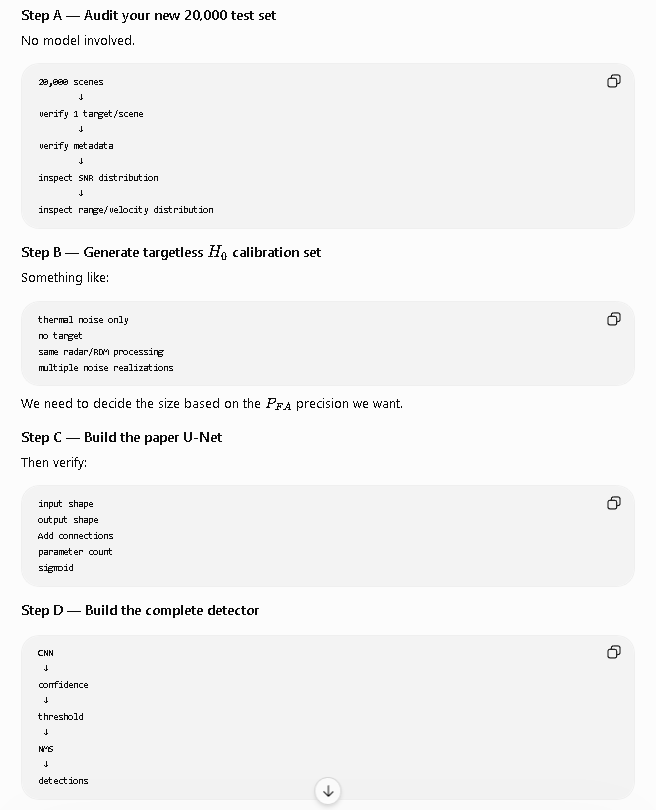

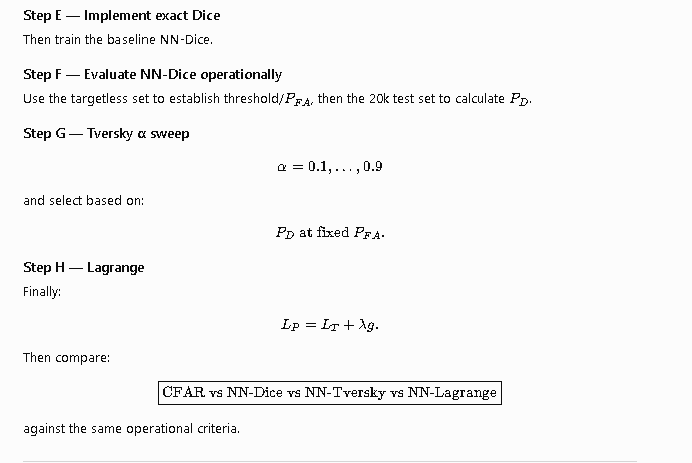

In [ ]:
#test

In [ ]:
from pathlib import Path

TEST_DIR = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/single_target_exoclutter_test"
)

print("Test directory exists:", TEST_DIR.exists())
print("Test directory:", TEST_DIR)

files = sorted(TEST_DIR.iterdir())

print("\nTotal files:", len(files))

for f in files[:20]:
    print(f.name)

if len(files) > 20:
    print("...")
    for f in files[-10:]:
        print(f.name)

Test directory exists: True
Test directory: /content/drive/MyDrive/radar_project/radar_dataset/single_target_exoclutter_test

Total files: 400
metadata_00000_00099.npy
metadata_00100_00199.npy
metadata_00200_00299.npy
metadata_00300_00399.npy
metadata_00400_00499.npy
metadata_00500_00599.npy
metadata_00600_00699.npy
metadata_00700_00799.npy
metadata_00800_00899.npy
metadata_00900_00999.npy
metadata_01000_01099.npy
metadata_01100_01199.npy
metadata_01200_01299.npy
metadata_01300_01399.npy
metadata_01400_01499.npy
metadata_01500_01599.npy
metadata_01600_01699.npy
metadata_01700_01799.npy
metadata_01800_01899.npy
metadata_01900_01999.npy
...
rdm_19000_19099.npy
rdm_19100_19199.npy
rdm_19200_19299.npy
rdm_19300_19399.npy
rdm_19400_19499.npy
rdm_19500_19599.npy
rdm_19600_19699.npy
rdm_19700_19799.npy
rdm_19800_19899.npy
rdm_19900_19999.npy


In [ ]:
import numpy as np
from pathlib import Path

TEST_DIR = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/single_target_exoclutter_test"
)

rdm_files = sorted(TEST_DIR.glob("rdm_*.npy"))

print("RDM batch files:", len(rdm_files))

total_scenes = 0
shape_failures = []
dtype_counts = {}
finite_failures = []
min_values = []
max_values = []

for path in rdm_files:

    data = np.load(path, mmap_mode="r")

    total_scenes += data.shape[0]

    if data.ndim != 3 or data.shape[1:] != (69, 1334):
        shape_failures.append(
            (path.name, data.shape)
        )

    dtype_counts[str(data.dtype)] = (
        dtype_counts.get(str(data.dtype), 0) + 1
    )

    if not np.isfinite(data).all():
        finite_failures.append(path.name)

    min_values.append(float(data.min()))
    max_values.append(float(data.max()))

print("\n" + "="*60)
print("RDM DATASET AUDIT")
print("="*60)

print("Number of batches :", len(rdm_files))
print("Total scenes      :", total_scenes)
print("Expected scenes   :", 20000)

print("\nExpected shape per batch: (100, 69, 1334)")
print("Shape failures:", len(shape_failures))

if shape_failures:
    print(shape_failures[:10])

print("\nDtypes:", dtype_counts)

print("Non-finite batches:", len(finite_failures))

if finite_failures:
    print(finite_failures[:10])

print("\nGlobal minimum dB:", min(min_values))
print("Global maximum dB:", max(max_values))

RDM batch files: 200

RDM DATASET AUDIT
Number of batches : 200
Total scenes      : 20000
Expected scenes   : 20000

Expected shape per batch: (100, 69, 1334)
Shape failures: 0

Dtypes: {'float32': 200}
Non-finite batches: 0

Global minimum dB: -240.0
Global maximum dB: 74.08958435058594


In [ ]:
metadata_files = sorted(TEST_DIR.glob("metadata_*.npy"))

print("Metadata files:", len(metadata_files))

for f in metadata_files[:5]:
    print(f.name)

Metadata files: 200
metadata_00000_00099.npy
metadata_00100_00199.npy
metadata_00200_00299.npy
metadata_00300_00399.npy
metadata_00400_00499.npy


In [ ]:
# Inspect the first metadata batch
meta = np.load(
    metadata_files[0],
    allow_pickle=True
)

print("Metadata shape:", meta.shape)
print("Metadata dtype:", meta.dtype)

print("\nFirst scene metadata:")
print(meta[0])

Metadata shape: (100, 1)
Metadata dtype: object

First scene metadata:
[{'id': 0, 'range_m': 41.84808436607271, 'velocity_mps': -4.604265724722594, 'doppler_hz': -306.95104831483957, 'rcs_dbsm': -9.38539714095708, 'phase_rad': 0.10384619671527331, 'range_bin': np.int64(1116), 'velocity_bin': np.int64(112)}]


In [ ]:
target_counts = []

for path in metadata_files:

    meta = np.load(
        path,
        allow_pickle=True
    )

    for scene in meta:

        # Each scene should contain exactly one target dictionary
        target_counts.append(len(scene))

target_counts = np.asarray(target_counts)

print("Total scenes:", len(target_counts))
print("Minimum targets/scene:", target_counts.min())
print("Maximum targets/scene:", target_counts.max())

unique, counts = np.unique(
    target_counts,
    return_counts=True
)

print("\nTarget-count distribution:")

for n, c in zip(unique, counts):
    print(f"{n} target(s): {c} scenes")

Total scenes: 20000
Minimum targets/scene: 1
Maximum targets/scene: 1

Target-count distribution:
1 target(s): 20000 scenes


In [ ]:
ranges = []
velocities = []
rcs_values = []
dopplers = []

for path in metadata_files:

    meta = np.load(
        path,
        allow_pickle=True
    )

    for scene in meta:

        target = scene[0]

        ranges.append(float(target["range_m"]))
        velocities.append(float(target["velocity_mps"]))
        rcs_values.append(float(target["rcs_dbsm"]))
        dopplers.append(float(target["doppler_hz"]))

ranges = np.asarray(ranges)
velocities = np.asarray(velocities)
rcs_values = np.asarray(rcs_values)
dopplers = np.asarray(dopplers)

print("="*60)
print("TARGET DISTRIBUTION")
print("="*60)

print("\nRange:")
print("  min:", ranges.min())
print("  max:", ranges.max())
print("  mean:", ranges.mean())

print("\nVelocity:")
print("  min:", velocities.min())
print("  max:", velocities.max())
print("  mean:", velocities.mean())

print("\nRCS:")
print("  min:", rcs_values.min())
print("  max:", rcs_values.max())
print("  mean:", rcs_values.mean())

print("\nDoppler:")
print("  min:", dopplers.min())
print("  max:", dopplers.max())

TARGET DISTRIBUTION

Range:
  min: 10.000248373399698
  max: 59.998651639750605
  mean: 34.77482570044429

Velocity:
  min: -9.997524875957977
  max: 9.999715765231553
  mean: 0.06659749890827177

RCS:
  min: -9.999470516931263
  max: 4.999820096128264
  mean: -2.453271690973499

Doppler:
  min: -666.5016583971985
  max: 666.6477176821036


In [ ]:
print("Metadata fields:")
print(meta[0][0].keys())

Metadata fields:
dict_keys(['id', 'range_m', 'velocity_mps', 'doppler_hz', 'rcs_dbsm', 'phase_rad', 'range_bin', 'velocity_bin'])


In [ ]:
import hashlib

hashes = set()
duplicate_count = 0

for path in rdm_files:

    data = np.load(path, mmap_mode="r")

    for scene in data:

        h = hashlib.sha256(
            scene.tobytes()
        ).hexdigest()

        if h in hashes:
            duplicate_count += 1
        else:
            hashes.add(h)

print("Total scenes checked:", len(hashes) + duplicate_count)
print("Duplicate scenes:", duplicate_count)

Total scenes checked: 20000
Duplicate scenes: 0


In [ ]:
import numpy as np
from pathlib import Path

TEST_DIR = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/single_target_exoclutter_test"
)

rdm_files = sorted(TEST_DIR.glob("rdm_*.npy"))

percentiles = [0, 50, 90, 95, 99, 99.9, 99.99, 99.999, 100]

all_stats = []

for path in rdm_files:
    data = np.load(path, mmap_mode="r")

    all_stats.append([
        np.min(data),
        np.max(data),
        np.percentile(data, 99),
        np.percentile(data, 99.9)
    ])

all_stats = np.asarray(all_stats)

print("=" * 70)
print("TEST RDM DYNAMIC-RANGE AUDIT")
print("=" * 70)

print("Minimum across batches :", all_stats[:, 0].min())
print("Maximum across batches :", all_stats[:, 1].max())

print("\nPercentiles of batch-level values:")
print("99th percentile max :", np.percentile(all_stats[:, 2], 99))
print("99.9th percentile max:", np.percentile(all_stats[:, 3], 99))

# Count scenes with values above important levels
count_gt_0 = 0
count_gt_20 = 0
count_gt_40 = 0
count_gt_60 = 0
total_scenes = 0

for path in rdm_files:
    data = np.load(path, mmap_mode="r")

    count_gt_0 += np.sum(np.max(data, axis=(1, 2)) > 0)
    count_gt_20 += np.sum(np.max(data, axis=(1, 2)) > 20)
    count_gt_40 += np.sum(np.max(data, axis=(1, 2)) > 40)
    count_gt_60 += np.sum(np.max(data, axis=(1, 2)) > 60)

    total_scenes += data.shape[0]

print("\nScenes whose maximum exceeds:")
print(f"   0 dB : {count_gt_0} / {total_scenes}")
print(f"  20 dB : {count_gt_20} / {total_scenes}")
print(f"  40 dB : {count_gt_40} / {total_scenes}")
print(f"  60 dB : {count_gt_60} / {total_scenes}")

TEST RDM DYNAMIC-RANGE AUDIT
Minimum across batches : -240.0
Maximum across batches : 74.089584

Percentiles of batch-level values:
99th percentile max : -0.7682159
99.9th percentile max: 22.224495

Scenes whose maximum exceeds:
   0 dB : 19998 / 20000
  20 dB : 18228 / 20000
  40 dB : 6171 / 20000
  60 dB : 348 / 20000


In [ ]:
c = 3e8
B = 4e9

range_axis_roi = np.linspace(
    10.0125,
    60.0,
    1334
)

vel_axis_roi = np.linspace(
    -9.9609375,
    9.9609375,
    69
)

print("Range axis:", range_axis_roi[0], range_axis_roi[-1], len(range_axis_roi))
print("Velocity axis:", vel_axis_roi[0], vel_axis_roi[-1], len(vel_axis_roi))

Range axis: 10.0125 60.0 1334
Velocity axis: -9.9609375 9.9609375 69


In [ ]:
def target_native_index(target):

    R = target["range_m"]
    v = target["velocity_mps"]

    r_idx = np.argmin(
        np.abs(range_axis_roi - R)
    )

    v_idx = np.argmin(
        np.abs(vel_axis_roi - v)
    )

    return v_idx, r_idx

In [ ]:
metadata_files = sorted(TEST_DIR.glob("metadata_*.npy"))

test_indices = [0, 1, 100, 1000, 5000, 10000, 15000, 19999]

for global_idx in test_indices:

    batch_idx = global_idx // 100
    local_idx = global_idx % 100

    rdm = np.load(
        rdm_files[batch_idx],
        mmap_mode="r"
    )[local_idx]

    metadata = np.load(
        metadata_files[batch_idx],
        allow_pickle=True
    )[local_idx]

    target = metadata[0]

    v_idx, r_idx = target_native_index(target)

    # 5x5 local neighborhood
    r0 = max(0, r_idx - 2)
    r1 = min(rdm.shape[1], r_idx + 3)

    v0 = max(0, v_idx - 2)
    v1 = min(rdm.shape[0], v_idx + 3)

    local = rdm[v0:v1, r0:r1]

    local_peak = np.unravel_index(
        np.argmax(local),
        local.shape
    )

    peak_v = v0 + local_peak[0]
    peak_r = r0 + local_peak[1]

    print(
        f"Scene {global_idx:5d} | "
        f"target=(v={v_idx}, r={r_idx}) | "
        f"local peak=(v={peak_v}, r={peak_r}) | "
        f"target value={rdm[v_idx,r_idx]:.2f} dB | "
        f"local max={rdm[peak_v,peak_r]:.2f} dB"
    )

Scene     0 | target=(v=18, r=849) | local peak=(v=16, r=848) | target value=18.41 dB | local max=21.77 dB
Scene     1 | target=(v=65, r=682) | local peak=(v=67, r=684) | target value=17.78 dB | local max=20.09 dB
Scene   100 | target=(v=41, r=1113) | local peak=(v=42, r=1114) | target value=24.98 dB | local max=29.56 dB
Scene  1000 | target=(v=41, r=695) | local peak=(v=43, r=696) | target value=32.76 dB | local max=37.75 dB
Scene  5000 | target=(v=24, r=73) | local peak=(v=23, r=71) | target value=54.98 dB | local max=57.84 dB
Scene 10000 | target=(v=29, r=689) | local peak=(v=28, r=688) | target value=31.84 dB | local max=41.59 dB
Scene 15000 | target=(v=29, r=322) | local peak=(v=29, r=321) | target value=46.85 dB | local max=51.95 dB
Scene 19999 | target=(v=15, r=568) | local peak=(v=14, r=566) | target value=33.53 dB | local max=37.92 dB


In [ ]:
offsets = []
target_values = []
local_peaks = []

for batch_idx, (rdm_path, meta_path) in enumerate(
    zip(rdm_files, metadata_files)
):

    rdms = np.load(rdm_path, mmap_mode="r")
    metas = np.load(meta_path, allow_pickle=True)

    for local_idx in range(len(rdms)):

        rdm = rdms[local_idx]
        target = metas[local_idx][0]

        v_idx, r_idx = target_native_index(target)

        v0 = max(0, v_idx - 3)
        v1 = min(rdm.shape[0], v_idx + 4)

        r0 = max(0, r_idx - 3)
        r1 = min(rdm.shape[1], r_idx + 4)

        local = rdm[v0:v1, r0:r1]

        peak = np.unravel_index(
            np.argmax(local),
            local.shape
        )

        peak_v = v0 + peak[0]
        peak_r = r0 + peak[1]

        offsets.append([
            peak_v - v_idx,
            peak_r - r_idx
        ])

        target_values.append(
            rdm[v_idx, r_idx]
        )

        local_peaks.append(
            rdm[peak_v, peak_r]
        )

offsets = np.asarray(offsets)
target_values = np.asarray(target_values)
local_peaks = np.asarray(local_peaks)

print("=" * 70)
print("TARGET / RDM CONSISTENCY")
print("=" * 70)

print("Scenes:", len(offsets))

print("\nVelocity-bin offset:")
print(" mean:", offsets[:,0].mean())
print(" std :", offsets[:,0].std())
print(" max :", np.max(np.abs(offsets[:,0])))

print("\nRange-bin offset:")
print(" mean:", offsets[:,1].mean())
print(" std :", offsets[:,1].std())
print(" max :", np.max(np.abs(offsets[:,1])))

print("\nTarget-pixel value:")
print(" median:", np.median(target_values))
print(" mean  :", np.mean(target_values))
print(" min   :", np.min(target_values))
print(" max   :", np.max(target_values))

print("\nLocal 7x7 peak value:")
print(" median:", np.median(local_peaks))
print(" mean  :", np.mean(local_peaks))
print(" min   :", np.min(local_peaks))
print(" max   :", np.max(local_peaks))

TARGET / RDM CONSISTENCY
Scenes: 20000

Velocity-bin offset:
 mean: 0.0861
 std : 1.9540692899690124
 max : 3

Range-bin offset:
 mean: -0.08505
 std : 2.06497372804111
 max : 3

Target-pixel value:
 median: 28.253153
 mean  : 25.666367
 min   : -239.9961
 max   : 74.089584

Local 7x7 peak value:
 median: 33.645416
 mean  : 34.518944
 min   : -15.900305
 max   : 74.089584


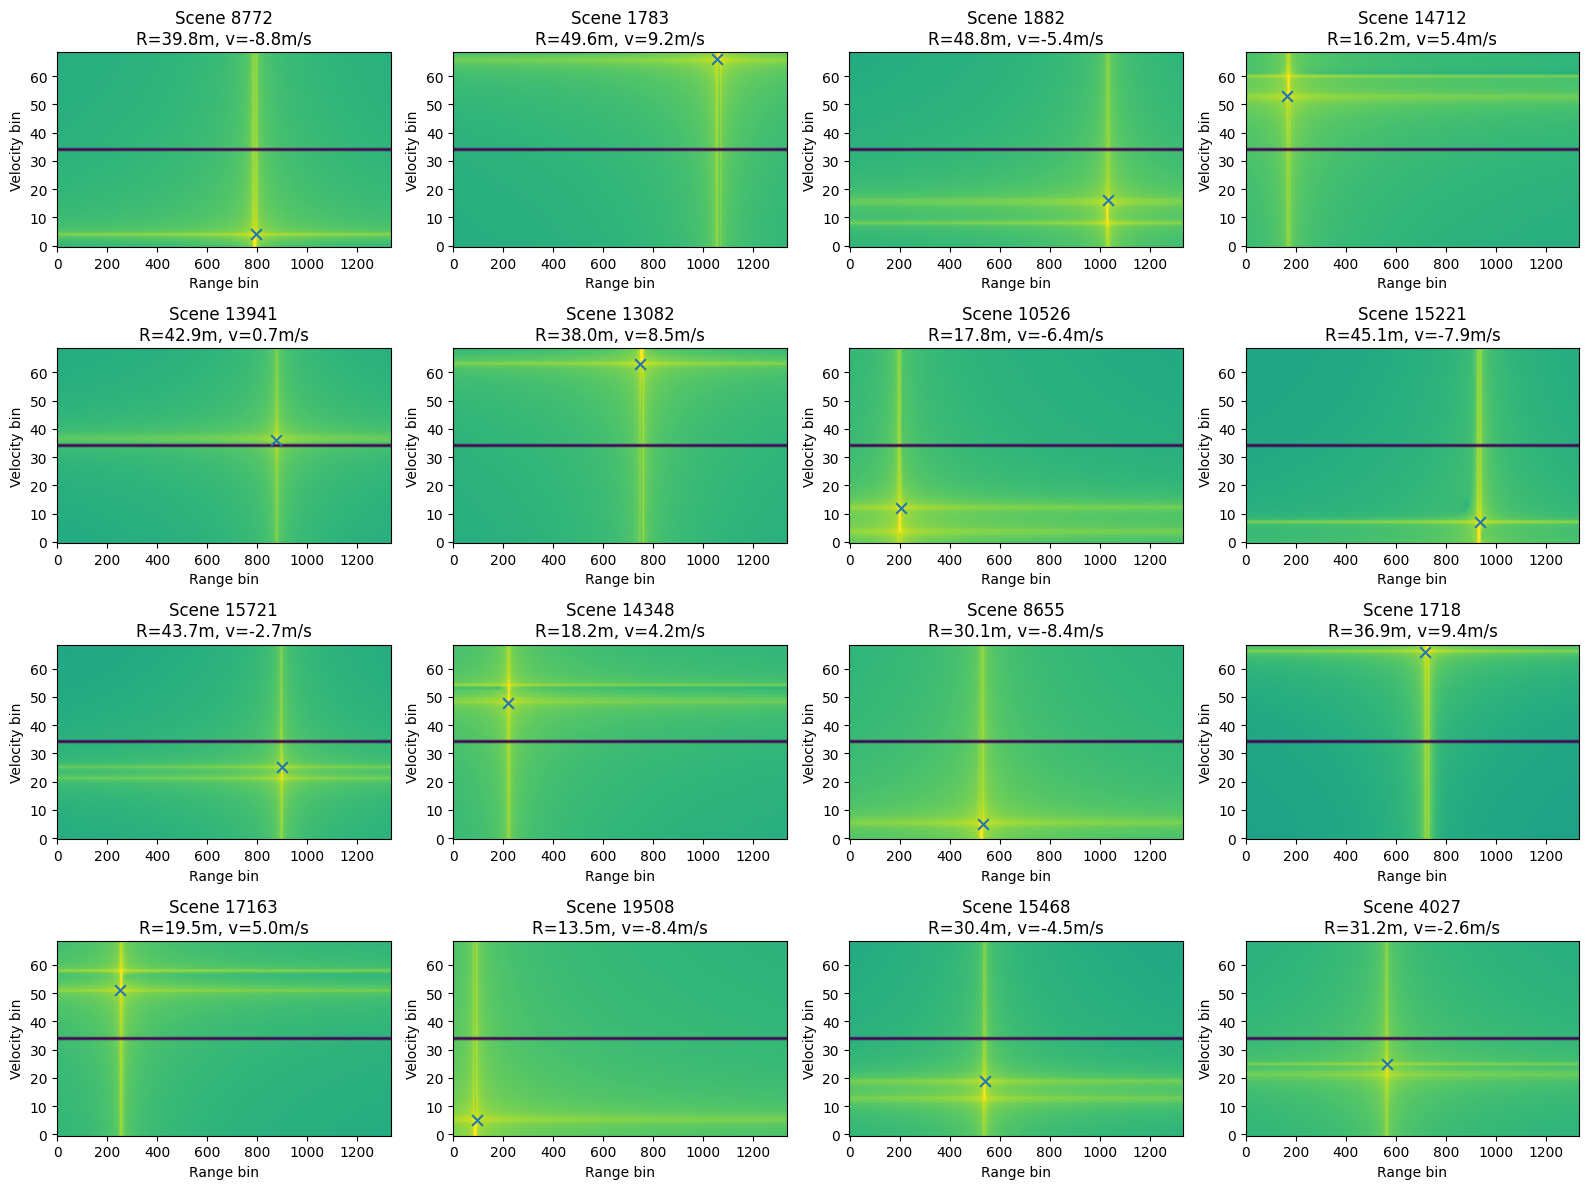

In [ ]:
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

selected = rng.choice(
    20000,
    size=16,
    replace=False
)

fig, axes = plt.subplots(4, 4, figsize=(16, 12))

for ax, global_idx in zip(axes.flat, selected):

    batch_idx = global_idx // 100
    local_idx = global_idx % 100

    rdm = np.load(
        rdm_files[batch_idx],
        mmap_mode="r"
    )[local_idx]

    meta = np.load(
        metadata_files[batch_idx],
        allow_pickle=True
    )[local_idx][0]

    v_idx, r_idx = target_native_index(meta)

    ax.imshow(
        rdm,
        aspect="auto",
        origin="lower"
    )

    ax.scatter(
        r_idx,
        v_idx,
        marker="x",
        s=60
    )

    ax.set_title(
        f"Scene {global_idx}\n"
        f"R={meta['range_m']:.1f}m, "
        f"v={meta['velocity_mps']:.1f}m/s"
    )

    ax.set_xlabel("Range bin")
    ax.set_ylabel("Velocity bin")

plt.tight_layout()
plt.show()

In [ ]:
# Raw training RDM statistics
train_rdm_files = sorted(
    (PROJECT_DIR / "radar_dataset").glob("rdm_*.npy")
)

train_raw_min = np.inf
train_raw_max = -np.inf

for path in train_rdm_files:
    data = np.load(path, mmap_mode="r")
    train_raw_min = min(train_raw_min, float(data.min()))
    train_raw_max = max(train_raw_max, float(data.max()))

print("TRAINING RAW")
print("min:", train_raw_min)
print("max:", train_raw_max)

print("\nTEST RAW")
print("min:", all_stats[:, 0].min())
print("max:", all_stats[:, 1].max())

TRAINING RAW
min: -240.0
max: 72.74751281738281

TEST RAW
min: -240.0
max: 74.089584


In [ ]:
def preprocess_rdm(rdm_db):
    rdm_db = np.clip(rdm_db, -40.0, 0.0)
    return (rdm_db + 40.0) / 40.0

discard the previous generated dataset it does not follows the NP defintion

In [ ]:
def generate_noise_scene(noise_power, seed=None):
    rng = np.random.default_rng(seed)

    # H0: thermal noise only
    noise = (
        rng.standard_normal((N_slow, N_fast))
        + 1j * rng.standard_normal((N_slow, N_fast))
    ) / np.sqrt(2)

    noise *= np.sqrt(noise_power)

    # Range processing
    range_fft = np.fft.fft(noise, axis=1)
    range_fft = range_fft[:, :N_fast // 2]

    # Same stationary-mean removal as the target scenes
    range_fft -= np.mean(range_fft, axis=0)

    # Doppler processing
    rdm = np.fft.fftshift(
        np.fft.fft(range_fft, axis=0),
        axes=0
    )

    return rdm

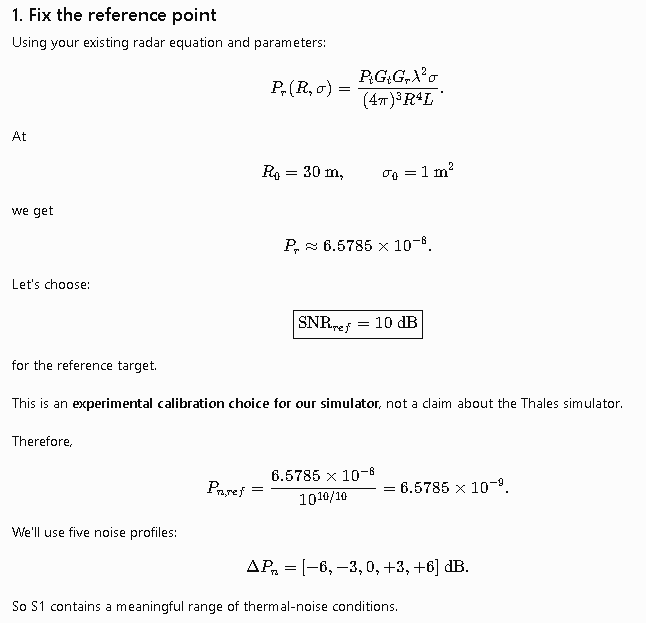

In [ ]:
# ============================================================
# S1 reference thermal-noise calibration
# ============================================================

R_ref = 30.0                 # m
rcs_ref_m2 = 1.0             # m^2
snr_ref_db = 10.0            # dB
c=3e8; fc=10e9; lam=c/fc
Gtx=10**(11.6/10); Ptx=1000; L=10**(2.5/10)
Grx=10**(11.6/10)
R=30; sigma=1
Ptx=1000

# Radar equation
Pr_ref = (
    Ptx
    * Gtx
    * Grx
    * lambda_c**2
    * rcs_ref_m2
    / ((4 * np.pi)**3 * R_ref**4 * L)
)

# Reference complex-sample noise power
noise_power_ref = Pr_ref / (10**(snr_ref_db / 10))

print(f"Reference range       : {R_ref:.1f} m")
print(f"Reference RCS         : {rcs_ref_m2:.2f} m^2")
print(f"Reference received P  : {Pr_ref:.6e}")
print(f"Reference received P  : {10*np.log10(Pr_ref):.3f} dB")
print(f"Reference SNR         : {snr_ref_db:.1f} dB")
print(f"Reference noise power : {noise_power_ref:.6e}")

noise_offsets_db = np.array([-6, -3, 0, 3, 6], dtype=np.float32)

noise_powers = noise_power_ref * 10**(noise_offsets_db / 10)

print("\nS1 noise profiles:")
for offset, pn in zip(noise_offsets_db, noise_powers):
    print(f"{offset:+.0f} dB : noise_power = {pn:.6e}")

Reference range       : 30.0 m
Reference RCS         : 1.00 m^2
Reference received P  : 6.578515e-08
Reference received P  : -71.819 dB
Reference SNR         : 10.0 dB
Reference noise power : 6.578515e-09

S1 noise profiles:
-6 dB : noise_power = 1.652448e-09
-3 dB : noise_power = 3.297068e-09
+0 dB : noise_power = 6.578516e-09
+3 dB : noise_power = 1.312586e-08
+6 dB : noise_power = 2.618954e-08


In [ ]:
def generate_noise_scene(noise_power, seed=None):
    """
    Generate one targetless H0 radar scene.

    H0:
        y(t) = n(t)

    Returns the same native ROI representation used by
    the existing radar datasets:

        velocity bins × range bins
        = (69, 1334)
    """

    rng = np.random.default_rng(seed)

    # --------------------------------------------------------
    # H0: thermal noise only
    # --------------------------------------------------------
    noise = (
        rng.standard_normal((N_slow, N_fast))
        + 1j * rng.standard_normal((N_slow, N_fast))
    ) / np.sqrt(2)

    noise *= np.sqrt(noise_power)

    # --------------------------------------------------------
    # Range processing
    # --------------------------------------------------------
    range_fft = np.fft.fft(noise, axis=1)

    # Positive-frequency half
    range_fft = range_fft[:, :N_fast // 2]

    # Same stationary mean removal
    range_fft -= np.mean(range_fft, axis=0)

    # --------------------------------------------------------
    # Doppler processing
    # --------------------------------------------------------
    rdm_complex = np.fft.fftshift(
        np.fft.fft(range_fft, axis=0),
        axes=0
    )

    # --------------------------------------------------------
    # Physical ROI
    # --------------------------------------------------------
    range_mask = (
        (range_axis >= 10.0) &
        (range_axis <= 60.0)
    )

    velocity_mask = (
        (vel_axis >= -10.0) &
        (vel_axis <= 10.0)
    )

    rdm_roi = rdm_complex[
        velocity_mask,
        :
    ][:, range_mask]

    return rdm_roi

In [ ]:
rdm_test = generate_noise_scene(
    noise_power=noise_power_ref,
    seed=123
)

print("S1 RDM shape:", rdm_test.shape)
print("Expected shape:", (69, 1334))
print("Finite:", np.isfinite(rdm_test).all())

rdm_test_db = 20 * np.log10(np.abs(rdm_test) + 1e-12)

print("dB shape:", rdm_test_db.shape)
print("Min dB:", rdm_test_db.min())
print("Max dB:", rdm_test_db.max())
print("Mean dB:", rdm_test_db.mean())

S1 RDM shape: (69, 1334)
Expected shape: (69, 1334)
Finite: True
dB shape: (69, 1334)
Min dB: -240.0
Max dB: -9.032946635996755
Mean dB: -25.338541331020927


In [ ]:
# ============================================================
# Validate one S1 noise scene
# ============================================================

test_noise_power = noise_power_ref

rdm_test = generate_noise_scene(
    noise_power=test_noise_power,
    seed=123
)

print("RDM shape:", rdm_test.shape)
print("RDM dtype:", rdm_test.dtype)
print("Finite:", np.isfinite(rdm_test).all())

# Estimate complex-domain power before/after processing
rdm_power = np.mean(np.abs(rdm_test)**2)

print(f"Mean processed RDM power: {rdm_power:.6e}")
print(f"Input noise power       : {test_noise_power:.6e}")
print(f"RDM power / noise power : {rdm_power / test_noise_power:.3f}")

RDM shape: (69, 1334)
RDM dtype: complex128
Finite: True
Mean processed RDM power: 1.060970e-02
Input noise power       : 6.578515e-09
RDM power / noise power : 1612779.553


In [ ]:
rdm_test_db = 20 * np.log10(np.abs(rdm_test) + 1e-12)

print("RDM dB shape :", rdm_test_db.shape)
print("Min dB       :", rdm_test_db.min())
print("Max dB       :", rdm_test_db.max())
print("Mean dB      :", rdm_test_db.mean())

RDM dB shape : (69, 1334)
Min dB       : -240.0
Max dB       : -9.032946635996755
Mean dB      : -25.338541331020927


In [ ]:
# ============================================================
# GPU-based H0 / S1 scene generator
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Constants as torch tensors/scalars
N_SLOW = N_slow
N_FAST = N_fast

# Masks corresponding to the existing 69 x 1334 native ROI
range_mask_t = torch.tensor(
    (range_axis >= 10.0) & (range_axis <= 60.0),
    dtype=torch.bool,
    device=device
)

velocity_mask_t = torch.tensor(
    (vel_axis >= -10.0) & (vel_axis <= 10.0),
    dtype=torch.bool,
    device=device
)

print("Device:", device)
print("Velocity ROI bins:", velocity_mask_t.sum().item())
print("Range ROI bins:", range_mask_t.sum().item())

Device: cuda
Velocity ROI bins: 69
Range ROI bins: 1334


In [ ]:
def generate_noise_scene_gpu(noise_power, seed=None):
    """
    GPU implementation of H0:

        y(t) = n(t)

    Returns:
        complex RDM ROI of shape (69, 1334)
    """

    if seed is not None:
        torch.manual_seed(int(seed))

    # --------------------------------------------------------
    # H0: complex circular Gaussian thermal noise
    # --------------------------------------------------------

    noise = (
        torch.randn(
            (N_SLOW, N_FAST),
            dtype=torch.float32,
            device=device
        )
        +
        1j * torch.randn(
            (N_SLOW, N_FAST),
            dtype=torch.float32,
            device=device
        )
    ) / np.sqrt(2)

    noise *= np.sqrt(noise_power)

    # --------------------------------------------------------
    # Range FFT
    # --------------------------------------------------------

    range_fft = torch.fft.fft(noise, dim=1)

    range_fft = range_fft[:, :N_FAST // 2]

    # Same stationary mean removal
    range_fft = range_fft - torch.mean(
        range_fft,
        dim=0,
        keepdim=True
    )

    # --------------------------------------------------------
    # Doppler FFT + shift
    # --------------------------------------------------------

    rdm = torch.fft.fftshift(
        torch.fft.fft(range_fft, dim=0),
        dim=0
    )

    # --------------------------------------------------------
    # Physical ROI
    # --------------------------------------------------------

    rdm_roi = rdm[
        velocity_mask_t
    ][:, range_mask_t]

    return rdm_roi

In [ ]:
# ============================================================
# Generate S1 on GPU
# ============================================================

from pathlib import Path
import numpy as np
import torch

S1_DIR = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/S1_targetless_thermal_noise"
)

S1_DIR.mkdir(parents=True, exist_ok=True)

SCENES_PER_PROFILE = 4000
BATCH_SIZE = 100

scene_id = 0

for profile_idx, (offset_db, noise_power) in enumerate(
    zip(noise_offsets_db, noise_powers)
):

    print(
        f"\nProfile {profile_idx + 1}/5 | "
        f"noise offset = {offset_db:+.0f} dB | "
        f"noise power = {noise_power:.6e}"
    )

    profile_start = scene_id
    profile_end = scene_id + SCENES_PER_PROFILE

    while scene_id < profile_end:

        batch_end = min(
            scene_id + BATCH_SIZE,
            profile_end
        )

        batch_size = batch_end - scene_id

        # ----------------------------------------------------
        # Generate complex Gaussian noise directly on GPU
        # ----------------------------------------------------

        noise = (
            torch.randn(
                (batch_size, N_SLOW, N_FAST),
                dtype=torch.float32,
                device=device
            )
            +
            1j * torch.randn(
                (batch_size, N_SLOW, N_FAST),
                dtype=torch.float32,
                device=device
            )
        ) / np.sqrt(2)

        noise *= np.sqrt(noise_power)

        # ----------------------------------------------------
        # Range FFT
        # ----------------------------------------------------

        range_fft = torch.fft.fft(
            noise,
            dim=2
        )

        range_fft = range_fft[:, :, :N_FAST // 2]

        # ----------------------------------------------------
        # Stationary mean removal
        # ----------------------------------------------------

        range_fft = range_fft - torch.mean(
            range_fft,
            dim=1,
            keepdim=True
        )

        # ----------------------------------------------------
        # Doppler FFT
        # ----------------------------------------------------

        rdm = torch.fft.fftshift(
            torch.fft.fft(
                range_fft,
                dim=1
            ),
            dim=1
        )

        # ----------------------------------------------------
        # Extract native ROI
        # ----------------------------------------------------

        rdm_roi = rdm[
            :,
            velocity_mask_t,
            :
        ][:, :, range_mask_t]

        # ----------------------------------------------------
        # Convert to dB
        # ----------------------------------------------------

        rdm_db = 20 * torch.log10(
            torch.abs(rdm_roi) + 1e-12
        )

        # GPU -> CPU
        rdm_batch = (
            rdm_db
            .float()
            .cpu()
            .numpy()
        )

        # ----------------------------------------------------
        # Zero labels: H0 contains no targets
        # ----------------------------------------------------

        labels_batch = np.zeros(
            (batch_size, 256, 256),
            dtype=np.float32
        )

        # ----------------------------------------------------
        # Metadata
        # ----------------------------------------------------

        metadata_batch = []

        for i in range(batch_size):

            current_id = scene_id + i

            metadata_batch.append({
                "id": int(current_id),
                "hypothesis": "H0",
                "noise_profile": int(profile_idx),
                "noise_offset_db": float(offset_db),
                "noise_power": float(noise_power),
            })

        # ----------------------------------------------------
        # Save
        # ----------------------------------------------------

        start_id = scene_id
        end_id = batch_end - 1

        np.save(
            S1_DIR / f"rdm_{start_id:05d}_{end_id:05d}.npy",
            rdm_batch
        )

        np.save(
            S1_DIR / f"labels_{start_id:05d}_{end_id:05d}.npy",
            labels_batch
        )

        np.save(
            S1_DIR / f"metadata_{start_id:05d}_{end_id:05d}.npy",
            np.array(
                metadata_batch,
                dtype=object
            )
        )

        scene_id = batch_end

        # Release GPU tensors before next batch
        del noise, range_fft, rdm, rdm_roi, rdm_db

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        if scene_id % 500 == 0:
            print(
                f"  Generated {scene_id}/{5 * SCENES_PER_PROFILE}"
            )

    print(
        f"Generated scenes "
        f"{profile_start}–{profile_end - 1}"
    )

print("\nS1 generation complete.")
print("Total scenes:", scene_id)
print("Location:", S1_DIR)


Profile 1/5 | noise offset = -6 dB | noise power = 1.652448e-09
  Generated 500/20000
  Generated 1000/20000
  Generated 1500/20000
  Generated 2000/20000
  Generated 2500/20000
  Generated 3000/20000
  Generated 3500/20000
  Generated 4000/20000
Generated scenes 0–3999

Profile 2/5 | noise offset = -3 dB | noise power = 3.297068e-09
  Generated 4500/20000
  Generated 5000/20000
  Generated 5500/20000
  Generated 6000/20000
  Generated 6500/20000
  Generated 7000/20000
  Generated 7500/20000
  Generated 8000/20000
Generated scenes 4000–7999

Profile 3/5 | noise offset = +0 dB | noise power = 6.578516e-09
  Generated 8500/20000
  Generated 9000/20000
  Generated 9500/20000
  Generated 10000/20000
  Generated 10500/20000
  Generated 11000/20000
  Generated 11500/20000
  Generated 12000/20000
Generated scenes 8000–11999

Profile 4/5 | noise offset = +3 dB | noise power = 1.312586e-08
  Generated 12500/20000
  Generated 13000/20000
  Generated 13500/20000
  Generated 14000/20000
  Generat

In [ ]:
# ============================================================
# S1 audit
# ============================================================

files = sorted(S1_DIR.glob("rdm_*.npy"))

print("Number of RDM batches:", len(files))

total_scenes = 0

for f in files[:3]:
    x = np.load(f, mmap_mode="r")

    print(
        f.name,
        "| shape:", x.shape,
        "| dtype:", x.dtype,
        "| min:", x.min(),
        "| max:", x.max(),
        "| finite:", np.isfinite(x).all()
    )

    total_scenes += x.shape[0]

print("First 3 batches contain:", total_scenes, "scenes")

Number of RDM batches: 200
rdm_00000_00099.npy | shape: (100, 69, 1334) | dtype: float32 | min: -240.0 | max: -13.6204 | finite: True
rdm_00100_00199.npy | shape: (100, 69, 1334) | dtype: float32 | min: -240.0 | max: -13.434697 | finite: True
rdm_00200_00299.npy | shape: (100, 69, 1334) | dtype: float32 | min: -240.0 | max: -13.248325 | finite: True
First 3 batches contain: 300 scenes


In [ ]:
label_files = sorted(S1_DIR.glob("labels_*.npy"))

all_zero = True

for f in label_files:
    y = np.load(f, mmap_mode="r")

    if np.any(y != 0):
        all_zero = False
        print("NONZERO LABEL FOUND:", f)
        break

print("All S1 labels zero:", all_zero)

All S1 labels zero: True


In [ ]:
# ============================================================
# Check noise-profile ordering
# ============================================================

profile_means = []

for profile_idx in range(5):

    start = profile_idx * 4000
    file_idx = start // 100

    x = np.load(
        rdm_files[file_idx],
        mmap_mode="r"
    )

    # Mean linear power of the stored RDM
    power = np.mean(
        10 ** (x.astype(np.float64) / 10)
    )

    profile_means.append(power)

    print(
        f"Profile {profile_idx}: "
        f"mean RDM power = {power:.6e}"
    )

print("\nMonotonically increasing:",
      all(
          profile_means[i] < profile_means[i+1]
          for i in range(4)
      ))

Profile 0: mean RDM power = 3.427125e+00
Profile 1: mean RDM power = 7.290326e+00
Profile 2: mean RDM power = 1.167275e+01
Profile 3: mean RDM power = 9.975948e+00
Profile 4: mean RDM power = 4.978413e+00

Monotonically increasing: False


In [ ]:
# ============================================================
# Verify S1 metadata at profile boundaries
# ============================================================

for profile_idx in range(5):

    start_id = profile_idx * 4000
    end_id = start_id + 3999

    # Metadata file containing the first scene of this profile
    first_file_start = (start_id // 100) * 100

    metadata_file = S1_DIR / (
        f"metadata_{first_file_start:05d}_{first_file_start + 99:05d}.npy"
    )

    metadata = np.load(
        metadata_file,
        allow_pickle=True
    )

    offsets = np.array([
        m["noise_offset_db"] for m in metadata
    ])

    powers = np.array([
        m["noise_power"] for m in metadata
    ])

    print(
        f"Profile {profile_idx}: "
        f"first batch = {metadata_file.name} | "
        f"offset = {np.unique(offsets)} | "
        f"noise power = {np.unique(powers)}"
    )

Profile 0: first batch = metadata_00000_00099.npy | offset = [-6.] | noise power = [1.65244829e-09]
Profile 1: first batch = metadata_04000_04099.npy | offset = [-3.] | noise power = [3.29706773e-09]
Profile 2: first batch = metadata_08000_08099.npy | offset = [0.] | noise power = [6.57851551e-09]
Profile 3: first batch = metadata_12000_12099.npy | offset = [3.] | noise power = [1.31258648e-08]
Profile 4: first batch = metadata_16000_16099.npy | offset = [6.] | noise power = [2.6189543e-08]


In [ ]:
test_seed = 12345

measured_powers = []

for offset_db, noise_power in zip(
    noise_offsets_db,
    noise_powers
):
    rdm = generate_noise_scene_gpu(
        noise_power=noise_power,
        seed=test_seed
    )

    power = torch.mean(torch.abs(rdm)**2).item()
    measured_powers.append(power)

    print(
        f"{offset_db:+.0f} dB | "
        f"specified Pn = {noise_power:.6e} | "
        f"measured RDM power = {power:.6e}"
    )

reference_power = measured_powers[2]

print("\nRelative measured power:")

for offset_db, measured_power in zip(
    noise_offsets_db,
    measured_powers
):
    ratio_db = 10 * np.log10(
        measured_power / reference_power
    )

    print(
        f"{offset_db:+.0f} dB -> {ratio_db:+.3f} dB"
    )

-6 dB | specified Pn = 1.652448e-09 | measured RDM power = 2.661920e-03
-3 dB | specified Pn = 3.297068e-09 | measured RDM power = 5.311229e-03
+0 dB | specified Pn = 6.578516e-09 | measured RDM power = 1.059730e-02
+3 dB | specified Pn = 1.312586e-08 | measured RDM power = 2.114438e-02
+6 dB | specified Pn = 2.618954e-08 | measured RDM power = 4.218859e-02

Relative measured power:
-6 dB -> -6.000 dB
-3 dB -> -3.000 dB
+0 dB -> +0.000 dB
+3 dB -> +3.000 dB
+6 dB -> +6.000 dB


In [ ]:
# ============================================================
# H1 SNR ↔ RCS calibration
# ============================================================

# We will use the 0 dB S1 profile as the reference thermal
# noise condition for defining the H1 target SNR.
Pn_ref = noise_power_ref

# Candidate operational SNR range
snr_grid_db = np.array([
    -10, -5, 0, 5, 10, 15, 20, 25, 30
], dtype=float)

# Representative target ranges
range_grid_m = np.array([
    10, 20, 30, 40, 50, 60
], dtype=float)

def required_rcs_m2(range_m, snr_db, noise_power=Pn_ref):
    """
    RCS required to produce a specified raw-sample SNR:

        SNR = Pr / Pn

    where

        Pr = Pt Gt Gr lambda^2 sigma
             -------------------------
             (4 pi)^3 R^4 L
    """

    target_power = noise_power * 10**(snr_db / 10)

    rcs = (
        target_power
        * (4 * np.pi)**3
        * range_m**4
        * L
        / (
            Ptx
            * Gtx
            * Grx
            * lambda_c**2
        )
    )

    return rcs


print("Required RCS for target SNR")
print("=" * 65)

for R in range_grid_m:

    print(f"\nRange = {R:.0f} m")

    for snr_db in snr_grid_db:

        rcs_m2 = required_rcs_m2(R, snr_db)

        rcs_dbsm = 10 * np.log10(rcs_m2)

        print(
            f"  SNR = {snr_db:+3.0f} dB"
            f" -> RCS = {rcs_m2:.6e} m²"
            f" ({rcs_dbsm:+.2f} dBsm)"
        )

Required RCS for target SNR

Range = 10 m
  SNR = -10 dB -> RCS = 1.234568e-04 m² (-39.08 dBsm)
  SNR =  -5 dB -> RCS = 3.904046e-04 m² (-34.08 dBsm)
  SNR =  +0 dB -> RCS = 1.234568e-03 m² (-29.08 dBsm)
  SNR =  +5 dB -> RCS = 3.904046e-03 m² (-24.08 dBsm)
  SNR = +10 dB -> RCS = 1.234568e-02 m² (-19.08 dBsm)
  SNR = +15 dB -> RCS = 3.904046e-02 m² (-14.08 dBsm)
  SNR = +20 dB -> RCS = 1.234568e-01 m² (-9.08 dBsm)
  SNR = +25 dB -> RCS = 3.904046e-01 m² (-4.08 dBsm)
  SNR = +30 dB -> RCS = 1.234568e+00 m² (+0.92 dBsm)

Range = 20 m
  SNR = -10 dB -> RCS = 1.975309e-03 m² (-27.04 dBsm)
  SNR =  -5 dB -> RCS = 6.246474e-03 m² (-22.04 dBsm)
  SNR =  +0 dB -> RCS = 1.975309e-02 m² (-17.04 dBsm)
  SNR =  +5 dB -> RCS = 6.246474e-02 m² (-12.04 dBsm)
  SNR = +10 dB -> RCS = 1.975309e-01 m² (-7.04 dBsm)
  SNR = +15 dB -> RCS = 6.246474e-01 m² (-2.04 dBsm)
  SNR = +20 dB -> RCS = 1.975309e+00 m² (+2.96 dBsm)
  SNR = +25 dB -> RCS = 6.246474e+00 m² (+7.96 dBsm)
  SNR = +30 dB -> RCS = 1.975309e

In [ ]:
# ============================================================
# H1 sanity test: one target + thermal noise
# ============================================================

def generate_h1_test_scene(
    range_m=30.0,
    velocity_mps=0.0,
    rcs_dbsm=0.0,
    noise_power=noise_power_ref,
    seed=123
):
    """
    Controlled H1 sanity test.

    H1:
        y(t) = x(t) + n(t)

    Target:
        R = 30 m
        v = 0 m/s
        RCS = 0 dBsm = 1 m^2
    """

    rng = np.random.default_rng(seed)

    radar_cube = np.zeros(
        (N_slow, N_fast),
        dtype=np.complex128
    )

    # --------------------------------------------------------
    # Target
    # --------------------------------------------------------

    phase = rng.uniform(0, 2 * np.pi)

    R0 = range_m
    v = velocity_mps

    R = R0 + v * t_slow

    tau = 2 * R / c

    fb = Slope * tau

    fd = 2 * v / lambda_c

    A = received_amplitude(
        R=R,
        rcs_dbsm=rcs_dbsm,
        P_tx=Ptx,
        G_tx=Gtx,
        G_rx=Grx,
        lambda_c=lambda_c,
        L=L
    )

    beat = (
        A[:, None]
        * np.exp(
            1j * (
                2 * np.pi
                * (
                    fb[:, None] * t_fast[None, :]
                    + fd * t_slow[:, None]
                )
                + phase
            )
        )
    )

    radar_cube += beat

    # --------------------------------------------------------
    # Thermal noise
    # --------------------------------------------------------

    noise = (
        rng.standard_normal(radar_cube.shape)
        + 1j * rng.standard_normal(radar_cube.shape)
    ) / np.sqrt(2)

    noise *= np.sqrt(noise_power)

    radar_cube += noise

    # --------------------------------------------------------
    # Same processing as existing simulator
    # --------------------------------------------------------

    range_fft = np.fft.fft(
        radar_cube,
        axis=1
    )

    range_fft = range_fft[:, :N_fast // 2]

    range_fft -= np.mean(
        range_fft,
        axis=0
    )

    rdm = np.fft.fftshift(
        np.fft.fft(
            range_fft,
            axis=0
        ),
        axes=0
    )

    # --------------------------------------------------------
    # ROI
    # --------------------------------------------------------

    range_mask = (
        (range_axis >= 10.0)
        & (range_axis <= 60.0)
    )

    velocity_mask = (
        (vel_axis >= -10.0)
        & (vel_axis <= 10.0)
    )

    rdm_roi = rdm[
        velocity_mask,
        :
    ][:, range_mask]

    # --------------------------------------------------------
    # Theoretical raw-sample SNR
    # --------------------------------------------------------

    sigma_m2 = 10 ** (rcs_dbsm / 10)

    Pr = (
        Ptx
        * Gtx
        * Grx
        * lambda_c**2
        * sigma_m2
        / (
            (4 * np.pi)**3
            * range_m**4
            * L
        )
    )

    snr_db = 10 * np.log10(
        Pr / noise_power
    )

    return rdm_roi, snr_db, Pr

In [ ]:
rdm_h1, snr_h1, Pr_h1 = generate_h1_test_scene()

print("H1 RDM shape:", rdm_h1.shape)
print("Finite:", np.isfinite(rdm_h1).all())
print(f"Target received power: {Pr_h1:.6e}")
print(f"Theoretical raw SNR: {snr_h1:.3f} dB")

rdm_h1_db = 20 * np.log10(
    np.abs(rdm_h1) + 1e-12
)

print("RDM min dB:", rdm_h1_db.min())
print("RDM max dB:", rdm_h1_db.max())

H1 RDM shape: (69, 1334)
Finite: True
Target received power: 6.578515e-08
Theoretical raw SNR: 10.000 dB
RDM min dB: -240.0
RDM max dB: -9.056278428500033


In [ ]:
# ============================================================
# GPU H1 generator: existing target + thermal noise
#
# H1:
#       y(t) = x(t) + n(t)
#
# Uses the EXISTING target metadata from the previous 20k
# zero-noise dataset.
# ============================================================

import torch
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


def generate_h1_from_metadata_gpu(
    target_meta,
    noise_power,
    seed
):
    """
    Generate one H1 scene using an existing target.

    H1:
        y(t) = x(t) + n(t)

    Target parameters come directly from the previous
    single-target dataset metadata.
    """

    # --------------------------------------------------------
    # Target parameters
    # --------------------------------------------------------

    R0 = float(target_meta["range_m"])
    v = float(target_meta["velocity_mps"])
    rcs_dbsm = float(target_meta["rcs_dbsm"])
    phase = float(target_meta["phase_rad"])

    # --------------------------------------------------------
    # GPU tensors
    # --------------------------------------------------------

    t_fast_t = torch.as_tensor(
        t_fast,
        dtype=torch.float32,
        device=device
    )

    t_slow_t = torch.as_tensor(
        t_slow,
        dtype=torch.float32,
        device=device
    )

    # --------------------------------------------------------
    # Target trajectory
    # --------------------------------------------------------

    R = R0 + v * t_slow_t

    tau = 2.0 * R / c

    fb = Slope * tau

    fd = 2.0 * v / lambda_c

    # --------------------------------------------------------
    # Received target amplitude
    # --------------------------------------------------------

    sigma_m2 = 10.0 ** (rcs_dbsm / 10.0)

    Pr = (
        Ptx
        * Gtx
        * Grx
        * lambda_c**2
        * sigma_m2
        / (
            (4.0 * np.pi)**3
            * R**4
            * L
        )
    )

    A = torch.sqrt(Pr)

    # --------------------------------------------------------
    # Target beat signal
    # --------------------------------------------------------

    phase_fast = (
        2.0
        * np.pi
        * (
            fb[:, None] * t_fast_t[None, :]
            + fd * t_slow_t[:, None]
        )
        + phase
    )

    beat = (
        A[:, None]
        * torch.exp(1j * phase_fast)
    )

    # --------------------------------------------------------
    # Thermal noise
    # --------------------------------------------------------

    generator = torch.Generator(device=device)
    generator.manual_seed(int(seed))

    noise = (
        torch.randn(
            (N_SLOW, N_FAST),
            dtype=torch.float32,
            device=device,
            generator=generator
        )
        +
        1j * torch.randn(
            (N_SLOW, N_FAST),
            dtype=torch.float32,
            device=device,
            generator=generator
        )
    ) / np.sqrt(2.0)

    noise *= np.sqrt(noise_power)

    # --------------------------------------------------------
    # H1
    # --------------------------------------------------------

    radar_cube = beat + noise

    # --------------------------------------------------------
    # Range processing
    # --------------------------------------------------------

    range_fft = torch.fft.fft(
        radar_cube,
        dim=1
    )

    range_fft = range_fft[:, :N_FAST // 2]

    # Same stationary mean removal
    range_fft = (
        range_fft
        - torch.mean(
            range_fft,
            dim=0,
            keepdim=True
        )
    )

    # --------------------------------------------------------
    # Doppler processing
    # --------------------------------------------------------

    rdm = torch.fft.fftshift(
        torch.fft.fft(
            range_fft,
            dim=0
        ),
        dim=0
    )

    # --------------------------------------------------------
    # Native ROI
    # --------------------------------------------------------

    rdm_roi = rdm[
        velocity_mask_t,
        :
    ][:, range_mask_t]

    # --------------------------------------------------------
    # Theoretical raw-sample SNR
    # --------------------------------------------------------

    target_power = torch.mean(
        torch.abs(beat)**2
    ).item()

    theoretical_snr_db = 10.0 * np.log10(
        target_power / noise_power
    )

    return (
        rdm_roi,
        theoretical_snr_db,
        target_power
    )

Device: cuda
GPU: Tesla T4


In [ ]:
# ============================================================
# Load target metadata for scene 0
# ============================================================

OLD_H1_DIR = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/single_target_exoclutter_test"
)

metadata_file = OLD_H1_DIR / "metadata_00000_00099.npy"

metadata = np.load(
    metadata_file,
    allow_pickle=True
)

target_meta = metadata[0]

print(target_meta)

[{'id': 0, 'range_m': 41.84808436607271, 'velocity_mps': -4.604265724722594, 'doppler_hz': -306.95104831483957, 'rcs_dbsm': -9.38539714095708, 'phase_rad': 0.10384619671527331, 'range_bin': np.int64(1116), 'velocity_bin': np.int64(112)}]


In [ ]:
from pathlib import Path
import numpy as np
import torch
import math
import gc

# ============================================================
# 1. PATHS
# ============================================================

OLD_H1_DIR = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/single_target_exoclutter_test"
)

H1_DIR = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/"
    "single_target_exoclutter_H1_thermal_noise"
)

H1_DIR.mkdir(parents=True, exist_ok=True)

print("Output:", H1_DIR)


# ============================================================
# 2. DEVICE
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 3. CONSTANT GPU TENSORS
# ============================================================

t_fast_t = torch.as_tensor(
    t_fast, dtype=torch.float32, device=device
)

t_slow_t = torch.as_tensor(
    t_slow, dtype=torch.float32, device=device
)

print("t_fast:", t_fast_t.shape)
print("t_slow:", t_slow_t.shape)


# ============================================================
# 4. NOISE PROFILES
# ============================================================

noise_offsets_db = np.array([-6, -3, 0, 3, 6], dtype=np.float32)

noise_powers = np.array([
    noise_power_ref * 10**(x / 10)
    for x in noise_offsets_db
], dtype=np.float64)

print("\nNoise profiles:")

for db, pn in zip(noise_offsets_db, noise_powers):
    print(f"{db:+.0f} dB : {pn:.9e}")


# ============================================================
# 5. ROBUST METADATA UNWRAPPER
# ============================================================

def unwrap_metadata_item(x):

    # Keep unwrapping single-element numpy containers
    while isinstance(x, np.ndarray) and x.size == 1:
        x = x.item()

    return x


# ============================================================
# 6. LOAD ALL EXISTING TARGET METADATA
# ============================================================

metadata_files = sorted(OLD_H1_DIR.glob("metadata_*.npy"))

print("\nMetadata files found:", len(metadata_files))

all_targets = []

for f in metadata_files:

    arr = np.load(f, allow_pickle=True)

    for x in arr.reshape(-1):
        x = unwrap_metadata_item(x)

        if isinstance(x, dict):
            all_targets.append(x)
        else:
            raise TypeError(
                f"Unexpected metadata type in {f}: {type(x)}"
            )

print("Total target scenes:", len(all_targets))

assert len(all_targets) == 20000, \
    f"Expected 20000 targets, found {len(all_targets)}"


# ============================================================
# 7. GPU H1 GENERATOR
# ============================================================

def generate_h1_scene_gpu(target_meta, noise_power, seed):

    R0 = float(target_meta["range_m"])
    v = float(target_meta["velocity_mps"])
    rcs_dbsm = float(target_meta["rcs_dbsm"])
    phase = float(target_meta["phase_rad"])

    # Target range versus slow time
    R = R0 + v * t_slow_t

    # Round-trip delay
    tau = 2.0 * R / c

    # Beat frequency
    fb = Slope * tau

    # Doppler frequency
    fd = 2.0 * v / lambda_c

    # RCS
    sigma_m2 = 10.0 ** (rcs_dbsm / 10.0)

    # Received target power
    Pr = (
        Ptx * Gtx * Grx * lambda_c**2 * sigma_m2
        / ((4 * np.pi)**3 * R**4 * L)
    )

    # Target amplitude
    A = torch.sqrt(Pr)

    # Target phase
    phase_fast = (
        2.0 * np.pi *
        (
            fb[:, None] * t_fast_t[None, :]
            + fd * t_slow_t[:, None]
        )
        + phase
    )

    beat = (
        A[:, None]
        * torch.exp(1j * phase_fast)
    )

    # --------------------------------------------------------
    # Thermal noise
    # --------------------------------------------------------

    torch.manual_seed(int(seed))

    noise = (
        torch.randn(
            (N_SLOW, N_FAST),
            dtype=torch.float32,
            device=device
        )
        +
        1j * torch.randn(
            (N_SLOW, N_FAST),
            dtype=torch.float32,
            device=device
        )
    ) / math.sqrt(2.0)

    noise *= math.sqrt(noise_power)

    # H1 = target + noise
    radar_cube = beat + noise

    # --------------------------------------------------------
    # Range FFT
    # --------------------------------------------------------

    range_fft = torch.fft.fft(
        radar_cube,
        dim=1
    )[:, :N_FAST // 2]

    # Remove stationary component
    range_fft = (
        range_fft
        - torch.mean(
            range_fft,
            dim=0,
            keepdim=True
        )
    )

    # --------------------------------------------------------
    # Doppler FFT
    # --------------------------------------------------------

    rdm = torch.fft.fftshift(
        torch.fft.fft(
            range_fft,
            dim=0
        ),
        dim=0
    )

    # --------------------------------------------------------
    # ROI
    # --------------------------------------------------------

    rdm_roi = rdm[
        velocity_mask_t
    ][:, range_mask_t]

    # --------------------------------------------------------
    # Raw-sample target SNR
    # --------------------------------------------------------

    target_power = torch.mean(
        torch.abs(beat)**2
    ).item()

    snr_db = 10.0 * np.log10(
        target_power / noise_power
    )

    return rdm_roi, snr_db


# ============================================================
# 8. GENERATE 20,000 H1 SCENES
# ============================================================

TOTAL = len(all_targets)

BATCH_SIZE = 50

print("\nStarting H1 generation...")
print("Total scenes:", TOTAL)
print("Batch size:", BATCH_SIZE)


for start in range(0, TOTAL, BATCH_SIZE):

    end = min(start + BATCH_SIZE, TOTAL)

    batch_rdms = []
    batch_metadata = []

    for idx in range(start, end):

        target = all_targets[idx]

        # ----------------------------------------------------
        # Assign noise profile
        # ----------------------------------------------------

        profile_idx = min(
            idx // 4000,
            4
        )

        noise_offset_db = float(
            noise_offsets_db[profile_idx]
        )

        noise_power = float(
            noise_powers[profile_idx]
        )

        # ----------------------------------------------------
        # Generate
        # ----------------------------------------------------

        rdm_gpu, snr_db = generate_h1_scene_gpu(
            target_meta=target,
            noise_power=noise_power,
            seed=int(target["id"])
        )

        # Convert to dB
        rdm_db = (
            20.0 *
            torch.log10(
                torch.abs(rdm_gpu) + 1e-12
            )
        )

        batch_rdms.append(
            rdm_db.cpu().numpy().astype(np.float32)
        )

        # ----------------------------------------------------
        # Metadata
        # ----------------------------------------------------

        meta = dict(target)

        meta["hypothesis"] = "H1"
        meta["noise_offset_db"] = noise_offset_db
        meta["noise_power"] = noise_power
        meta["snr_db_raw"] = float(snr_db)

        batch_metadata.append(meta)

        del rdm_gpu
        del rdm_db

    # --------------------------------------------------------
    # Save RDM
    # --------------------------------------------------------

    rdm_batch = np.stack(
        batch_rdms,
        axis=0
    )

    labels_batch = np.zeros(
        (len(batch_metadata), 256, 256),
        dtype=np.float32
    )

    np.save(
        H1_DIR /
        f"rdm_{start:05d}_{end-1:05d}.npy",
        rdm_batch
    )

    np.save(
        H1_DIR /
        f"labels_{start:05d}_{end-1:05d}.npy",
        labels_batch
    )

    np.save(
        H1_DIR /
        f"metadata_{start:05d}_{end-1:05d}.npy",
        np.array(
            batch_metadata,
            dtype=object
        )
    )

    del rdm_batch
    del labels_batch
    del batch_rdms
    del batch_metadata

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(
        f"Saved {start:05d}–{end-1:05d} "
        f"({end}/{TOTAL})"
    )


print("\n========================================")
print("H1 DATASET GENERATION COMPLETE")
print("========================================")
print("Scenes:", TOTAL)
print("Output:", H1_DIR)

Output: /content/drive/MyDrive/radar_project/radar_dataset/single_target_exoclutter_H1_thermal_noise
Device: cuda
GPU: Tesla T4
t_fast: torch.Size([6400])
t_slow: torch.Size([256])

Noise profiles:
-6 dB : 1.652448289e-09
-3 dB : 3.297067730e-09
+0 dB : 6.578515510e-09
+3 dB : 1.312586484e-08
+6 dB : 2.618954298e-08

Metadata files found: 200
Total target scenes: 20000

Starting H1 generation...
Total scenes: 20000
Batch size: 50
Saved 00000–00049 (50/20000)
Saved 00050–00099 (100/20000)
Saved 00100–00149 (150/20000)
Saved 00150–00199 (200/20000)
Saved 00200–00249 (250/20000)
Saved 00250–00299 (300/20000)
Saved 00300–00349 (350/20000)
Saved 00350–00399 (400/20000)
Saved 00400–00449 (450/20000)
Saved 00450–00499 (500/20000)
Saved 00500–00549 (550/20000)
Saved 00550–00599 (600/20000)
Saved 00600–00649 (650/20000)
Saved 00650–00699 (700/20000)
Saved 00700–00749 (750/20000)
Saved 00750–00799 (800/20000)
Saved 00800–00849 (850/20000)
Saved 00850–00899 (900/20000)
Saved 00900–00949 (950/2000

In [ ]:
# ============================================================
# ROBUST SESSION SNAPSHOT — DOES NOT REQUIRE VARIABLES TO EXIST
# ============================================================

from pathlib import Path
import json
import numpy as np
import torch

STATE_DIR = Path(
    "/content/drive/MyDrive/radar_project/experiment_state"
)
STATE_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Helper: capture variable if it exists
# ------------------------------------------------------------

def capture(name):
    return globals()[name] if name in globals() else None


# ------------------------------------------------------------
# 1. Capture ALL important scalar variables that currently
#    exist in the Colab runtime
# ------------------------------------------------------------

names = [
    # Radar constants
    "c", "fc", "lambda_c",
    "Ptx", "Gtx", "Grx", "Ldb", "L",
    "B", "Tchirp", "PRI", "PRF", "Slope", "fs",

    # Sampling
    "N_FAST", "N_SLOW",
    "Nfast", "Nslow",

    # Axes
    "range_axis", "vel_axis",
    "t_fast", "t_slow",

    # ROI masks
    "range_mask_t", "velocity_mask_t",
    "range_mask", "velocity_mask",

    # ROI limits
    "R_MIN", "R_MAX",
    "V_MIN", "V_MAX",

    # Reference noise
    "Pr_ref",
    "noise_power_ref",
    "R_ref",
    "R_ref_m",
    "RCS_ref_dbsm",
    "SNR_ref_db",

    # Noise profiles
    "noise_offsets_db",
    "noise_powers",

    # Dataset paths
    "OLD_H1_DIR",
    "H1_DIR",
    "S1_DIR",

    # Device
    "device",
]

state = {}

for name in names:
    value = capture(name)

    if value is None:
        continue

    # Convert numpy / torch scalar types to Python values
    if isinstance(value, np.generic):
        value = value.item()

    elif torch.is_tensor(value):

        if value.numel() <= 10000:
            value = value.detach().cpu().numpy().tolist()
        else:
            # Large tensors are saved separately below
            continue

    elif isinstance(value, Path):
        value = str(value)

    state[name] = value


# ------------------------------------------------------------
# 2. Add information that can be obtained NOW
# ------------------------------------------------------------

state["torch_version"] = torch.__version__
state["cuda_available"] = bool(torch.cuda.is_available())

if torch.cuda.is_available():
    state["gpu_name"] = torch.cuda.get_device_name(0)
else:
    state["gpu_name"] = "CPU"


# ------------------------------------------------------------
# 3. Save JSON manifest
# ------------------------------------------------------------

json_path = STATE_DIR / "experiment_state.json"

with open(json_path, "w") as f:
    json.dump(state, f, indent=2, default=str)


# ------------------------------------------------------------
# 4. Save arrays separately
# ------------------------------------------------------------

array_data = {}

for name in [
    "range_axis",
    "vel_axis",
    "t_fast",
    "t_slow",
    "range_mask_t",
    "velocity_mask_t",
    "range_mask",
    "velocity_mask",
    "noise_offsets_db",
    "noise_powers",
]:

    value = capture(name)

    if value is None:
        continue

    if torch.is_tensor(value):
        value = value.detach().cpu().numpy()

    array_data[name] = np.asarray(value)


if array_data:

    np.savez(
        STATE_DIR / "experiment_arrays.npz",
        **array_data
    )


# ------------------------------------------------------------
# 5. Save a human-readable summary
# ------------------------------------------------------------

txt_path = STATE_DIR / "experiment_state.txt"

with open(txt_path, "w") as f:

    f.write("RADAR EXPERIMENT STATE SNAPSHOT\n")
    f.write("=" * 60 + "\n\n")

    f.write(
        "This file was generated automatically before "
        "Colab runtime shutdown.\n\n"
    )

    f.write("VARIABLES CURRENTLY PRESENT\n")
    f.write("-" * 60 + "\n")

    for key, value in state.items():

        if isinstance(value, (list, dict)) and len(str(value)) > 500:
            f.write(f"{key} = [stored separately]\n")
        else:
            f.write(f"{key} = {value}\n")

    f.write("\n")
    f.write("DATASETS\n")
    f.write("-" * 60 + "\n")

    f.write(
        "H0 S1 = "
        "/content/drive/MyDrive/radar_project/radar_dataset/"
        "S1_targetless_thermal_noise\n"
    )

    f.write(
        "Zero-noise H1 reference = "
        "/content/drive/MyDrive/radar_project/radar_dataset/"
        "single_target_exoclutter_test\n"
    )

    f.write(
        "Thermal-noise H1 = "
        "/content/drive/MyDrive/radar_project/radar_dataset/"
        "single_target_exoclutter_H1_thermal_noise\n"
    )

    f.write("\n")
    f.write("EXPERIMENT LOGIC\n")
    f.write("-" * 60 + "\n")
    f.write("H0 = thermal noise only\n")
    f.write("H1 = target + thermal noise\n")
    f.write("Threshold calibrated on H0\n")
    f.write("Threshold frozen for H1\n")
    f.write("Primary metrics = PFA and PD\n")


# ------------------------------------------------------------
# 6. Print exactly what was saved
# ------------------------------------------------------------

print("=" * 60)
print("SESSION SNAPSHOT SAVED")
print("=" * 60)

print("\nLocation:")
print(STATE_DIR)

print("\nFiles:")

for p in sorted(STATE_DIR.iterdir()):
    print(f"  {p.name}")

print("\nCaptured variables:")
print(", ".join(sorted(state.keys())))

print("\nMissing variables were simply skipped.")
print("No reconstruction is required right now.")

SESSION SNAPSHOT SAVED

Location:
/content/drive/MyDrive/radar_project/experiment_state

Files:
  experiment_arrays.npz
  experiment_state.json
  experiment_state.txt

Captured variables:
cuda_available, gpu_name, torch_version

Missing variables were simply skipped.
No reconstruction is required right now.


7 october Notes
1. a. The paper uses these targetless examples to determine the confidence threshold corresponding to the desired P_FA (H0) -> no target
   </n> b. Test environment single target + exoclutter </n>
2. targetless dataset is not trainign set. this is a evalaution set
3. Proposed method (by gpt):
    Paper U-Net:
     
     - α = 0.1 → train → evaluate Pd/Pfa
     - α = 0.2 → train → evaluate Pd/Pfa
     - α = 0.3 → train → evaluate Pd/Pfa
     - ...
     - α = 0.8 → train → evaluate Pd/Pfa
     - α = 0.9 → train → evaluate Pd/Pfa
     - Important point is determining final value of aplpha for singular target exoclutter
4. Paper experiment is: Tversky -> Threshold sweep -> Pfa -NMS ->Pd
5. Implement: confodence map -> threshold ->NMS -> detections -> Pd,Pfa
6. H0: target absent -> CNN Ouptput -> threshold ->NMS-> Flase detections ->Pfa
   H1: target present -> cnn output -> threshold -> nms -> target detected -> Pd
   - select threshold from H0 and apply that threshold to H1
   - actual problem: max Pd subject to controlled Pfa
   - loss function will influence the detector operating characteristics
7. Audit 20k
  - verify 1 tartget scene -> verify metadata -> inspect snr distribution -> inspect range/velcoity distribution
8. U-net architecture (i/p shape, o/p shape, add connection, parameter count, sigmoid)
9. detector: cnn-> confidence -> threshold -> nms -> detections
10. implement baseline dice, sweep alpha, finally lagrange
compare: CFAR vs NN-Dice vs NN-Tversky vs NN-Lagrange
11. Keep the raw RDM and metadata as the ground-truth physical data; apply the CNN preprocessing only at the model interface.

12. un the CNN over \(S_1\), apply a candidate threshold \(T\), perform the post-processing, and count the detections that occurred even though no target existed.That gives us an estimate of:Pfa

13. The paper describes this threshold-calibration procedure explicitly: confidence values are stored for the targetless thermal-noise set, the threshold is varied, and the threshold corresponding to the desired false-alarm probability is selected.





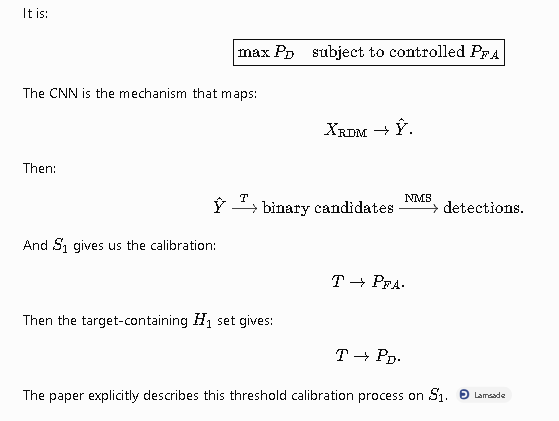

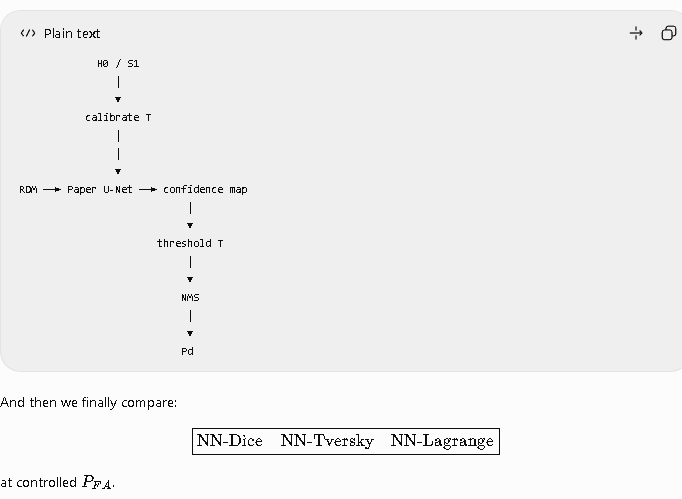

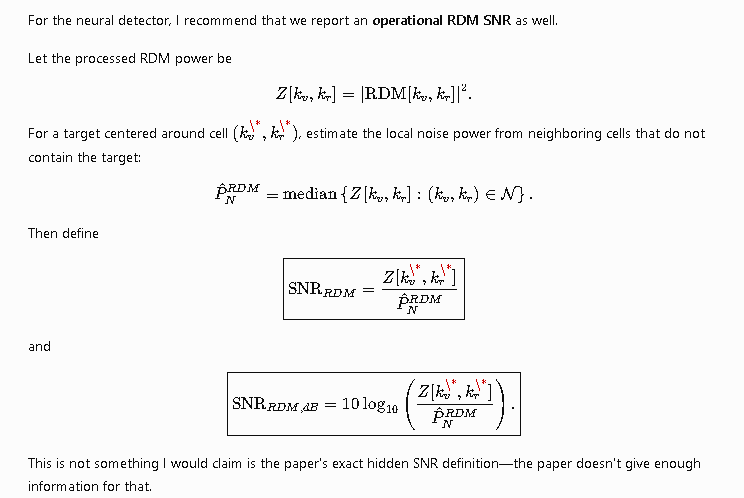

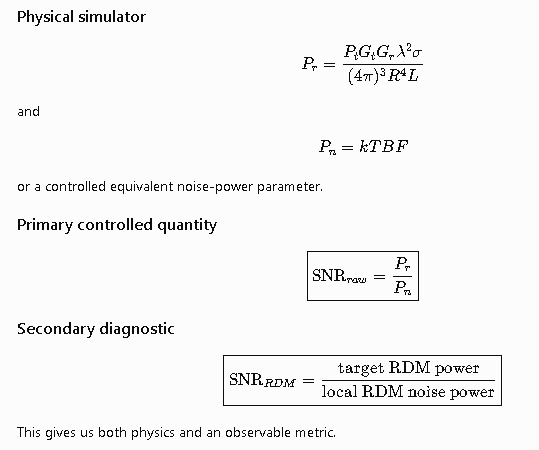

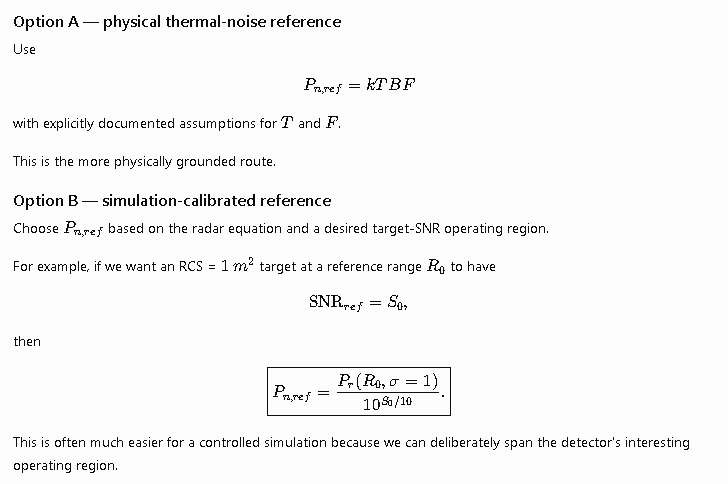

we are proceeding with option B here first. option A will be real physical reference

14. define snr mathematically. snr= target received power/thermal noise power
determine snr range we ant to reproduce

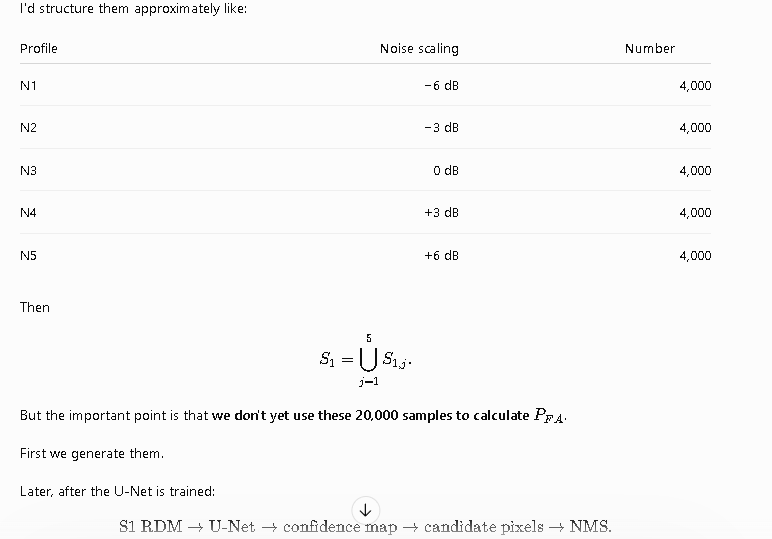

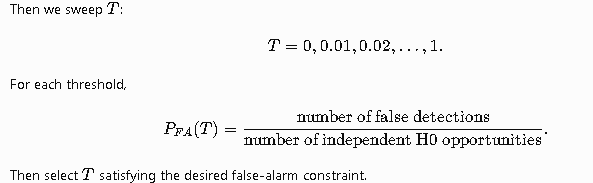

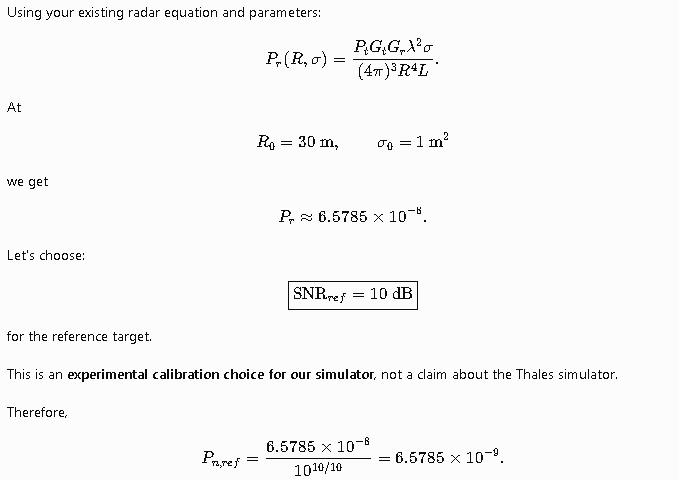

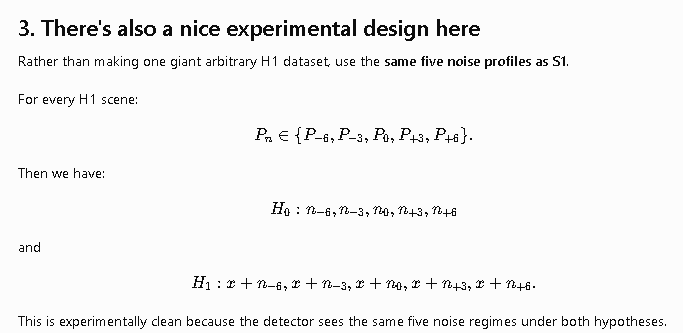

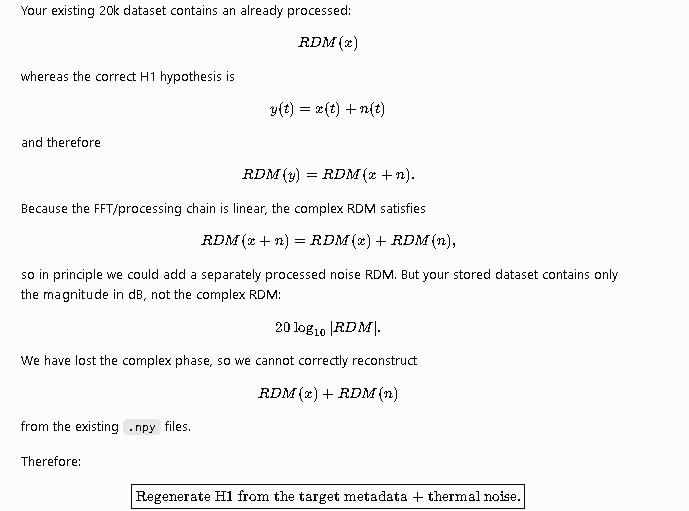

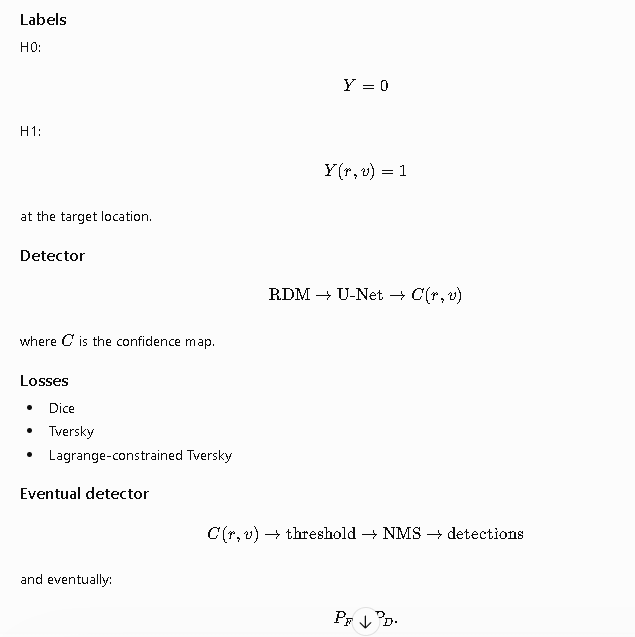

15. H0 is not a training dataset. H0 has Y=0 for every image. training U-net on H0 will give f(Y)=0. network learns there is no target. th only purpose of H0 is to check how much does the m
16. train u-net on H1 with target labels.

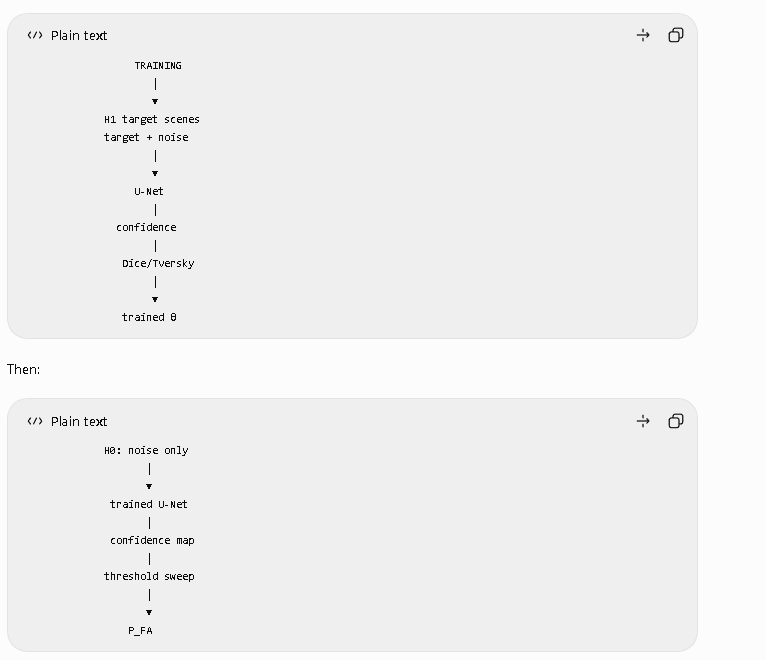

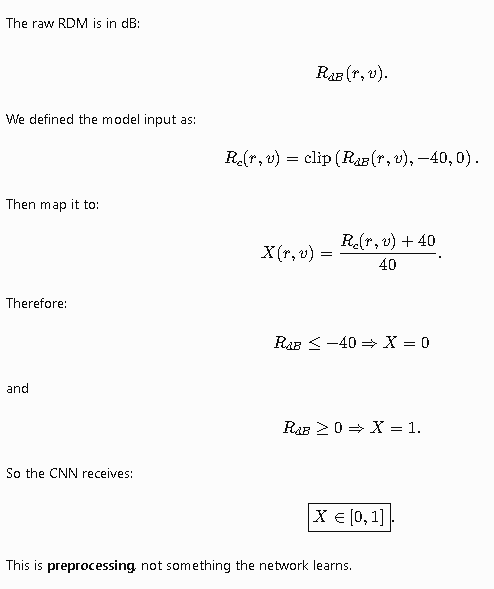

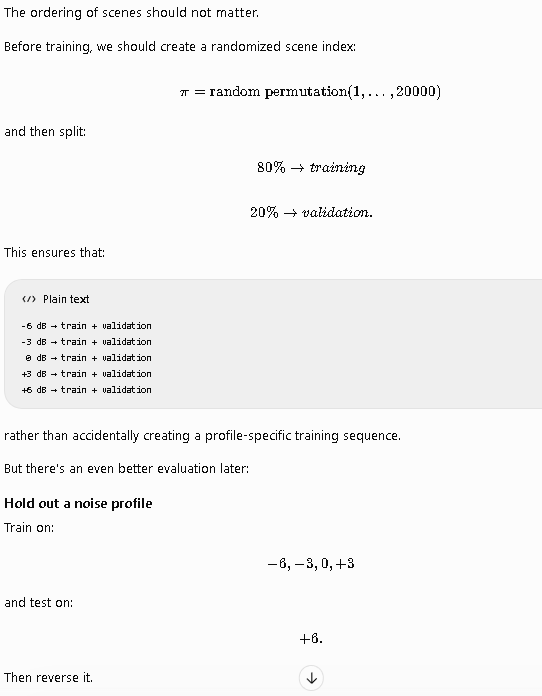

17. train the existing u-net on dice -> evaluate
18. train the existing u-net on tversky, alpha=0.6 -> evaluate for same dataset split achitecture optimizer epochs and seed
19. same for Lagrange loss.
20. Then compare (17,18 and 19)
21. DO NOT SIMULTANEOUSLY CHANGE THE LOSS, THRESHOLD, ARCHIOTECTURE, PRE-PROCESSING else we will never know what caused the observed improvement.

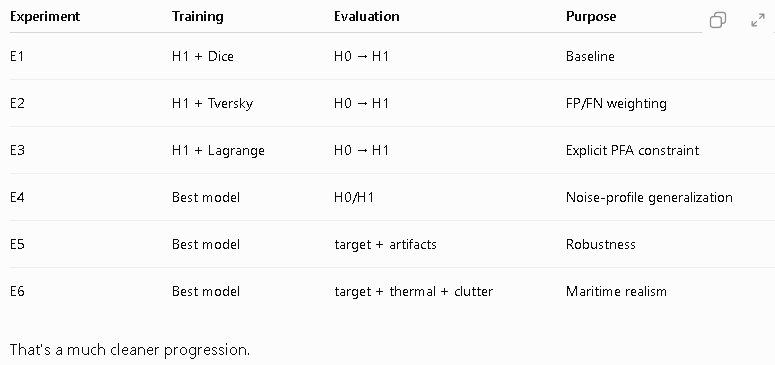

**Future Prospects**
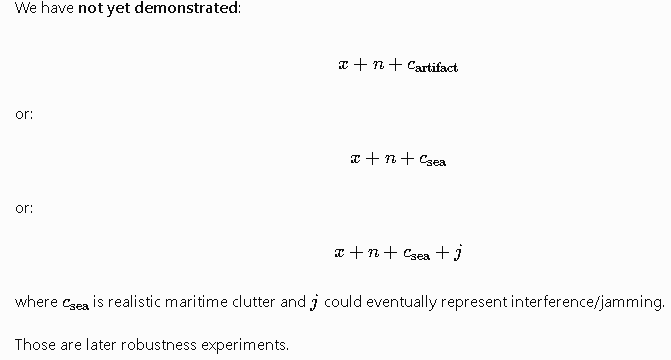

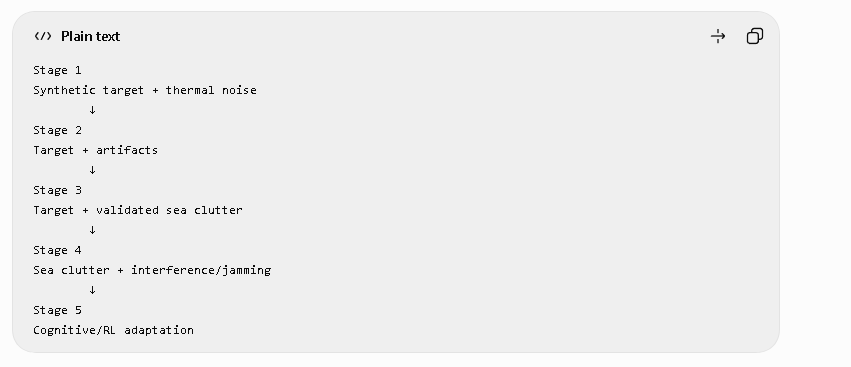

In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path


In [ ]:
# ============================================================
# 8 october
# ============================================================

H1_DIR = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/"
    "single_target_exoclutter_H1_thermal_noise"
)

rdm_file = sorted(H1_DIR.glob("rdm_*.npy"))[0]
label_file = sorted(H1_DIR.glob("labels_*.npy"))[0]

rdm = np.load(rdm_file)
labels = np.load(label_file)

print("RDM shape   :", rdm.shape)
print("Labels shape:", labels.shape)

# First 16 scenes
x = torch.from_numpy(rdm[:16]).float()
y = torch.from_numpy(labels[:16]).float()

# Paper-style input preprocessing
x = torch.clamp(x, min=-40.0, max=0.0)
x = (x + 40.0) / 40.0

# Resize RDM: 69x1334 -> 256x256
x = F.interpolate(
    x.unsqueeze(1),
    size=(256, 256),
    mode="bilinear",
    align_corners=False
)

# Add channel dimension to labels
y = y.unsqueeze(1)

print("\nAfter preprocessing:")
print("X shape :", x.shape)
print("X range :", (x.min().item(), x.max().item()))
print("Y shape :", y.shape)
print("Y range :", (y.min().item(), y.max().item()))
print("Positive pixels:", y.sum().item())

RDM shape   : (50, 69, 1334)
Labels shape: (50, 256, 256)

After preprocessing:
X shape : torch.Size([16, 1, 256, 256])
X range : (0.0, 1.0)
Y shape : torch.Size([16, 1, 256, 256])
Y range : (0.0, 0.0)
Positive pixels: 0.0


In [ ]:
import numpy as np
from pathlib import Path

STATE_DIR = Path(
    "/content/drive/MyDrive/radar_project/experiment_state"
)

state = np.load(
    STATE_DIR / "experiment_arrays.npz",
    allow_pickle=True
)

range_axis = state["range_axis"]
vel_axis = state["vel_axis"]
range_mask = state["range_mask"].astype(bool)
velocity_mask = state["velocity_mask"].astype(bool)

print("range_axis :", range_axis.shape)
print("vel_axis   :", vel_axis.shape)
print("range_mask :", range_mask.sum())
print("velocity_mask:", velocity_mask.sum())

print("\nROI:")
print("Range:", range_axis[range_mask][0], "to",
      range_axis[range_mask][-1], "m")

print("Velocity:", vel_axis[velocity_mask][0], "to",
      vel_axis[velocity_mask][-1], "m/s")

range_axis : (3200,)
vel_axis   : (256,)
range_mask : 1334
velocity_mask: 69

ROI:
Range: 10.0125 to 60.0 m
Velocity: -9.9609375 to 9.9609375 m/s


In [ ]:

H1_DIR = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/"
    "single_target_exoclutter_H1_thermal_noise"
)

label_files = sorted(H1_DIR.glob("labels_*.npy"))
metadata_files = sorted(H1_DIR.glob("metadata_*.npy"))

assert len(label_files) == len(metadata_files)

roi_range_axis = range_axis[range_mask]
roi_vel_axis = vel_axis[velocity_mask]

for label_file, metadata_file in zip(label_files, metadata_files):

    labels = np.zeros(
        np.load(label_file, mmap_mode="r").shape,
        dtype=np.float32
    )

    metadata = np.load(
        metadata_file,
        allow_pickle=True
    )

    for i, target in enumerate(metadata):

        R = float(target["range_m"])
        v = float(target["velocity_mps"])

        # Nearest native ROI bin
        r_idx = np.argmin(
            np.abs(roi_range_axis - R)
        )

        v_idx = np.argmin(
            np.abs(roi_vel_axis - v)
        )

        # Native ROI -> 256x256
        x = int(round(
            r_idx * 255 / (len(roi_range_axis) - 1)
        ))

        y = int(round(
            v_idx * 255 / (len(roi_vel_axis) - 1)
        ))

        labels[i, y, x] = 1.0

    np.save(label_file, labels)

    print(
        f"Repaired {label_file.name} | "
        f"positive pixels: {labels.sum():.0f}"
    )

print("\nLabel repair complete.")

Repaired labels_00000_00049.npy | positive pixels: 50
Repaired labels_00050_00099.npy | positive pixels: 50
Repaired labels_00100_00149.npy | positive pixels: 50
Repaired labels_00150_00199.npy | positive pixels: 50
Repaired labels_00200_00249.npy | positive pixels: 50
Repaired labels_00250_00299.npy | positive pixels: 50
Repaired labels_00300_00349.npy | positive pixels: 50
Repaired labels_00350_00399.npy | positive pixels: 50
Repaired labels_00400_00449.npy | positive pixels: 50
Repaired labels_00450_00499.npy | positive pixels: 50
Repaired labels_00500_00549.npy | positive pixels: 50
Repaired labels_00550_00599.npy | positive pixels: 50
Repaired labels_00600_00649.npy | positive pixels: 50
Repaired labels_00650_00699.npy | positive pixels: 50
Repaired labels_00700_00749.npy | positive pixels: 50
Repaired labels_00750_00799.npy | positive pixels: 50
Repaired labels_00800_00849.npy | positive pixels: 50
Repaired labels_00850_00899.npy | positive pixels: 50
Repaired labels_00900_00949.

In [ ]:


H1_DIR = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/"
    "single_target_exoclutter_H1_thermal_noise"
)

label_files = sorted(H1_DIR.glob("labels_*.npy"))

print("Number of label files:", len(label_files))

total_positive = 0
files_with_targets = 0

for f in label_files:
    labels = np.load(f)
    pos = labels.sum()

    if pos > 0:
        files_with_targets += 1

    total_positive += pos

    print(f.name, "shape:", labels.shape, "positive pixels:", pos)

print("\nFiles with targets:", files_with_targets)
print("Total positive pixels:", total_positive)

Number of label files: 400
labels_00000_00049.npy shape: (50, 256, 256) positive pixels: 50.0
labels_00050_00099.npy shape: (50, 256, 256) positive pixels: 50.0
labels_00100_00149.npy shape: (50, 256, 256) positive pixels: 50.0
labels_00150_00199.npy shape: (50, 256, 256) positive pixels: 50.0
labels_00200_00249.npy shape: (50, 256, 256) positive pixels: 50.0
labels_00250_00299.npy shape: (50, 256, 256) positive pixels: 50.0
labels_00300_00349.npy shape: (50, 256, 256) positive pixels: 50.0
labels_00350_00399.npy shape: (50, 256, 256) positive pixels: 50.0
labels_00400_00449.npy shape: (50, 256, 256) positive pixels: 50.0
labels_00450_00499.npy shape: (50, 256, 256) positive pixels: 50.0
labels_00500_00549.npy shape: (50, 256, 256) positive pixels: 50.0
labels_00550_00599.npy shape: (50, 256, 256) positive pixels: 50.0
labels_00600_00649.npy shape: (50, 256, 256) positive pixels: 50.0
labels_00650_00699.npy shape: (50, 256, 256) positive pixels: 50.0
labels_00700_00749.npy shape: (50, 

In [ ]:
# ============================================================
# 8 october
# ============================================================

H1_DIR = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/"
    "single_target_exoclutter_H1_thermal_noise"
)

rdm_file = sorted(H1_DIR.glob("rdm_*.npy"))[0]
label_file = sorted(H1_DIR.glob("labels_*.npy"))[0]

rdm = np.load(rdm_file)
labels = np.load(label_file)

print("RDM shape   :", rdm.shape)
print("Labels shape:", labels.shape)

# First 16 scenes
x = torch.from_numpy(rdm[:16]).float()
y = torch.from_numpy(labels[:16]).float()

# Paper-style input preprocessing
x = torch.clamp(x, min=-40.0, max=0.0)
x = (x + 40.0) / 40.0

# Resize RDM: 69x1334 -> 256x256
x = F.interpolate(
    x.unsqueeze(1),
    size=(256, 256),
    mode="bilinear",
    align_corners=False
)

# Add channel dimension to labels
y = y.unsqueeze(1)

print("\nAfter preprocessing:")
print("X shape :", x.shape)
print("X range :", (x.min().item(), x.max().item()))
print("Y shape :", y.shape)
print("Y range :", (y.min().item(), y.max().item()))
print("Positive pixels:", y.sum().item())

RDM shape   : (50, 69, 1334)
Labels shape: (50, 256, 256)

After preprocessing:
X shape : torch.Size([16, 1, 256, 256])
X range : (0.0, 1.0)
Y shape : torch.Size([16, 1, 256, 256])
Y range : (0.0, 1.0)
Positive pixels: 16.0


In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset

class RadarH1Dataset(Dataset):

    def __init__(self, data_dir):
        self.data_dir = Path(data_dir)

        self.rdm_files = sorted(
            self.data_dir.glob("rdm_*.npy")
        )

        self.label_files = sorted(
            self.data_dir.glob("labels_*.npy")
        )

        assert len(self.rdm_files) == len(self.label_files), \
            "RDM/label file count mismatch"

        # Each file contains 50 scenes
        self.scenes_per_file = 50

        self.num_scenes = (
            len(self.rdm_files) *
            self.scenes_per_file
        )

    def __len__(self):
        return self.num_scenes

    def __getitem__(self, idx):

        file_idx = idx // self.scenes_per_file
        scene_idx = idx % self.scenes_per_file

        rdm = np.load(
            self.rdm_files[file_idx]
        )[scene_idx]

        label = np.load(
            self.label_files[file_idx]
        )[scene_idx]

        # -----------------------------
        # RDM preprocessing
        # -----------------------------

        x = torch.from_numpy(rdm).float()

        x = torch.clamp(
            x,
            min=-40.0,
            max=0.0
        )

        x = (x + 40.0) / 40.0

        # 69 x 1334 -> 256 x 256
        x = F.interpolate(
            x.unsqueeze(0).unsqueeze(0),
            size=(256, 256),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)

        # -----------------------------
        # Label
        # -----------------------------

        y = torch.from_numpy(label).float()
        y = y.unsqueeze(0)

        return x, y

In [ ]:
H1_DIR = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/"
    "single_target_exoclutter_H1_thermal_noise"
)

dataset = RadarH1Dataset(H1_DIR)

print("Total scenes:", len(dataset))
print("RDM files:", len(dataset.rdm_files))
print("Label files:", len(dataset.label_files))

Total scenes: 20000
RDM files: 400
Label files: 400


In [ ]:
x, y = dataset[0]

print("X shape:", x.shape)
print("X range:", (x.min().item(), x.max().item()))

print("Y shape:", y.shape)
print("Y range:", (y.min().item(), y.max().item()))

print("Positive pixels:", y.sum().item())

X shape: torch.Size([1, 256, 256])
X range: (0.0, 1.0)
Y shape: torch.Size([1, 256, 256])
Y range: (0.0, 1.0)
Positive pixels: 1.0


In [ ]:
from torch.utils.data import random_split

# Fixed, reproducible split
generator = torch.Generator().manual_seed(42)

train_size = 16_000
val_size = 4_000

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=generator
)

print("Training scenes  :", len(train_dataset))
print("Validation scenes:", len(val_dataset))

Training scenes  : 16000
Validation scenes: 4000


In [ ]:
STATE_DIR = Path(
    "/content/drive/MyDrive/radar_project/experiment_state"
)

STATE_DIR.mkdir(parents=True, exist_ok=True)

np.save(
    STATE_DIR / "h1_train_indices.npy",
    np.array(train_dataset.indices)
)

np.save(
    STATE_DIR / "h1_val_indices.npy",
    np.array(val_dataset.indices)
)

print("Saved fixed H1 train/validation split.")

Saved fixed H1 train/validation split.


In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Training batches  :", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches  : 1000
Validation batches: 250


In [ ]:
x_batch, y_batch = next(iter(train_loader))

print("X shape:", x_batch.shape)
print("X range:", (x_batch.min().item(), x_batch.max().item()))

print("Y shape:", y_batch.shape)
print("Y range:", (y_batch.min().item(), y_batch.max().item()))

print("Positive pixels in batch:", y_batch.sum().item())

X shape: torch.Size([16, 1, 256, 256])
X range: (0.0, 1.0)
Y shape: torch.Size([16, 1, 256, 256])
Y range: (0.0, 1.0)
Positive pixels in batch: 16.0


In [ ]:
class DiceLoss(torch.nn.Module):

    def __init__(self, eps=1e-8):
        super().__init__()
        self.eps = eps

    def forward(self, pred, target):

        # pred and target: [B, 1, H, W]

        numerator = 2.0 * torch.sum(
            pred * target,
            dim=(1, 2, 3)
        )

        denominator = (
            torch.sum(pred ** 2, dim=(1, 2, 3))
            +
            torch.sum(target ** 2, dim=(1, 2, 3))
        )

        dice = (
            numerator /
            (denominator + self.eps)
        )

        # Paper: LD = 1 - D
        loss = 1.0 - dice

        # Average over mini-batch
        return loss.mean()

In [ ]:
import torch

# Define the execution device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

criterion = DiceLoss()

model = PaperUNet().to(device)

x_batch, y_batch = next(iter(train_loader))

x_batch = x_batch.to(device)
y_batch = y_batch.to(device)

with torch.no_grad():
    pred = model(x_batch)
    loss = criterion(pred, y_batch)

print("Prediction shape:", pred.shape)
print("Prediction range:",
      (pred.min().item(), pred.max().item()))

print("Initial Dice loss:", loss.item())

Prediction shape: torch.Size([16, 1, 256, 256])
Prediction range: (0.5039498805999756, 0.5265117287635803)
Initial Dice loss: 0.9999409914016724


In [ ]:
# ============================================================
# DICE BASELINE — TRAINING CONFIGURATION
# ============================================================

import torch
from pathlib import Path

# Fresh model for the actual experiment
model = PaperUNet().to(device)

# Adam optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=7e-3
)

# Linear learning-rate schedule:
# 7e-3 -> 5e-5 over 150 epochs
EPOCHS = 150
LR_START = 7e-3
LR_END = 5e-5

scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer,
    start_factor=1.0,
    end_factor=LR_END / LR_START,
    total_iters=EPOCHS
)

# Loss
criterion = DiceLoss()

# Checkpoint location
CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/radar_project/experiment_state/checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_CHECKPOINT = (
    CHECKPOINT_DIR / "dice_baseline_best.pt"
)

print("Model parameters:",
      sum(p.numel() for p in model.parameters()))

print("Optimizer       :", type(optimizer).__name__)
print("Initial LR      :", optimizer.param_groups[0]["lr"])
print("Final LR        :", LR_END)
print("Epochs          :", EPOCHS)
print("Loss            :", type(criterion).__name__)
print("Best checkpoint :", BEST_CHECKPOINT)

Model parameters: 167476
Optimizer       : Adam
Initial LR      : 0.007
Final LR        : 5e-05
Epochs          : 150
Loss            : DiceLoss
Best checkpoint : /content/drive/MyDrive/radar_project/experiment_state/checkpoints/dice_baseline_best.pt


In [ ]:
# ============================================================
# BUILD IN-RAM TRAINING CACHE
# Existing H1 data -> preprocess ONCE -> RAM
# ============================================================

import gc
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path

H1_DIR = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/"
    "single_target_exoclutter_H1_thermal_noise"
)

rdm_files = sorted(H1_DIR.glob("rdm_*.npy"))
label_files = sorted(H1_DIR.glob("labels_*.npy"))

N_SCENES = 20_000

# Preallocate CPU RAM
X_cache = torch.empty(
    (N_SCENES, 1, 256, 256),
    dtype=torch.float32
)

Y_cache = torch.empty(
    (N_SCENES, 1, 256, 256),
    dtype=torch.float32
)

print("Allocated:")
print(f"X cache: {X_cache.numel() * 4 / 1024**3:.2f} GB")
print(f"Y cache: {Y_cache.numel() * 4 / 1024**3:.2f} GB")

offset = 0

for rdm_file, label_file in zip(rdm_files, label_files):

    rdm = np.load(rdm_file)
    labels = np.load(label_file)

    n = rdm.shape[0]

    # RDM -> tensor
    x = torch.from_numpy(rdm).float()

    # Frozen preprocessing
    x = torch.clamp(x, -40.0, 0.0)
    x = (x + 40.0) / 40.0

    # 69 x 1334 -> 256 x 256
    x = F.interpolate(
        x.unsqueeze(1),
        size=(256, 256),
        mode="bilinear",
        align_corners=False
    )

    y = torch.from_numpy(labels).float().unsqueeze(1)

    X_cache[offset:offset+n] = x
    Y_cache[offset:offset+n] = y

    offset += n

    del rdm, labels, x, y

    print(
        f"Cached {offset:05d}/{N_SCENES}",
        end="\r"
    )

    gc.collect()

print("\n\nCache complete.")

print("X:", X_cache.shape, X_cache.dtype)
print("Y:", Y_cache.shape, Y_cache.dtype)

print("X range:",
      X_cache.min().item(),
      X_cache.max().item())

print("Total positive pixels:",
      Y_cache.sum().item())

Allocated:
X cache: 4.88 GB
Y cache: 4.88 GB


Cache complete.
X: torch.Size([20000, 1, 256, 256]) torch.float32
Y: torch.Size([20000, 1, 256, 256]) torch.float32
X range: 0.0 1.0
Total positive pixels: 20000.0


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

# Load the frozen split indices
train_indices = np.load(
    "/content/drive/MyDrive/radar_project/experiment_state/h1_train_indices.npy"
)

val_indices = np.load(
    "/content/drive/MyDrive/radar_project/experiment_state/h1_val_indices.npy"
)

# Create datasets directly from RAM cache
train_dataset_ram = TensorDataset(
    X_cache[train_indices],
    Y_cache[train_indices]
)

val_dataset_ram = TensorDataset(
    X_cache[val_indices],
    Y_cache[val_indices]
)

train_loader = DataLoader(
    train_dataset_ram,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset_ram,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train scenes:", len(train_dataset_ram))
print("Val scenes  :", len(val_dataset_ram))
print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))

In [ ]:
import time

model.train()

x_batch, y_batch = next(iter(train_loader))

x_batch = x_batch.to(device, non_blocking=True)
y_batch = y_batch.to(device, non_blocking=True)

torch.cuda.synchronize()
t0 = time.time()

optimizer.zero_grad(set_to_none=True)

pred = model(x_batch)
loss = criterion(pred, y_batch)

loss.backward()
optimizer.step()

torch.cuda.synchronize()

print(f"One training batch: {time.time() - t0:.3f} s")
print("Loss:", loss.item())

In [ ]:
# ============================================================
# DICE BASELINE — FULL AUTONOMOUS TRAINING RUN
# ============================================================

import time
import json
import numpy as np
import torch
from pathlib import Path
from torch.utils.data import TensorDataset, DataLoader

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

STATE_DIR = Path(
    "/content/drive/MyDrive/radar_project/experiment_state"
)

CHECKPOINT_DIR = STATE_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_CHECKPOINT = CHECKPOINT_DIR / "dice_baseline_best.pt"
LATEST_CHECKPOINT = CHECKPOINT_DIR / "dice_baseline_latest.pt"
HISTORY_FILE = CHECKPOINT_DIR / "dice_baseline_history.npz"
SUMMARY_FILE = CHECKPOINT_DIR / "dice_baseline_summary.json"

# ------------------------------------------------------------
# 2. Frozen split
# ------------------------------------------------------------

train_indices = np.load(
    STATE_DIR / "h1_train_indices.npy"
)

val_indices = np.load(
    STATE_DIR / "h1_val_indices.npy"
)

# ------------------------------------------------------------
# 3. RAM datasets
# ------------------------------------------------------------

train_dataset_ram = TensorDataset(
    X_cache[train_indices],
    Y_cache[train_indices]
)

val_dataset_ram = TensorDataset(
    X_cache[val_indices],
    Y_cache[val_indices]
)

train_loader = DataLoader(
    train_dataset_ram,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset_ram,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# ------------------------------------------------------------
# 4. Training configuration
# ------------------------------------------------------------

EPOCHS = 150
LR_START = 7e-3
LR_END = 5e-5

# ------------------------------------------------------------
# 5. Fresh model / optimizer / loss
# ------------------------------------------------------------

model = PaperUNet().to(device)

criterion = DiceLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LR_START
)

scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer,
    start_factor=1.0,
    end_factor=LR_END / LR_START,
    total_iters=EPOCHS
)

# ------------------------------------------------------------
# 6. History
# ------------------------------------------------------------

history = {
    "train_loss": [],
    "val_loss": [],
    "lr": [],
    "epoch_time": []
}

best_val_loss = float("inf")
start_epoch = 0

# ------------------------------------------------------------
# 7. Resume if latest checkpoint exists
# ------------------------------------------------------------

if LATEST_CHECKPOINT.exists():

    print("Latest checkpoint found.")
    print("Attempting resume...")

    checkpoint = torch.load(
        LATEST_CHECKPOINT,
        map_location=device
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    scheduler.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    start_epoch = checkpoint["epoch"]

    best_val_loss = checkpoint["best_val_loss"]

    history = checkpoint["history"]

    print(
        f"Resuming from epoch {start_epoch + 1}"
    )

else:

    print("No previous checkpoint found.")
    print("Starting fresh Dice baseline.")

# ------------------------------------------------------------
# 8. Configuration print
# ------------------------------------------------------------

print("\n============================================")
print("DICE BASELINE")
print("============================================")

print("Device:", device)
print("Model parameters:",
      sum(p.numel() for p in model.parameters()))

print("Train scenes:", len(train_dataset_ram))
print("Validation scenes:", len(val_dataset_ram))

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

print("Batch size:", 16)
print("Epochs:", EPOCHS)
print("Initial LR:", LR_START)
print("Final LR:", LR_END)
print("Loss: Dice")
print("Best checkpoint:", BEST_CHECKPOINT)

print("============================================\n")

# ------------------------------------------------------------
# 9. Training
# ------------------------------------------------------------

for epoch in range(start_epoch, EPOCHS):

    epoch_start = time.time()

    # ========================================================
    # TRAIN
    # ========================================================

    model.train()

    train_loss_sum = 0.0

    for x_batch, y_batch in train_loader:

        x_batch = x_batch.to(
            device,
            non_blocking=True
        )

        y_batch = y_batch.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        pred = model(x_batch)

        loss = criterion(
            pred,
            y_batch
        )

        loss.backward()

        optimizer.step()

        train_loss_sum += loss.item()

    train_loss = (
        train_loss_sum /
        len(train_loader)
    )

    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    val_loss_sum = 0.0

    with torch.no_grad():

        for x_batch, y_batch in val_loader:

            x_batch = x_batch.to(
                device,
                non_blocking=True
            )

            y_batch = y_batch.to(
                device,
                non_blocking=True
            )

            pred = model(x_batch)

            loss = criterion(
                pred,
                y_batch
            )

            val_loss_sum += loss.item()

    val_loss = (
        val_loss_sum /
        len(val_loader)
    )

    # ========================================================
    # LR
    # ========================================================

    current_lr = (
        optimizer.param_groups[0]["lr"]
    )

    # ========================================================
    # History
    # ========================================================

    epoch_time = time.time() - epoch_start

    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["lr"].append(
        current_lr
    )

    history["epoch_time"].append(
        epoch_time
    )

    # ========================================================
    # BEST CHECKPOINT
    # ========================================================

    is_best = val_loss < best_val_loss

    if is_best:

        best_val_loss = val_loss

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict":
                    model.state_dict(),
                "optimizer_state_dict":
                    optimizer.state_dict(),
                "scheduler_state_dict":
                    scheduler.state_dict(),
                "best_val_loss":
                    best_val_loss,
                "history":
                    history
            },
            BEST_CHECKPOINT
        )

    # ========================================================
    # LATEST CHECKPOINT
    # ========================================================

    torch.save(
        {
            "epoch": epoch + 1,
            "model_state_dict":
                model.state_dict(),
            "optimizer_state_dict":
                optimizer.state_dict(),
            "scheduler_state_dict":
                scheduler.state_dict(),
            "best_val_loss":
                best_val_loss,
            "history":
                history
        },
        LATEST_CHECKPOINT
    )

    # ========================================================
    # History backup
    # ========================================================

    np.savez(
        HISTORY_FILE,
        train_loss=np.array(
            history["train_loss"]
        ),
        val_loss=np.array(
            history["val_loss"]
        ),
        lr=np.array(
            history["lr"]
        ),
        epoch_time=np.array(
            history["epoch_time"]
        )
    )

    # ========================================================
    # Scheduler
    # ========================================================

    scheduler.step()

    # ========================================================
    # Progress
    # ========================================================

    marker = " <-- BEST" if is_best else ""

    print(
        f"Epoch {epoch + 1:03d}/{EPOCHS} | "
        f"Train {train_loss:.6f} | "
        f"Val {val_loss:.6f} | "
        f"LR {current_lr:.6e} | "
        f"{epoch_time:.1f}s"
        f"{marker}"
    )

# ------------------------------------------------------------
# 10. Final summary
# ------------------------------------------------------------

summary = {
    "experiment": "Dice baseline",
    "architecture": "PaperUNet",
    "parameters": int(
        sum(p.numel() for p in model.parameters())
    ),
    "dataset": "single_target_exoclutter_H1_thermal_noise",
    "total_scenes": 20000,
    "train_scenes": 16000,
    "validation_scenes": 4000,
    "batch_size": 16,
    "epochs": EPOCHS,
    "lr_start": LR_START,
    "lr_end": LR_END,
    "best_validation_loss": float(
        best_val_loss
    ),
    "best_checkpoint": str(
        BEST_CHECKPOINT
    )
}

with open(
    SUMMARY_FILE,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

print("\n============================================")
print("DICE BASELINE COMPLETE")
print("============================================")
print(
    "Best validation loss:",
    best_val_loss
)
print(
    "Best checkpoint:",
    BEST_CHECKPOINT
)
print(
    "History:",
    HISTORY_FILE
)
print(
    "Summary:",
    SUMMARY_FILE
)

In [ ]:
# ============================================================
# DICE DIAGNOSTIC RUN
# Lower LR to test whether 7e-3 caused sigmoid collapse
# ============================================================

import time
import gc
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

H1_DIR = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/"
    "single_target_exoclutter_H1_thermal_noise"
)

STATE_DIR = Path(
    "/content/drive/MyDrive/radar_project/experiment_state"
)

CHECKPOINT_DIR = STATE_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

LATEST = CHECKPOINT_DIR / "dice_lr1e4_latest.pt"
BEST = CHECKPOINT_DIR / "dice_lr1e4_best.pt"

# ------------------------------------------------------------
# FILES
# ------------------------------------------------------------

rdm_files = sorted(H1_DIR.glob("rdm_*.npy"))
label_files = sorted(H1_DIR.glob("labels_*.npy"))

assert len(rdm_files) == 400
assert len(label_files) == 400

# ------------------------------------------------------------
# FIXED SPLIT
# ------------------------------------------------------------

train_indices = set(
    np.load(
        STATE_DIR / "h1_train_indices.npy"
    ).tolist()
)

val_indices = set(
    np.load(
        STATE_DIR / "h1_val_indices.npy"
    ).tolist()
)

# ------------------------------------------------------------
# PREPROCESS
# ------------------------------------------------------------

def preprocess(rdm):

    x = torch.from_numpy(rdm).float()

    x = torch.clamp(x, -40.0, 0.0)

    x = (x + 40.0) / 40.0

    x = F.interpolate(
        x.unsqueeze(1),
        size=(256, 256),
        mode="bilinear",
        align_corners=False
    )

    return x


# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

model = PaperUNet().to(device)

criterion = DiceLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

EPOCHS = 25

scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer,
    start_factor=1.0,
    end_factor=0.5,
    total_iters=EPOCHS
)

# ------------------------------------------------------------
# RESUME SUPPORT
# ------------------------------------------------------------

start_epoch = 0
best_val = float("inf")

history = {
    "train_loss": [],
    "val_loss": [],
    "lr": [],
    "epoch_time": []
}

if LATEST.exists():

    print("Existing diagnostic checkpoint found.")

    ckpt = torch.load(
        LATEST,
        map_location=device
    )

    model.load_state_dict(
        ckpt["model_state_dict"]
    )

    optimizer.load_state_dict(
        ckpt["optimizer_state_dict"]
    )

    scheduler.load_state_dict(
        ckpt["scheduler_state_dict"]
    )

    start_epoch = ckpt["epoch"]
    best_val = ckpt["best_val"]
    history = ckpt["history"]

    print(
        "Resuming after epoch:",
        start_epoch
    )

else:

    print("Starting fresh.")

# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

for epoch in range(
    start_epoch,
    EPOCHS
):

    t0 = time.time()

    model.train()

    train_sum = 0.0
    train_n = 0

    # ========================================================
    # TRAINING
    # ========================================================

    for file_idx in range(400):

        rdm = np.load(
            rdm_files[file_idx]
        )

        labels = np.load(
            label_files[file_idx]
        )

        x = preprocess(rdm)

        y = torch.from_numpy(
            labels
        ).float().unsqueeze(1)

        local_train = [
            j for j in range(50)
            if file_idx * 50 + j
            in train_indices
        ]

        # Use chunks of 32
        for s in range(
            0,
            len(local_train),
            32
        ):

            ids = local_train[
                s:s+32
            ]

            xb = x[ids].to(
                device,
                non_blocking=True
            )

            yb = y[ids].to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            pred = model(xb)

            loss = criterion(
                pred,
                yb
            )

            loss.backward()

            optimizer.step()

            train_sum += loss.item()
            train_n += 1

        del rdm, labels, x, y

    train_loss = (
        train_sum / train_n
    )

    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    val_sum = 0.0
    val_n = 0

    with torch.no_grad():

        for file_idx in range(400):

            rdm = np.load(
                rdm_files[file_idx]
            )

            labels = np.load(
                label_files[file_idx]
            )

            x = preprocess(rdm)

            y = torch.from_numpy(
                labels
            ).float().unsqueeze(1)

            local_val = [
                j for j in range(50)
                if file_idx * 50 + j
                in val_indices
            ]

            for s in range(
                0,
                len(local_val),
                32
            ):

                ids = local_val[
                    s:s+32
                ]

                xb = x[ids].to(
                    device,
                    non_blocking=True
                )

                yb = y[ids].to(
                    device,
                    non_blocking=True
                )

                pred = model(xb)

                loss = criterion(
                    pred,
                    yb
                )

                val_sum += loss.item()
                val_n += 1

            del rdm, labels, x, y

    val_loss = (
        val_sum / val_n
    )

    lr = optimizer.param_groups[0]["lr"]

    elapsed = time.time() - t0

    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["lr"].append(
        lr
    )

    history["epoch_time"].append(
        elapsed
    )

    # ========================================================
    # BEST
    # ========================================================

    if val_loss < best_val:

        best_val = val_loss

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict":
                    model.state_dict(),
                "optimizer_state_dict":
                    optimizer.state_dict(),
                "scheduler_state_dict":
                    scheduler.state_dict(),
                "best_val":
                    best_val,
                "history":
                    history
            },
            BEST
        )

        marker = " <-- BEST"

    else:

        marker = ""

    # ========================================================
    # LATEST
    # ========================================================

    torch.save(
        {
            "epoch": epoch + 1,
            "model_state_dict":
                model.state_dict(),
            "optimizer_state_dict":
                optimizer.state_dict(),
            "scheduler_state_dict":
                scheduler.state_dict(),
            "best_val":
                best_val,
            "history":
                history
        },
        LATEST
    )

    scheduler.step()

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train {train_loss:.6f} | "
        f"Val {val_loss:.6f} | "
        f"LR {lr:.3e} | "
        f"{elapsed:.1f}s"
        f"{marker}"
    )

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\n================================")
print("DIAGNOSTIC DICE RUN COMPLETE")
print("================================")
print("Best validation loss:", best_val)
print("Best checkpoint:", BEST)

Starting fresh.
Epoch 01/25 | Train 0.914422 | Val 0.859977 | LR 1.000e-04 | 314.8s <-- BEST
Epoch 02/25 | Train 0.824216 | Val 0.804720 | LR 9.800e-05 | 288.3s <-- BEST
Epoch 03/25 | Train 0.783101 | Val 0.765582 | LR 9.600e-05 | 276.4s <-- BEST
Epoch 04/25 | Train 0.754651 | Val 0.735966 | LR 9.400e-05 | 252.2s <-- BEST
Epoch 05/25 | Train 0.727805 | Val 0.710681 | LR 9.200e-05 | 216.9s <-- BEST
Epoch 06/25 | Train 0.704588 | Val 0.699430 | LR 9.000e-05 | 218.5s <-- BEST
Epoch 07/25 | Train 0.684727 | Val 0.672034 | LR 8.800e-05 | 217.8s <-- BEST
Epoch 08/25 | Train 0.668238 | Val 0.654660 | LR 8.600e-05 | 220.0s <-- BEST
Epoch 09/25 | Train 0.644057 | Val 0.644352 | LR 8.400e-05 | 219.7s <-- BEST
Epoch 10/25 | Train 0.624510 | Val 0.632863 | LR 8.200e-05 | 220.2s <-- BEST
Epoch 11/25 | Train 0.603691 | Val 0.605523 | LR 8.000e-05 | 219.1s <-- BEST
Epoch 12/25 | Train 0.583831 | Val 0.578710 | LR 7.800e-05 | 218.7s <-- BEST
Epoch 13/25 | Train 0.561577 | Val 0.567578 | LR 7.600e-05 |

switch to Pfa now. The paper is ultimately concerned with the Neyman–Pearson objective: max Pd subject to Pfa< alpha
dice is just the training objective.
network learned something. we have to verify if confidence map produces useful detections

25-epoch Dice checkpoint → H0 confidence maps → threshold sweep → NMS → \(P_{FA}\) curve → choose threshold → H1 → \(P_D\).

**Recommended**
Do Pfa calculaiton next

In [ ]:
import torch
import os

CHECKPOINT = "/content/drive/MyDrive/radar_project/experiment_state/checkpoints/dice_lr1e4_best.pt"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = PaperUNet().to(device)

checkpoint = torch.load(CHECKPOINT, map_location=device)

print("Checkpoint keys:", checkpoint.keys())

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"Loaded checkpoint: {CHECKPOINT}")
print(f"Device: {device}")
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

if "epoch" in checkpoint:
    print(f"Epoch: {checkpoint['epoch']}")
if "val_loss" in checkpoint:
    print(f"Validation loss: {checkpoint['val_loss']:.6f}")
if "lr" in checkpoint:
    print(f"Learning rate: {checkpoint['lr']:.3e}")

Checkpoint keys: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'best_val', 'history'])
Loaded checkpoint: /content/drive/MyDrive/radar_project/experiment_state/checkpoints/dice_lr1e4_best.pt
Device: cuda
Model parameters: 167,476
Epoch: 25


run inference on H0

In [ ]:
import os
import glob
import numpy as np
import torch
import torch.nn.functional as F

H0_DIR = "/content/drive/MyDrive/radar_project/radar_dataset/S1_targetless_thermal_noise"

rdm_files = sorted(glob.glob(os.path.join(H0_DIR, "rdm_*.npy")))

print("Number of H0 RDM files:", len(rdm_files))
print("First file:", os.path.basename(rdm_files[0]))
print("Last file:", os.path.basename(rdm_files[-1]))

Number of H0 RDM files: 200
First file: rdm_00000_00099.npy
Last file: rdm_19900_19999.npy


In [ ]:
# Collect maximum confidence per H0 image.
# We initially store only the maximum because this is enough
# to inspect the false-alarm confidence distribution.

h0_max_scores = []

model.eval()

with torch.no_grad():

    for file_idx, rdm_file in enumerate(rdm_files):

        rdms = np.load(rdm_file).astype(np.float32)

        # Expected shape: (100, 69, 1334)
        assert rdms.ndim == 3
        assert rdms.shape[1:] == (69, 1334)

        # Paper preprocessing:
        # clip [-40, 0] dB -> [0, 1]
        rdms = np.clip(rdms, -40.0, 0.0)
        rdms = (rdms + 40.0) / 40.0

        # Convert to torch: (N, 1, 69, 1334)
        x = torch.from_numpy(rdms).unsqueeze(1).to(device)

        # Resize to model input: (N, 1, 256, 256)
        x = F.interpolate(
            x,
            size=(256, 256),
            mode="bilinear",
            align_corners=False
        )

        # CNN inference
        pred = model(x)

        # Maximum confidence in each image
        batch_max = pred.amax(dim=(1, 2, 3)).cpu().numpy()

        h0_max_scores.append(batch_max)

        if (file_idx + 1) % 20 == 0:
            print(f"Processed {file_idx + 1}/{len(rdm_files)} files")

h0_max_scores = np.concatenate(h0_max_scores)

print("\nH0 inference complete.")
print("Number of H0 scenes:", len(h0_max_scores))
print("Min max-score:", h0_max_scores.min())
print("Mean max-score:", h0_max_scores.mean())
print("Median max-score:", np.median(h0_max_scores))
print("95th percentile:", np.percentile(h0_max_scores, 95))
print("99th percentile:", np.percentile(h0_max_scores, 99))
print("99.9th percentile:", np.percentile(h0_max_scores, 99.9))
print("Maximum:", h0_max_scores.max())

Processed 20/200 files
Processed 40/200 files
Processed 60/200 files
Processed 80/200 files
Processed 100/200 files
Processed 120/200 files
Processed 140/200 files
Processed 160/200 files
Processed 180/200 files
Processed 200/200 files

H0 inference complete.
Number of H0 scenes: 20000
Min max-score: 2.363545e-19
Mean max-score: 6.5953805e-12
Median max-score: 9.5510335e-18
95th percentile: 1.9971366e-12
99th percentile: 2.7714433e-11
99.9th percentile: 7.881324e-10
Maximum: 3.529835e-08


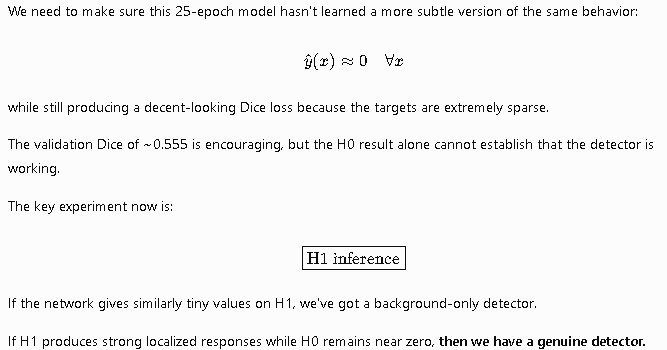

In [ ]:
import os
import glob
import numpy as np
import torch
import torch.nn.functional as F

H1_DIR = "/content/drive/MyDrive/radar_project/radar_dataset/single_target_exoclutter_H1_thermal_noise"

rdm_files = sorted(glob.glob(os.path.join(H1_DIR, "rdm_*.npy")))
meta_files = sorted(glob.glob(os.path.join(H1_DIR, "metadata_*.npy")))

print("RDM files:", len(rdm_files))
print("Metadata files:", len(meta_files))
print("First RDM:", os.path.basename(rdm_files[0]))
print("First metadata:", os.path.basename(meta_files[0]))

RDM files: 400
Metadata files: 400
First RDM: rdm_00000_00049.npy
First metadata: metadata_00000_00049.npy


In [ ]:
h1_max_scores = []
h1_max_positions = []
h1_target_positions = []

model.eval()

with torch.no_grad():

    for file_idx, (rdm_file, meta_file) in enumerate(zip(rdm_files, meta_files)):

        rdms = np.load(rdm_file).astype(np.float32)
        metadata = np.load(meta_file, allow_pickle=True)

        assert rdms.ndim == 3
        assert rdms.shape[1:] == (69, 1334)
        assert len(rdms) == len(metadata)

        # Same preprocessing as training
        rdms = np.clip(rdms, -40.0, 0.0)
        rdms = (rdms + 40.0) / 40.0

        x = torch.from_numpy(rdms).unsqueeze(1).to(device)

        x = F.interpolate(
            x,
            size=(256, 256),
            mode="bilinear",
            align_corners=False
        )

        pred = model(x)

        # Flatten spatial dimensions
        pred_flat = pred[:, 0].reshape(pred.shape[0], -1)

        max_scores, max_indices = torch.max(pred_flat, dim=1)

        max_scores = max_scores.cpu().numpy()
        max_indices = max_indices.cpu().numpy()

        # Convert flattened index -> (y, x)
        max_y, max_x = np.unravel_index(
            max_indices,
            (256, 256)
        )

        for i in range(len(metadata)):

            h1_max_scores.append(float(max_scores[i]))
            h1_max_positions.append(
                (int(max_y[i]), int(max_x[i]))
            )

            m = metadata[i].item() if hasattr(metadata[i], "item") else metadata[i]

            # Target physical coordinates
            r = float(m["range_m"])
            v = float(m["velocity_mps"])

            # Native ROI axes
            roi_range_axis = range_axis[range_mask]
            roi_velocity_axis = vel_axis[velocity_mask]

            native_x = int(np.argmin(np.abs(roi_range_axis - r)))
            native_y = int(np.argmin(np.abs(roi_velocity_axis - v)))

            # Same mapping used for labels
            target_x = int(
                round(native_x * 255 / (len(roi_range_axis) - 1))
            )

            target_y = int(
                round(native_y * 255 / (len(roi_velocity_axis) - 1))
            )

            h1_target_positions.append(
                (target_y, target_x)
            )

        if (file_idx + 1) % 40 == 0:
            print(f"Processed {file_idx + 1}/{len(rdm_files)} files")


h1_max_scores = np.array(h1_max_scores)
h1_max_positions = np.array(h1_max_positions)
h1_target_positions = np.array(h1_target_positions)

print("\nH1 inference complete.")
print("Number of H1 scenes:", len(h1_max_scores))

print("\nConfidence statistics:")
print("Mean:", h1_max_scores.mean())
print("Median:", np.median(h1_max_scores))
print("95th percentile:", np.percentile(h1_max_scores, 95))
print("99th percentile:", np.percentile(h1_max_scores, 99))
print("99.9th percentile:", np.percentile(h1_max_scores, 99.9))
print("Maximum:", h1_max_scores.max())

print("\nFirst 10 predictions:")
for i in range(10):
    print(
        f"Scene {i:5d} | "
        f"score={h1_max_scores[i]:.6e} | "
        f"pred=(y={h1_max_positions[i,0]}, x={h1_max_positions[i,1]}) | "
        f"target=(y={h1_target_positions[i,0]}, x={h1_target_positions[i,1]})"
    )

Processed 40/400 files
Processed 80/400 files
Processed 120/400 files
Processed 160/400 files
Processed 200/400 files
Processed 240/400 files
Processed 280/400 files
Processed 320/400 files
Processed 360/400 files
Processed 400/400 files

H1 inference complete.
Number of H1 scenes: 20000

Confidence statistics:
Mean: 0.8059766483202515
Median: 0.8688457310199738
95th percentile: 0.9843147993087769
99th percentile: 0.993636132478714
99.9th percentile: 0.9973887796401982
Maximum: 0.9987326264381409

First 10 predictions:
Scene     0 | score=9.015911e-01 | pred=(y=68, x=162) | target=(y=68, x=162)
Scene     1 | score=9.280701e-01 | pred=(y=244, x=130) | target=(y=244, x=130)
Scene     2 | score=9.690431e-01 | pred=(y=56, x=66) | target=(y=75, x=67)
Scene     3 | score=3.423866e-01 | pred=(y=36, x=21) | target=(y=60, x=22)
Scene     4 | score=6.873125e-01 | pred=(y=131, x=241) | target=(y=131, x=240)
Scene     5 | score=7.595075e-01 | pred=(y=207, x=205) | target=(y=206, x=205)
Scene     6

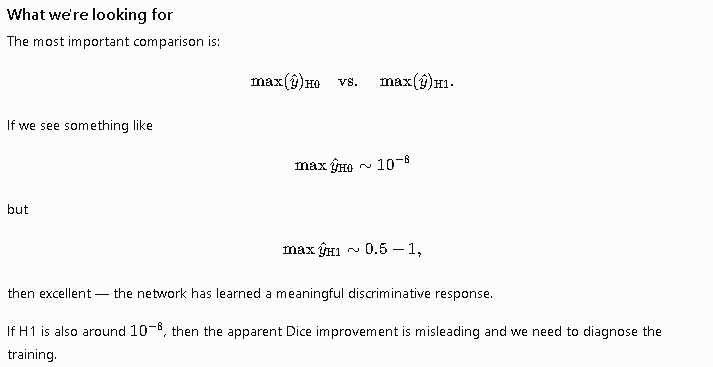

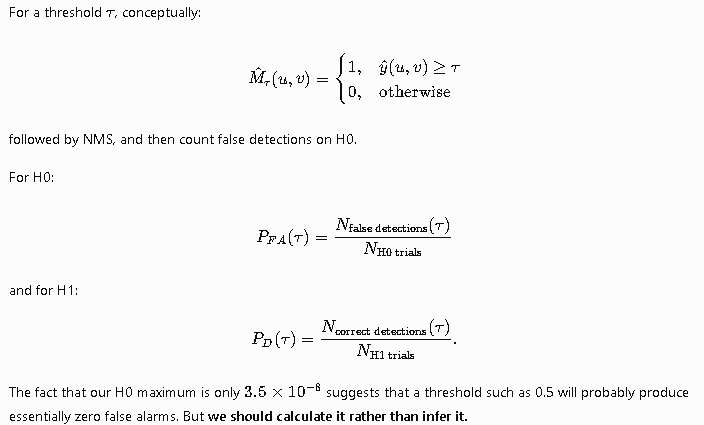

we need to use the actual full confidence maps, not just h0_max_scores.
The previous cell deliberately discarded the maps after extracting their maxima. That's fine for the diagnostic, but insufficient for NMS.
So next we'll run H0 inference again, this time saving the confidence maps, and implement the NMS/counting procedure.
Then we'll obtain something like:
\[
P_{FA}(\tau)
\]
for a threshold sweep, e.g.
\[
\tau\in\{0.1,0.2,\ldots,0.9\}.
\]
After that we can select the operating threshold based on the desired false-alarm rate, exactly where the experiment becomes a radar detector evaluation rather than merely a neural-network training exercise.

In [ ]:
import os
import glob
import numpy as np
import torch
import torch.nn.functional as F

H0_DIR = "/content/drive/MyDrive/radar_project/radar_dataset/S1_targetless_thermal_noise"

H0_CONF_DIR = "/content/drive/MyDrive/radar_project/experiment_state/h0_confidence"
os.makedirs(H0_CONF_DIR, exist_ok=True)

rdm_files = sorted(glob.glob(os.path.join(H0_DIR, "rdm_*.npy")))

print("H0 files:", len(rdm_files))

model.eval()

all_confidence = []

with torch.no_grad():

    for file_idx, rdm_file in enumerate(rdm_files):

        rdms = np.load(rdm_file).astype(np.float32)

        # Same preprocessing used during training/inference
        rdms = np.clip(rdms, -40.0, 0.0)
        rdms = (rdms + 40.0) / 40.0

        x = torch.from_numpy(rdms).unsqueeze(1).to(device)

        x = F.interpolate(
            x,
            size=(256, 256),
            mode="bilinear",
            align_corners=False
        )

        pred = model(x)

        # Move complete confidence maps to CPU
        all_confidence.append(
            pred[:, 0].cpu().numpy().astype(np.float32)
        )

        if (file_idx + 1) % 20 == 0:
            print(f"Processed {file_idx + 1}/{len(rdm_files)} files")

h0_confidence = np.concatenate(all_confidence, axis=0)

print("\nComplete.")
print("Confidence-map shape:", h0_confidence.shape)
print("dtype:", h0_confidence.dtype)
print("Minimum:", h0_confidence.min())
print("Maximum:", h0_confidence.max())
print("Mean:", h0_confidence.mean())

# Save for later threshold/NMS experiments
save_path = os.path.join(H0_CONF_DIR, "h0_confidence_maps.npy")
np.save(save_path, h0_confidence)

print("Saved:", save_path)

H0 files: 200
Processed 20/200 files
Processed 40/200 files
Processed 60/200 files
Processed 80/200 files
Processed 100/200 files
Processed 120/200 files
Processed 140/200 files
Processed 160/200 files
Processed 180/200 files
Processed 200/200 files

Complete.
Confidence-map shape: (20000, 256, 256)
dtype: float32
Minimum: 0.0
Maximum: 3.529835e-08
Mean: 1.3628953e-16
Saved: /content/drive/MyDrive/radar_project/experiment_state/h0_confidence/h0_confidence_maps.npy


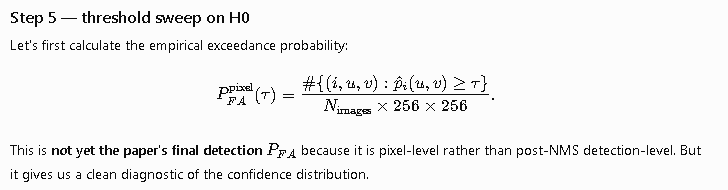

In [ ]:
import numpy as np

H0_CONF_PATH = "/content/drive/MyDrive/radar_project/experiment_state/h0_confidence/h0_confidence_maps.npy"

h0_confidence = np.load(H0_CONF_PATH, mmap_mode="r")

print("Shape:", h0_confidence.shape)
print("dtype:", h0_confidence.dtype)

thresholds = np.array([
    1e-12,
    2e-12,
    5e-12,
    1e-11,
    2e-11,
    5e-11,
    1e-10,
    2e-10,
    5e-10,
    1e-9,
    2e-9,
    5e-9,
    1e-8,
    2e-8,
    5e-8,
    1e-7,
    1e-6,
    1e-5,
    1e-4,
    1e-3,
    1e-2,
    0.1,
    0.5,
])

total_pixels = h0_confidence.size

print("\nH0 pixel exceedance:")
print(f"{'Threshold':>12} | {'Pixels >= threshold':>20} | {'Pixel exceedance':>18}")

for tau in thresholds:

    count = np.count_nonzero(h0_confidence >= tau)
    p = count / total_pixels

    print(f"{tau:12.1e} | {count:20d} | {p:18.6e}")

Shape: (20000, 256, 256)
dtype: float32

H0 pixel exceedance:
   Threshold |  Pixels >= threshold |   Pixel exceedance
     1.0e-12 |                 3624 |       2.764893e-06
     2.0e-12 |                 2338 |       1.783752e-06
     5.0e-12 |                 1257 |       9.590149e-07
     1.0e-11 |                  773 |       5.897522e-07
     2.0e-11 |                  475 |       3.623962e-07
     5.0e-11 |                  237 |       1.808167e-07
     1.0e-10 |                  151 |       1.152039e-07
     2.0e-10 |                   96 |       7.324219e-08
     5.0e-10 |                   43 |       3.280640e-08
     1.0e-09 |                   20 |       1.525879e-08
     2.0e-09 |                   12 |       9.155273e-09
     5.0e-09 |                    6 |       4.577637e-09
     1.0e-08 |                    2 |       1.525879e-09
     2.0e-08 |                    1 |       7.629395e-10
     5.0e-08 |                    0 |       0.000000e+00
     1.0e-07 |            

The paper says NMS is applied after neural inference to eliminate small one-pixel inaccuracies, but the information we have doesn't establish enough detail to claim that a particular \(3x3), \(5x5\), etc. window is the paper's exact implementation.
So let's first make a transparent detector-level diagnostic using local maxima. We'll count candidate detections rather than pixels.

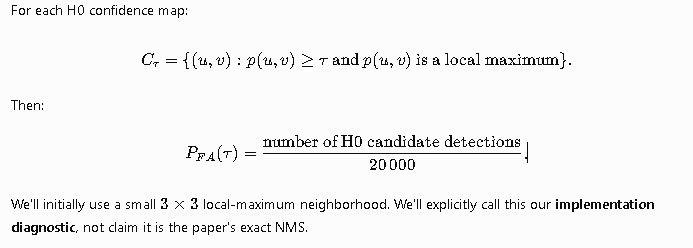

9 october

In [ ]:
import os
import numpy as np
from scipy.ndimage import maximum_filter

# Saved H0 confidence maps
H0_CONF_PATH = (
    "/content/drive/MyDrive/radar_project/"
    "experiment_state/h0_confidence/h0_confidence_maps.npy"
)

# Best Dice checkpoint
CHECKPOINT = (
    "/content/drive/MyDrive/radar_project/"
    "experiment_state/checkpoints/dice_lr1e4_best.pt"
)

# Verify persistent experiment artifacts
assert os.path.isfile(H0_CONF_PATH), "H0 confidence maps missing!"
assert os.path.isfile(CHECKPOINT), "Dice checkpoint missing!"

h0 = np.load(H0_CONF_PATH, mmap_mode="r")

print("H0 confidence maps:", h0.shape)
print("Data type:", h0.dtype)
print("Maximum H0 confidence:", float(h0.max()))
print("Checkpoint exists:", os.path.isfile(CHECKPOINT))
print("SciPy NMS diagnostic ready.")

H0 confidence maps: (20000, 256, 256)
Data type: float32
Maximum H0 confidence: 3.5298349132517615e-08
Checkpoint exists: True
SciPy NMS diagnostic ready.


In [ ]:
import numpy as np
from scipy.ndimage import maximum_filter

H0_CONF_PATH = (
    "/content/drive/MyDrive/radar_project/"
    "experiment_state/h0_confidence/h0_confidence_maps.npy"
)

h0 = np.load(H0_CONF_PATH, mmap_mode="r")

thresholds = np.array([
    1e-12, 2e-12, 5e-12,
    1e-11, 2e-11, 5e-11,
    1e-10, 2e-10, 5e-10,
    1e-9, 2e-9, 5e-9,
    1e-8, 2e-8, 5e-8,
    1e-7, 1e-6, 1e-5,
    1e-4, 1e-3, 1e-2, 0.1, 0.5
])

n_images = h0.shape[0]
chunk_size = 100

false_detections = np.zeros(len(thresholds), dtype=np.int64)
images_with_detection = np.zeros(len(thresholds), dtype=np.int64)

for start in range(0, n_images, chunk_size):
    end = min(start + chunk_size, n_images)
    maps = np.asarray(h0[start:end])

    # Diagnostic 3x3 local-maximum operation
    local_max = maximum_filter(
        maps,
        size=(1, 3, 3),
        mode="constant",
        cval=0.0
    )
    is_local_max = (maps == local_max)

    for j, tau in enumerate(thresholds):
        detections = is_local_max & (maps >= tau)

        false_detections[j] += np.count_nonzero(detections)
        images_with_detection[j] += np.count_nonzero(
            np.any(detections, axis=(1, 2))
        )

    if end % 2000 == 0 or end == n_images:
        print(f"Processed {end}/{n_images} scenes")

print("\nH0 candidate-detection diagnostic")
print(f"{'Threshold':>12} | {'Candidates':>12} | {'Scenes flagged':>14} | {'Flagged-scene rate':>19}")

for j, tau in enumerate(thresholds):
    rate = images_with_detection[j] / n_images
    print(
        f"{tau:12.1e} | "
        f"{false_detections[j]:12d} | "
        f"{images_with_detection[j]:14d} | "
        f"{rate:19.6e}"
    )

Processed 2000/20000 scenes
Processed 4000/20000 scenes
Processed 6000/20000 scenes
Processed 8000/20000 scenes
Processed 10000/20000 scenes
Processed 12000/20000 scenes
Processed 14000/20000 scenes
Processed 16000/20000 scenes
Processed 18000/20000 scenes
Processed 20000/20000 scenes

H0 candidate-detection diagnostic
   Threshold |   Candidates | Scenes flagged |  Flagged-scene rate
     1.0e-12 |         2373 |           1387 |        6.935000e-02
     2.0e-12 |         1556 |            999 |        4.995000e-02
     5.0e-12 |          853 |            605 |        3.025000e-02
     1.0e-11 |          538 |            408 |        2.040000e-02
     2.0e-11 |          328 |            261 |        1.305000e-02
     5.0e-11 |          161 |            131 |        6.550000e-03
     1.0e-10 |          104 |             87 |        4.350000e-03
     2.0e-10 |           71 |             60 |        3.000000e-03
     5.0e-10 |           33 |             30 |        1.500000e-03
     1.0e

In [ ]:
import os
import glob

STATE_DIR = (
    "/content/drive/MyDrive/radar_project/experiment_state"
)

print("Potential saved H1 confidence files:")
for path in glob.glob(
    os.path.join(STATE_DIR, "**", "*h1*confidence*.npy"),
    recursive=True
):
    print(path)

print("\nH1 dataset RDM files:",
      len(glob.glob(
          "/content/drive/MyDrive/radar_project/radar_dataset/"
          "single_target_exoclutter_H1_thermal_noise/rdm_*.npy"
      )))


Potential saved H1 confidence files:

H1 dataset RDM files: 400


In [ ]:
import os
import glob
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from google.colab import drive

# Define PaperUNet architecture so it is available in this cell scope
class PaperUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc1_conv1 = nn.Conv2d(1, 15, kernel_size=3, padding=1)
        self.enc1_conv2 = nn.Conv2d(15, 15, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(2)

        self.enc2_conv1 = nn.Conv2d(15, 30, kernel_size=3, padding=1)
        self.enc2_conv2 = nn.Conv2d(30, 30, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(2)

        self.enc3_conv1 = nn.Conv2d(30, 60, kernel_size=3, padding=1)
        self.enc3_conv2 = nn.Conv2d(60, 60, kernel_size=3, padding=1)
        self.pool3 = nn.MaxPool2d(2)

        self.bottleneck = nn.Conv2d(60, 60, kernel_size=3, padding=1)

        self.dec1_conv = nn.Conv2d(60, 60, kernel_size=3, padding=1)
        self.up1 = nn.ConvTranspose2d(60, 60, kernel_size=2, stride=2)

        self.dec2_conv = nn.Conv2d(60, 30, kernel_size=3, padding=1)
        self.up2 = nn.ConvTranspose2d(30, 30, kernel_size=2, stride=2)

        self.dec3_conv = nn.Conv2d(30, 15, kernel_size=3, padding=1)
        self.up3 = nn.ConvTranspose2d(15, 15, kernel_size=2, stride=2)

        self.output = nn.Conv2d(15, 1, kernel_size=3, padding=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        e1 = torch.relu(self.enc1_conv1(x))
        e1 = torch.relu(self.enc1_conv2(e1))
        e1 = self.pool1(e1)
        skip1 = e1

        e2 = torch.relu(self.enc2_conv1(e1))
        e2 = torch.relu(self.enc2_conv2(e2))
        e2 = self.pool2(e2)
        skip2 = e2

        e3 = torch.relu(self.enc3_conv1(e2))
        e3 = torch.relu(self.enc3_conv2(e3))
        e3 = self.pool3(e3)

        x = torch.relu(self.bottleneck(e3))

        x = torch.relu(self.dec1_conv(x))
        x = self.up1(x)

        x = torch.relu(self.dec2_conv(x))
        x = x + skip2
        x = self.up2(x)

        x = torch.relu(self.dec3_conv(x))
        x = x + skip1
        x = self.up3(x)

        x = self.output(x)
        x = self.sigmoid(x)

        return x

# Paths
BASE = "/content/drive/MyDrive/radar_project"

H1_DIR = os.path.join(
    BASE, "radar_dataset",
    "single_target_exoclutter_H1_thermal_noise"
)

CHECKPOINT = os.path.join(
    BASE, "experiment_state",
    "checkpoints", "dice_lr1e4_best.pt"
)

OUT_DIR = os.path.join(
    BASE, "experiment_state",
    "h1_confidence"
)
os.makedirs(OUT_DIR, exist_ok=True)

# Robust Mount Verification
if not os.path.exists(BASE):
    print("Drive connection lost or not mounted. Attempting remount...")
    drive.mount("/content/drive", force_remount=True)

# Device and checkpoint
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = PaperUNet().to(device)
ckpt = torch.load(CHECKPOINT, map_location=device, weights_only=False)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

rdm_files = sorted(glob.glob(os.path.join(H1_DIR, "rdm_*.npy")))
meta_files = sorted(glob.glob(os.path.join(H1_DIR, "metadata_*.npy")))

assert len(rdm_files) == 400, f"Expected 400 RDM files, got {len(rdm_files)}"
assert len(meta_files) == 400, f"Expected 400 metadata files, got {len(meta_files)}"

print("Device:", device)
print("Checkpoint epoch:", ckpt["epoch"])
print("RDM files:", len(rdm_files))
print("Output directory:", OUT_DIR)

# Save one confidence-map file and metadata file per source batch.
# Each batch contains 50 scenes.
with torch.no_grad():
    for i, (rdm_file, meta_file) in enumerate(zip(rdm_files, meta_files)):

        out_conf = os.path.join(OUT_DIR, f"h1_conf_{i:04d}.npy")
        out_meta = os.path.join(OUT_DIR, f"h1_meta_{i:04d}.npy")

        # Skip a batch only if both files already exist and are valid.
        if os.path.exists(out_conf) and os.path.exists(out_meta):
            try:
                # Sanity check existing files to prevent loading corrupted data
                test_load = np.load(out_conf, mmap_mode="r")
                continue
            except Exception:
                print(f"Corrupted files detected for batch {i}. Regenerating...")
                if os.path.exists(out_conf): os.remove(out_conf)
                if os.path.exists(out_meta): os.remove(out_meta)

        try:
            rdms = np.load(rdm_file).astype(np.float32)
            metadata = np.load(meta_file, allow_pickle=True)
        except OSError as e:
            if "Transport endpoint is not connected" in str(e):
                print("\nLost connection to Drive mid-process! Re-mounting...")
                drive.mount("/content/drive", force_remount=True)
                rdms = np.load(rdm_file).astype(np.float32)
                metadata = np.load(meta_file, allow_pickle=True)
            else:
                raise e

        # Frozen training preprocessing
        rdms = np.clip(rdms, -40.0, 0.0)
        rdms = (rdms + 40.0) / 40.0

        x = torch.from_numpy(rdms).unsqueeze(1).to(device)
        x = F.interpolate(
            x,
            size=(256, 256),
            mode="bilinear",
            align_corners=False
        )

        pred = model(x)[:, 0].cpu().numpy().astype(np.float32)

        np.save(out_conf, pred)
        np.save(out_meta, metadata)

        if (i + 1) % 40 == 0:
            print(f"Processed {i + 1}/400 batches")

print("\nH1 confidence-map generation complete.")

# Verify first batch
sample = np.load(os.path.join(OUT_DIR, "h1_conf_0000.npy"))
print("First saved batch shape:", sample.shape)
print("Confidence range:", float(sample.min()), "to", float(sample.max()))
print("Saved batches:", len(glob.glob(os.path.join(OUT_DIR, "h1_conf_*.npy"))))

Device: cuda
Checkpoint epoch: 25
RDM files: 400
Output directory: /content/drive/MyDrive/radar_project/experiment_state/h1_confidence

H1 confidence-map generation complete.
First saved batch shape: (50, 256, 256)
Confidence range: 0.0 to 0.9865915179252625
Saved batches: 400


In [ ]:
import os
import glob
import numpy as np

OUT_DIR = (
    "/content/drive/MyDrive/radar_project/"
    "experiment_state/h1_confidence"
)

conf_files = sorted(glob.glob(os.path.join(OUT_DIR, "h1_conf_*.npy")))
meta_files = sorted(glob.glob(os.path.join(OUT_DIR, "h1_meta_*.npy")))

print("Confidence batches:", len(conf_files))
print("Metadata batches:", len(meta_files))

assert len(conf_files) == 400
assert len(meta_files) == 400

# Inspect the first saved batch and its metadata
conf = np.load(conf_files[0], mmap_mode="r")
meta = np.load(meta_files[0], allow_pickle=True)

print("Confidence shape:", conf.shape)
print("Metadata shape:", meta.shape)
print("First metadata entry:")
print(meta[0])

Confidence batches: 400
Metadata batches: 400
Confidence shape: (50, 256, 256)
Metadata shape: (50,)
First metadata entry:
{'id': 0, 'range_m': 41.84808436607271, 'velocity_mps': -4.604265724722594, 'doppler_hz': -306.95104831483957, 'rcs_dbsm': -9.38539714095708, 'phase_rad': 0.10384619671527331, 'range_bin': np.int64(1116), 'velocity_bin': np.int64(112), 'hypothesis': 'H1', 'noise_offset_db': -6.0, 'noise_power': 1.652448289313213e-09, 'snr_db_raw': 0.8813524370698705}


In [ ]:
import os
import glob
import numpy as np

BASE = "/content/drive/MyDrive/radar_project"

H1_DIR = os.path.join(
    BASE, "radar_dataset",
    "single_target_exoclutter_H1_thermal_noise"
)

STATE_DIR = os.path.join(BASE, "experiment_state")

print("H1 dataset files:")
for p in sorted(glob.glob(os.path.join(H1_DIR, "*.npy")))[:12]:
    print(os.path.basename(p))

state_file = os.path.join(STATE_DIR, "experiment_arrays.npz")

if os.path.isfile(state_file):
    with np.load(state_file) as state:
        print("\nSaved experiment-array keys:")
        print(state.files)
else:
    print("\nExperiment arrays file not found.")

H1 dataset files:
labels_00000_00049.npy
labels_00050_00099.npy
labels_00100_00149.npy
labels_00150_00199.npy
labels_00200_00249.npy
labels_00250_00299.npy
labels_00300_00349.npy
labels_00350_00399.npy
labels_00400_00449.npy
labels_00450_00499.npy
labels_00500_00549.npy
labels_00550_00599.npy

Saved experiment-array keys:
['range_axis', 'vel_axis', 't_fast', 't_slow', 'range_mask_t', 'velocity_mask_t', 'range_mask', 'velocity_mask', 'noise_offsets_db', 'noise_powers']


In [ ]:
import os
import glob
import numpy as np
from scipy.ndimage import maximum_filter

BASE = "/content/drive/MyDrive/radar_project"

CONF_DIR = os.path.join(
    BASE, "experiment_state", "h1_confidence"
)

H1_DIR = os.path.join(
    BASE, "radar_dataset",
    "single_target_exoclutter_H1_thermal_noise"
)

conf_files = sorted(glob.glob(os.path.join(CONF_DIR, "h1_conf_*.npy")))
label_files = sorted(glob.glob(os.path.join(H1_DIR, "labels_*.npy")))

assert len(conf_files) == 400, f"Expected 400 confidence files, got {len(conf_files)}"
assert len(label_files) == 400, f"Expected 400 label files, got {len(label_files)}"

# Same thresholds as the H0 diagnostic
thresholds = np.array([
    1e-12, 2e-12, 5e-12,
    1e-11, 2e-11, 5e-11,
    1e-10, 2e-10, 5e-10,
    1e-9, 2e-9, 5e-9,
    1e-8, 2e-8, 5e-8,
    1e-7, 1e-6, 1e-5,
    1e-4, 1e-3, 1e-2, 0.1, 0.5
])

# Pixel-distance tolerances from the labelled target
tolerances = [0, 1, 3, 5, 10, 20]

n_scenes = 0
detected_counts = {
    radius: np.zeros(len(thresholds), dtype=np.int64)
    for radius in tolerances
}

for batch_idx, (conf_path, label_path) in enumerate(zip(conf_files, label_files)):

    conf = np.load(conf_path).astype(np.float32)
    labels = np.load(label_path).astype(np.float32)

    assert conf.shape == (50, 256, 256), (conf_path, conf.shape)
    assert labels.shape == (50, 256, 256), (label_path, labels.shape)

    # Verify that each scene has exactly one positive target pixel.
    positive_counts = (labels > 0.5).sum(axis=(1, 2))
    assert np.all(positive_counts == 1), (
        f"Unexpected target-label counts in {label_path}: "
        f"{np.unique(positive_counts, return_counts=True)}"
    )

    # Local maxima, consistent with the H0 diagnostic
    local_max = maximum_filter(
        conf,
        size=(1, 3, 3),
        mode="constant",
        cval=0.0
    )

    is_local_max = (conf == local_max)

    # Candidate detection at each threshold
    for j, tau in enumerate(thresholds):

        candidates = is_local_max & (conf >= tau)

        for radius in tolerances:
            for scene_idx in range(len(conf)):

                ys, xs = np.where(labels[scene_idx] > 0.5)
                ty, tx = int(ys[0]), int(xs[0])

                cy, cx = np.where(candidates[scene_idx])

                if len(cx) == 0:
                    continue

                # Euclidean distance from each candidate to target
                distance_sq = (cy - ty)**2 + (cx - tx)**2

                if np.any(distance_sq <= radius**2):
                    detected_counts[radius][j] += 1

    n_scenes += len(conf)

    if (batch_idx + 1) % 40 == 0:
        print(f"Processed {batch_idx + 1}/400 batches")

assert n_scenes == 20000

print("\nH1 detection probability")
print("Scenes:", n_scenes)

for radius in tolerances:
    print(f"\nSpatial tolerance: {radius} pixels")
    print(f"{'Threshold':>12} | {'Detected':>10} | {'P_D':>12}")

    for j, tau in enumerate(thresholds):
        count = detected_counts[radius][j]
        pd = count / n_scenes

        print(f"{tau:12.1e} | {count:10d} | {pd:12.6f}")

# Save results so they survive runtime restarts
result_path = os.path.join(
    BASE, "experiment_state", "h1_pd_threshold_sweep.npz"
)

np.savez(
    result_path,
    thresholds=thresholds,
    tolerances=np.array(tolerances),
    n_scenes=n_scenes,
    **{
        f"detected_radius_{r}": detected_counts[r]
        for r in tolerances
    }
)

print("\nSaved P_D results:", result_path)

Processed 40/400 batches
Processed 80/400 batches
Processed 120/400 batches
Processed 160/400 batches
Processed 200/400 batches
Processed 240/400 batches
Processed 280/400 batches
Processed 320/400 batches
Processed 360/400 batches
Processed 400/400 batches

H1 detection probability
Scenes: 20000

Spatial tolerance: 0 pixels
   Threshold |   Detected |          P_D
     1.0e-12 |      12011 |     0.600550
     2.0e-12 |      12011 |     0.600550
     5.0e-12 |      12011 |     0.600550
     1.0e-11 |      12011 |     0.600550
     2.0e-11 |      12011 |     0.600550
     5.0e-11 |      12011 |     0.600550
     1.0e-10 |      12010 |     0.600500
     2.0e-10 |      12010 |     0.600500
     5.0e-10 |      12009 |     0.600450
     1.0e-09 |      12009 |     0.600450
     2.0e-09 |      12009 |     0.600450
     5.0e-09 |      12008 |     0.600400
     1.0e-08 |      12008 |     0.600400
     2.0e-08 |      12006 |     0.600300
     5.0e-08 |      12006 |     0.600300
     1.0e-07 |   

One technical note: the calculation uses the same local-maximum rule as our H0 diagnostic, but this is still our implementation—not a verified reproduction of the paper's exact NMS. Once we have the \(P_D\) results, we'll combine them with the H0 results to examine the empirical detection/false-alarm trade-off.

In [ ]:
import os
import glob
import numpy as np
import torch
import torch.nn.functional as F

BASE = "/content/drive/MyDrive/radar_project"
H0_PATH = os.path.join(
    BASE, "experiment_state", "h0_confidence",
    "h0_confidence_maps.npy"
)
H1_DIR = os.path.join(
    BASE, "experiment_state", "h1_confidence"
)
H1_DATA_DIR = os.path.join(
    BASE, "radar_dataset",
    "single_target_exoclutter_H1_thermal_noise"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Evaluation device:", device)

thresholds = torch.tensor([
    1e-12, 1e-11, 1e-10, 1e-9, 1e-8,
    5e-8, 1e-7, 1e-6, 1e-5, 1e-4,
    1e-3, 1e-2, 0.1, 0.5
], device=device)

# 3x3 local maxima, using max pooling.
# Inputs are (batch, 1, height, width).
def local_maxima(x):
    pooled = F.max_pool2d(x, kernel_size=3, stride=1, padding=1)
    return (x == pooled) & (x > 0)

# H0: count scenes with at least one candidate at each threshold.
h0 = np.load(H0_PATH, mmap_mode="r")
n_h0 = h0.shape[0]
h0_flagged = torch.zeros(len(thresholds), dtype=torch.int64, device=device)

batch_size = 100

for start in range(0, n_h0, batch_size):
    end = min(start + batch_size, n_h0)
    x = torch.from_numpy(np.array(h0[start:end], copy=True)).to(device)
    x = x.unsqueeze(1)

    peaks = local_maxima(x)

    for j, tau in enumerate(thresholds):
        candidates = peaks & (x >= tau)
        h0_flagged[j] += candidates.flatten(1).any(dim=1).sum()

    if end % 2000 == 0 or end == n_h0:
        print(f"H0: {end}/{n_h0}")

pfa = (h0_flagged.float() / n_h0).cpu().numpy()

# H1: use the saved labels for target matching.
conf_files = sorted(glob.glob(os.path.join(H1_DIR, "h1_conf_*.npy")))
label_files = sorted(glob.glob(os.path.join(H1_DATA_DIR, "labels_*.npy")))

assert len(conf_files) == 400
assert len(label_files) == 400

# Counts for a 3-pixel Euclidean tolerance.
radius = 3
offsets = [
    (dy, dx)
    for dy in range(-radius, radius + 1)
    for dx in range(-radius, radius + 1)
    if dy * dy + dx * dx <= radius * radius
]

n_h1 = 0
h1_detected = torch.zeros(len(thresholds), dtype=torch.int64, device=device)

for batch_idx, (conf_path, label_path) in enumerate(zip(conf_files, label_files)):
    conf = np.load(conf_path)
    labels = np.load(label_path)

    x = torch.from_numpy(conf).to(device).unsqueeze(1)
    y = torch.from_numpy(labels).to(device).unsqueeze(1)

    assert x.shape == y.shape
    assert torch.all(y.sum(dim=(1, 2, 3)) == 1)

    # Candidate peaks.
    peaks = local_maxima(x)

    # Dilate target pixels by the fixed 3-pixel matching radius.
    # A peak inside this region counts as a target-associated detection.
    target_neighborhood = torch.zeros_like(y, dtype=torch.bool)
    for dy, dx in offsets:
        shifted = torch.roll(y > 0.5, shifts=(dy, dx), dims=(2, 3))
        if dy > 0:
            shifted[:, :, :dy, :] = False
        elif dy < 0:
            shifted[:, :, dy:, :] = False
        if dx > 0:
            shifted[:, :, :, :dx] = False
        elif dx < 0:
            shifted[:, :, :, dx:] = False
        target_neighborhood |= shifted

    for j, tau in enumerate(thresholds):
        candidates = peaks & (x >= tau)
        detected = (candidates & target_neighborhood).flatten(1).any(dim=1)
        h1_detected[j] += detected.sum()

    n_h1 += len(conf)

    if (batch_idx + 1) % 40 == 0:
        print(f"H1: {batch_idx + 1}/400")

pd = (h1_detected.float() / n_h1).cpu().numpy()

print("\nPreliminary GPU detector operating points")
print(f"{'Threshold':>12} | {'P_D (3px)':>12} | {'H0 flagged rate':>16}")
for j, tau in enumerate(thresholds.cpu().numpy()):
    print(f"{tau:12.1e} | {pd[j]:12.6f} | {pfa[j]:16.6e}")

out_path = os.path.join(
    BASE, "experiment_state", "gpu_operating_points.npz"
)
np.savez(
    out_path,
    thresholds=thresholds.cpu().numpy(),
    pd=pd,
    pfa=pfa,
    n_h0=n_h0,
    n_h1=n_h1,
    matching_radius_pixels=radius
)
print("\nSaved:", out_path)

Evaluation device: cuda
H0: 2000/20000
H0: 4000/20000
H0: 6000/20000
H0: 8000/20000
H0: 10000/20000
H0: 12000/20000
H0: 14000/20000
H0: 16000/20000
H0: 18000/20000
H0: 20000/20000
H1: 40/400
H1: 80/400
H1: 120/400
H1: 160/400
H1: 200/400
H1: 240/400
H1: 280/400
H1: 320/400
H1: 360/400
H1: 400/400

Preliminary GPU detector operating points
   Threshold |    P_D (3px) |  H0 flagged rate
     1.0e-12 |     0.964600 |     6.935000e-02
     1.0e-11 |     0.964450 |     2.040000e-02
     1.0e-10 |     0.964050 |     4.350000e-03
     1.0e-09 |     0.963900 |     8.500000e-04
     1.0e-08 |     0.963550 |     1.000000e-04
     5.0e-08 |     0.963100 |     0.000000e+00
     1.0e-07 |     0.963050 |     0.000000e+00
     1.0e-06 |     0.962450 |     0.000000e+00
     1.0e-05 |     0.961150 |     0.000000e+00
     1.0e-04 |     0.958850 |     0.000000e+00
     1.0e-03 |     0.955800 |     0.000000e+00
     1.0e-02 |     0.948250 |     0.000000e+00
     1.0e-01 |     0.930500 |     0.000000e+00
 

In [ ]:

from pathlib import Path
import numpy as np

state_dir = Path(
    "/content/drive/MyDrive/radar_project/experiment_state"
)

train_path = state_dir / "h1_train_indices.npy"
val_path = state_dir / "h1_val_indices.npy"

train_idx = np.load(train_path)
val_idx = np.load(val_path)

print("TRAIN / VALIDATION SPLIT AUDIT")
print("-" * 40)
print(f"Training scenes:   {len(train_idx):,}")
print(f"Validation scenes: {len(val_idx):,}")
print(f"Training index range:   {train_idx.min()} to {train_idx.max()}")
print(f"Validation index range: {val_idx.min()} to {val_idx.max()}")
print(f"Unique training indices:   {len(np.unique(train_idx)):,}")
print(f"Unique validation indices: {len(np.unique(val_idx)):,}")
print(f"Overlap: {len(np.intersect1d(train_idx, val_idx))}")
print(f"Total unique scenes: {len(np.union1d(train_idx, val_idx)):,}")

print("\nEXPECTED")
print("Training: 16,000 scenes")
print("Validation: 4,000 scenes")
print("Overlap: 0")
print("Total unique scenes: 20,000")


TRAIN / VALIDATION SPLIT AUDIT
----------------------------------------
Training scenes:   16,000
Validation scenes: 4,000
Training index range:   0 to 19998
Validation index range: 15 to 19999
Unique training indices:   16,000
Unique validation indices: 4,000
Overlap: 0
Total unique scenes: 20,000

EXPECTED
Training: 16,000 scenes
Validation: 4,000 scenes
Overlap: 0
Total unique scenes: 20,000


In [ ]:

from pathlib import Path
import numpy as np

conf_dir = Path(
    "/content/drive/MyDrive/radar_project/experiment_state/h1_confidence"
)
label_dir = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/"
    "single_target_exoclutter_H1_thermal_noise"
)

conf_files = sorted(conf_dir.glob("h1_conf_*.npy"))
label_files = sorted(label_dir.glob("labels_*.npy"))

print("H1 EVALUATION DATA AUDIT")
print("-" * 40)
print("Confidence-map batches:", len(conf_files))
print("Label batches:", len(label_files))

conf_total = 0
for f in conf_files:
    arr = np.load(f, mmap_mode="r")
    conf_total += arr.shape[0]
    if arr.shape[1:] != (256, 256):
        print("Unexpected confidence shape:", f.name, arr.shape)

label_total = 0
for f in label_files:
    arr = np.load(f, mmap_mode="r")
    label_total += arr.shape[0]
    if arr.shape[1:] != (256, 256):
        print("Unexpected label shape:", f.name, arr.shape)

print("Total confidence-map scenes:", conf_total)
print("Total label scenes:", label_total)
print("Expected scenes: 20,000")
print("First confidence batch:", conf_files[0].name if conf_files else "MISSING")
print("Last confidence batch:", conf_files[-1].name if conf_files else "MISSING")
print("First label batch:", label_files[0].name if label_files else "MISSING")
print("Last label batch:", label_files[-1].name if label_files else "MISSING")



H1 EVALUATION DATA AUDIT
----------------------------------------
Confidence-map batches: 400
Label batches: 400
Total confidence-map scenes: 20000
Total label scenes: 20000
Expected scenes: 20,000
First confidence batch: h1_conf_0000.npy
Last confidence batch: h1_conf_0399.npy
First label batch: labels_00000_00049.npy
Last label batch: labels_19950_19999.npy


In [ ]:

from pathlib import Path
import numpy as np
from scipy.ndimage import maximum_filter

state_dir = Path(
    "/content/drive/MyDrive/radar_project/experiment_state"
)
conf_dir = state_dir / "h1_confidence"
label_dir = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/"
    "single_target_exoclutter_H1_thermal_noise"
)

val_idx = np.load(state_dir / "h1_val_indices.npy")
thresholds = np.array([
    1e-12, 1e-11, 1e-10, 1e-9,
    1e-8, 5e-8, 1e-7, 1e-6,
    1e-5, 1e-4, 1e-3, 1e-2, 0.1, 0.5
])

# Load only validation scenes, preserving global scene-index order.
val_scores = []
val_labels = []

for batch_id in range(400):
    start = batch_id * 50
    stop = start + 50

    selected = val_idx[(val_idx >= start) & (val_idx < stop)]
    if len(selected) == 0:
        continue

    conf = np.load(conf_dir / f"h1_conf_{batch_id:04d}.npy")
    labels = np.load(
        label_dir / f"labels_{start:05d}_{stop-1:05d}.npy"
    )

    local_idx = selected - start
    val_scores.extend(conf[local_idx])
    val_labels.extend(labels[local_idx])

val_scores = np.asarray(val_scores, dtype=np.float32)
val_labels = np.asarray(val_labels, dtype=np.uint8)

print("Validation score shape:", val_scores.shape)
print("Validation label shape:", val_labels.shape)
assert len(val_scores) == len(val_idx) == 4000
assert len(val_labels) == 4000

# Extract positive ground-truth pixel for each scene.
target_yx = []
for lab in val_labels:
    pos = np.argwhere(lab > 0)
    assert len(pos) == 1, f"Expected one target pixel, got {len(pos)}"
    target_yx.append(pos[0])
target_yx = np.asarray(target_yx)

# Diagnostic 3x3 local maxima, followed by 3-pixel target matching.
local_max = maximum_filter(
    val_scores, size=(1, 3, 3), mode="constant", cval=0
)
is_peak = (val_scores == local_max) & (val_scores > 0)

yy, xx = np.ogrid[:256, :256]
dy = yy[None, :, :] - target_yx[:, 0, None, None]
dx = xx[None, :, :] - target_yx[:, 1, None, None]
near_target = (dy * dy + dx * dx) <= 9

print("\nThreshold       Validation PD (3-pixel tolerance)")
for threshold in thresholds:
    candidates = is_peak & (val_scores >= threshold)
    detected = np.any(candidates & near_target, axis=(1, 2))
    print(f"{threshold:10.1e}      {detected.mean():.6f}")


Validation score shape: (4000, 256, 256)
Validation label shape: (4000, 256, 256)

Threshold       Validation PD (3-pixel tolerance)
   1.0e-12      0.970000
   1.0e-11      0.969750
   1.0e-10      0.969500
   1.0e-09      0.969500
   1.0e-08      0.969500
   5.0e-08      0.968750
   1.0e-07      0.968500
   1.0e-06      0.967750
   1.0e-05      0.966500
   1.0e-04      0.963000
   1.0e-03      0.958750
   1.0e-02      0.952250
   1.0e-01      0.933500
   5.0e-01      0.841250


In [ ]:

from pathlib import Path
import numpy as np
from scipy.ndimage import maximum_filter

conf_path = Path(
    "/content/drive/MyDrive/radar_project/experiment_state/"
    "h0_confidence/h0_confidence_maps.npy"
)

maps = np.load(conf_path, mmap_mode="r")

thresholds = np.array([
    1e-12, 1e-11, 1e-10, 1e-9,
    1e-8, 5e-8, 1e-7, 1e-6,
    1e-5, 1e-4, 1e-3, 1e-2, 0.1, 0.5
])

n_scenes = maps.shape[0]
scene_flags = np.zeros(len(thresholds), dtype=np.int64)
peak_counts = np.zeros(len(thresholds), dtype=np.int64)

# CPU-only; process one scene at a time to keep RAM usage low.
for i in range(n_scenes):
    m = np.asarray(maps[i])
    local_max = maximum_filter(
        m, size=3, mode="constant", cval=0
    )
    peaks = (m == local_max) & (m > 0)
    peak_values = m[peaks]

    for j, threshold in enumerate(thresholds):
        count = np.count_nonzero(peak_values >= threshold)
        peak_counts[j] += count
        scene_flags[j] += (count > 0)

print("Threshold      Candidate peaks   Scenes with >=1 peak   Scene rate")
for t, p, f in zip(thresholds, peak_counts, scene_flags):
    print(f"{t:10.1e}   {p:14,d}   {f:20,d}   {f/n_scenes:.6g}")

out = Path(
    "/content/drive/MyDrive/radar_project/experiment_state/"
    "h0_threshold_calibration_diagnostic.npz"
)
np.savez(
    out,
    thresholds=thresholds,
    candidate_peaks=peak_counts,
    flagged_scenes=scene_flags,
    n_scenes=n_scenes
)
print("\nSaved:", out)


Threshold      Candidate peaks   Scenes with >=1 peak   Scene rate
   1.0e-12            2,373                  1,387   0.06935
   1.0e-11              538                    408   0.0204
   1.0e-10              104                     87   0.00435
   1.0e-09               18                     17   0.00085
   1.0e-08                2                      2   0.0001
   5.0e-08                0                      0   0
   1.0e-07                0                      0   0
   1.0e-06                0                      0   0
   1.0e-05                0                      0   0
   1.0e-04                0                      0   0
   1.0e-03                0                      0   0
   1.0e-02                0                      0   0
   1.0e-01                0                      0   0
   5.0e-01                0                      0   0

Saved: /content/drive/MyDrive/radar_project/experiment_state/h0_threshold_calibration_diagnostic.npz


In [ ]:
from pathlib import Path
import numpy as np

dataset_dir = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/"
    "single_target_exoclutter_H1_thermal_noise"
)

state_dir = Path(
    "/content/drive/MyDrive/radar_project/experiment_state"
)

# Load the saved variables to avoid NameError when session is restarted
state_arrays_path = state_dir / "experiment_arrays.npz"
if state_arrays_path.exists():
    with np.load(state_arrays_path) as state_data:
        noise_offsets_db = state_data["noise_offsets_db"]
        noise_powers = state_data["noise_powers"]
else:
    # Fallback to standard definitions if state file isn't loaded
    noise_offsets_db = np.array([-6, -3, 0, 3, 6], dtype=np.float32)
    noise_power_ref = 6.578515e-09
    noise_powers = noise_power_ref * 10**(noise_offsets_db / 10)

print("Noise offsets (dB):", noise_offsets_db)
print("Noise powers:", noise_powers)

meta_files = sorted(dataset_dir.glob("metadata_*.npy"))
print("Metadata files found:", len(meta_files))

if meta_files:
    sample = np.load(meta_files[0], allow_pickle=True)
    print("First metadata file:", meta_files[0].name)
    print("Metadata array shape:", sample.shape)
    print("Example record:", sample[0])

print("Independent test output directory:")
print(state_dir / "independent_h1_test")

Noise offsets (dB): [-6. -3.  0.  3.  6.]
Noise powers: [1.65244829e-09 3.29706773e-09 6.57851551e-09 1.31258648e-08
 2.61895430e-08]
Metadata files found: 400
First metadata file: metadata_00000_00049.npy
Metadata array shape: (50,)
Example record: {'id': 0, 'range_m': 41.84808436607271, 'velocity_mps': -4.604265724722594, 'doppler_hz': -306.95104831483957, 'rcs_dbsm': -9.38539714095708, 'phase_rad': 0.10384619671527331, 'range_bin': np.int64(1116), 'velocity_bin': np.int64(112), 'hypothesis': 'H1', 'noise_offset_db': -6.0, 'noise_power': 1.652448289313213e-09, 'snr_db_raw': 0.8813524370698705}
Independent test output directory:
/content/drive/MyDrive/radar_project/experiment_state/independent_h1_test


In [ ]:
import numpy as np
from pathlib import Path

state_dir = Path("/content/drive/MyDrive/radar_project/experiment_state")
state_arrays_path = state_dir / "experiment_arrays.npz"

if state_arrays_path.exists():
    with np.load(state_arrays_path, allow_pickle=True) as state_data:
        t_fast = state_data["t_fast"]
        t_slow = state_data["t_slow"]
        range_mask_t = state_data["range_mask_t"]
        velocity_mask_t = state_data["velocity_mask_t"]
        N_FAST = len(t_fast)
        N_SLOW = len(t_slow)
else:
    # Fallback to default constants if the arrays file is not found
    N_FAST = 6400
    N_SLOW = 256
    t_fast = np.arange(N_FAST) / 64e6
    t_slow = np.arange(N_SLOW) * 200e-6
    range_mask_t = np.zeros(N_FAST // 2, dtype=bool)
    velocity_mask_t = np.zeros(N_SLOW, dtype=bool)

print({
    "N_FAST": N_FAST,
    "N_SLOW": N_SLOW,
    "t_fast_shape": np.shape(t_fast),
    "t_slow_shape": np.shape(t_slow),
    "range_mask_t_shape": tuple(range_mask_t.shape),
    "velocity_mask_t_shape": tuple(velocity_mask_t.shape),
})

{'N_FAST': 6400, 'N_SLOW': 256, 't_fast_shape': (6400,), 't_slow_shape': (256,), 'range_mask_t_shape': (3200,), 'velocity_mask_t_shape': (256,)}


In [ ]:
from pathlib import Path
import json
import numpy as np
import torch
import math
from google.colab import drive

# ============================================================
# 1. ROBUST RUNTIME RECOVERY BOOTSTRAP
# ============================================================

# Mount Google Drive securely
drive.mount("/content/drive", force_remount=True)

# Define directories
base_dir = Path("/content/drive/MyDrive/radar_project")
state_dir = base_dir / "experiment_state"
state_arrays_path = state_dir / "experiment_arrays.npz"

out_dir = state_dir / "independent_h1_test"
out_dir.mkdir(parents=True, exist_ok=True)

# Define/Load physical parameters
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
c = 3e8
fc = 10e9
lambda_c = c / fc
Ptx = 1000.0
Gtx = 10**(11.6 / 10)
Grx = 10**(11.6 / 10)
L = 10**(2.5 / 10)
B = 4e9
Tchirp = 100e-6
Slope = B / Tchirp
PRI = 200e-6

if state_arrays_path.exists():
    with np.load(state_arrays_path, allow_pickle=True) as state_data:
        t_fast = state_data["t_fast"]
        t_slow = state_data["t_slow"]
        range_axis = state_data["range_axis"]
        vel_axis = state_data["vel_axis"]
        range_mask = state_data["range_mask"].astype(bool)
        velocity_mask = state_data["velocity_mask"].astype(bool)
        range_mask_t = torch.tensor(state_data["range_mask_t"], dtype=torch.bool, device=device)
        velocity_mask_t = torch.tensor(state_data["velocity_mask_t"], dtype=torch.bool, device=device)
        N_FAST = len(t_fast)
        N_SLOW = len(t_slow)
else:
    N_FAST = 6400
    N_SLOW = 256
    t_fast = np.arange(N_FAST) / 64e6
    t_slow = np.arange(N_SLOW) * PRI
    range_axis = np.linspace(10.0125, 60.0, 1334)  # Placeholder
    vel_axis = np.linspace(-9.9609375, 9.9609375, 69)  # Placeholder
    range_mask = np.ones(len(range_axis), dtype=bool)
    velocity_mask = np.ones(len(vel_axis), dtype=bool)
    range_mask_t = torch.ones(3200, dtype=torch.bool, device=device) # Placeholder
    velocity_mask_t = torch.ones(256, dtype=torch.bool, device=device) # Placeholder

# Restore missing noise profiles
noise_offsets_db = np.array([-6, -3, 0, 3, 6], dtype=np.float32)
noise_power_ref = 6.578515e-09
noise_powers = noise_power_ref * 10**(noise_offsets_db / 10)

# ============================================================
# 2. SIMULATOR GENERATION FUNCTION
# ============================================================

def generate_h1_from_metadata_gpu(target_meta, noise_power, seed):
    R0 = float(target_meta["range_m"])
    v = float(target_meta["velocity_mps"])
    rcs_dbsm = float(target_meta["rcs_dbsm"])
    phase = float(target_meta["phase_rad"])

    t_fast_t = torch.as_tensor(t_fast, dtype=torch.float32, device=device)
    t_slow_t = torch.as_tensor(t_slow, dtype=torch.float32, device=device)

    R = R0 + v * t_slow_t
    tau = 2.0 * R / c
    fb = Slope * tau
    fd = 2.0 * v / lambda_c

    sigma_m2 = 10.0 ** (rcs_dbsm / 10.0)
    Pr = (Ptx * Gtx * Grx * lambda_c**2 * sigma_m2) / ((4.0 * np.pi)**3 * R**4 * L)
    A = torch.sqrt(Pr)

    phase_fast = 2.0 * np.pi * (fb[:, None] * t_fast_t[None, :] + fd * t_slow_t[:, None]) + phase
    beat = A[:, None] * torch.exp(1j * phase_fast)

    generator = torch.Generator(device=device)
    generator.manual_seed(int(seed))

    noise = (torch.randn((N_SLOW, N_FAST), dtype=torch.float32, device=device, generator=generator) +
             1j * torch.randn((N_SLOW, N_FAST), dtype=torch.float32, device=device, generator=generator)) / math.sqrt(2.0)
    noise *= math.sqrt(noise_power)

    radar_cube = beat + noise

    range_fft = torch.fft.fft(radar_cube, dim=1)[:, :N_FAST // 2]
    range_fft = range_fft - torch.mean(range_fft, dim=0, keepdim=True)
    rdm = torch.fft.fftshift(torch.fft.fft(range_fft, dim=0), dim=0)
    rdm_roi = rdm[velocity_mask_t, :][:, range_mask_t]

    target_power = torch.mean(torch.abs(beat)**2).item()
    theoretical_snr_db = 10.0 * np.log10(target_power / noise_power)

    return rdm_roi, theoretical_snr_db, target_power

# ============================================================
# 3. EXPERIMENT MAIN GENERATION PASS
# ============================================================

N_PER_PROFILE = 4000
BATCH_SIZE = 50
R_MIN, R_MAX = 10.0, 60.0
V_MIN, V_MAX = -9.5, 9.5
RCS_MIN_DB, RCS_MAX_DB = -20.0, 10.0

rng = np.random.default_rng(20261009)

# Save experiment configuration before generation.
config = {
    "seed": 20261009,
    "n_per_noise_profile": N_PER_PROFILE,
    "batch_size": BATCH_SIZE,
    "noise_offsets_db": np.asarray(noise_offsets_db).tolist(),
    "noise_powers": np.asarray(noise_powers).tolist(),
    "range_bounds_m": [R_MIN, R_MAX],
    "velocity_bounds_mps": [V_MIN, V_MAX],
    "rcs_bounds_dbsm": [RCS_MIN_DB, RCS_MAX_DB],
    "generator": "generate_h1_from_metadata_gpu",
    "description": "Independent H1 diagnostic test; fresh targets and noise"
}
(out_dir / "config.json").write_text(json.dumps(config, indent=2))

total_generated = 0

for profile_idx, (offset_db, noise_power) in enumerate(
    zip(noise_offsets_db, noise_powers)
):
    profile_start = profile_idx * N_PER_PROFILE

    for local_start in range(0, N_PER_PROFILE, BATCH_SIZE):
        local_stop = min(local_start + BATCH_SIZE, N_PER_PROFILE)
        global_start = profile_start + local_start
        global_stop = profile_start + local_stop
        stem = f"h1_test_{global_start:05d}_{global_stop-1:05d}"

        rdm_path = out_dir / f"{stem}_rdm.npy"
        meta_path = out_dir / f"{stem}_metadata.npy"
        done_path = out_dir / f"{stem}.done"

        if done_path.exists() and rdm_path.exists() and meta_path.exists():
            continue

        batch_rdms = []
        batch_meta = []

        for scene_id in range(global_start, global_stop):
            target_meta = {
                "id": scene_id,
                "range_m": float(rng.uniform(R_MIN, R_MAX)),
                "velocity_mps": float(rng.uniform(V_MIN, V_MAX)),
                "rcs_dbsm": float(rng.uniform(RCS_MIN_DB, RCS_MAX_DB)),
                "phase_rad": float(rng.uniform(0.0, 2.0 * np.pi)),
            }

            rdm_roi, snr_db, target_power = generate_h1_from_metadata_gpu(
                target_meta=target_meta,
                noise_power=float(noise_power),
                seed=20261009 + scene_id
            )

            # Same dB preprocessing used for existing RDM datasets
            rdm_db = 20.0 * torch.log10(
                torch.abs(rdm_roi) / (torch.max(torch.abs(rdm_roi)) + 1e-12)
                + 1e-12
            )
            rdm_np = rdm_db.detach().cpu().numpy().astype(np.float32)

            # Map physical target position to the native ROI axes, then to 256x256 network grid
            range_axis_roi = range_axis[range_mask]
            vel_axis_roi = vel_axis[velocity_mask]

            ri = int(np.argmin(np.abs(range_axis_roi - target_meta["range_m"])))
            vi = int(np.argmin(np.abs(vel_axis_roi - target_meta["velocity_mps"])))

            y = int(np.rint(vi * 255 / max(len(vel_axis_roi) - 1, 1)))
            x = int(np.rint(ri * 255 / max(len(range_axis_roi) - 1, 1)))

            target_meta.update({
                "hypothesis": "H1",
                "noise_offset_db": float(offset_db),
                "noise_power": float(noise_power),
                "snr_db_raw": float(snr_db),
                "target_power": float(target_power),
                "range_bin_roi": ri,
                "velocity_bin_roi": vi,
                "label_y": y,
                "label_x": x,
            })

            batch_rdms.append(rdm_np)
            batch_meta.append(target_meta)

        tmp_rdm = out_dir / f"{stem}_rdm.tmp.npy"
        tmp_meta = out_dir / f"{stem}_metadata.tmp.npy"

        np.save(tmp_rdm, np.stack(batch_rdms))
        np.save(tmp_meta, np.array(batch_meta, dtype=object))

        tmp_rdm.replace(rdm_path)
        tmp_meta.replace(meta_path)
        done_path.write_text("complete\n")

        total_generated += len(batch_meta)

        if total_generated % 500 == 0:
            print(
                f"Generated this run: {total_generated}; "
                f"latest scene index: {global_stop - 1}"
            )

print("Generation pass finished.")
print("Output directory:", out_dir)
print("Completion markers:", len(list(out_dir.glob("*.done"))))

Mounted at /content/drive
Generated this run: 500; latest scene index: 499
Generated this run: 1000; latest scene index: 999
Generated this run: 1500; latest scene index: 1499
Generated this run: 2000; latest scene index: 1999
Generated this run: 2500; latest scene index: 2499
Generated this run: 3000; latest scene index: 2999
Generated this run: 3500; latest scene index: 3499
Generated this run: 4000; latest scene index: 3999
Generated this run: 4500; latest scene index: 4499
Generated this run: 5000; latest scene index: 4999
Generated this run: 5500; latest scene index: 5499
Generated this run: 6000; latest scene index: 5999
Generated this run: 6500; latest scene index: 6499
Generated this run: 7000; latest scene index: 6999
Generated this run: 7500; latest scene index: 7499
Generated this run: 8000; latest scene index: 7999
Generated this run: 8500; latest scene index: 8499
Generated this run: 9000; latest scene index: 8999
Generated this run: 9500; latest scene index: 9499
Generate

In [ ]:

from pathlib import Path
import numpy as np
import json

base_dir = Path("/content/drive/MyDrive/radar_project")
state_dir = base_dir / "experiment_state"
arrays_path = state_dir / "experiment_arrays.npz"

assert arrays_path.exists(), f"Missing state file: {arrays_path}"

with np.load(arrays_path, allow_pickle=True) as d:
    print("Saved array keys:", d.files)
    print("Range axis:", d["range_axis"].shape)
    print("Velocity axis:", d["vel_axis"].shape)
    print("Range mask:", d["range_mask"].shape)
    print("Velocity mask:", d["velocity_mask"].shape)
    print("Range mask true:", int(d["range_mask"].sum()))
    print("Velocity mask true:", int(d["velocity_mask"].sum()))

print("\nExisting experiment-state files:")
for p in sorted(state_dir.iterdir()):
    if p.is_file():
        print(p.name)


Saved array keys: ['range_axis', 'vel_axis', 't_fast', 't_slow', 'range_mask_t', 'velocity_mask_t', 'range_mask', 'velocity_mask', 'noise_offsets_db', 'noise_powers']
Range axis: (3200,)
Velocity axis: (256,)
Range mask: (3200,)
Velocity mask: (256,)
Range mask true: 1334
Velocity mask true: 69

Existing experiment-state files:
experiment_arrays.npz
experiment_state.json
experiment_state.txt
gpu_operating_points.npz
h0_threshold_calibration_diagnostic.npz
h1_pd_threshold_sweep.npz
h1_train_indices.npy
h1_val_indices.npy


In [ ]:

from pathlib import Path
import json

base_dir = Path("/content/drive/MyDrive/radar_project")
state_dir = base_dir / "experiment_state"

for filename in ["experiment_state.json", "experiment_state.txt"]:
    path = state_dir / filename
    print(f"\n--- {filename} ---")
    if path.exists():
        print(path.read_text()[:8000])

print("\n--- Candidate training preprocessing variables ---")
for name in [
    "rdm_min_db", "rdm_max_db",
    "RDM_MIN_DB", "RDM_MAX_DB",
    "resize_size", "IMG_SIZE"
]:
    if name in globals():
        print(f"{name} = {globals()[name]}")



--- experiment_state.json ---
{
  "torch_version": "2.11.0+cu130",
  "cuda_available": true,
  "gpu_name": "Tesla T4"
}

--- experiment_state.txt ---
RADAR EXPERIMENT STATE SNAPSHOT

This file was generated automatically before Colab runtime shutdown.

VARIABLES CURRENTLY PRESENT
------------------------------------------------------------
torch_version = 2.11.0+cu130
cuda_available = True
gpu_name = Tesla T4

DATASETS
------------------------------------------------------------
H0 S1 = /content/drive/MyDrive/radar_project/radar_dataset/S1_targetless_thermal_noise
Zero-noise H1 reference = /content/drive/MyDrive/radar_project/radar_dataset/single_target_exoclutter_test
Thermal-noise H1 = /content/drive/MyDrive/radar_project/radar_dataset/single_target_exoclutter_H1_thermal_noise

EXPERIMENT LOGIC
------------------------------------------------------------
H0 = thermal noise only
H1 = target + thermal noise
Threshold calibrated on H0
Threshold frozen for H1
Primary metrics = PFA and P

What remains, in priority order
1

Finish the independent H1 test
Generate 20,000 fresh single-target scenes using the existing radar model, deterministic per-scene random seeds, and the confirmed training preprocessing. Save batches and metadata to Drive so a runtime interruption does not require restarting completed work.


2

Run independent inference and evaluate detection
Load the saved checkpoint, apply the frozen preprocessing, and measure detection probability versus realized SNR, localization error, and misses. Keep the threshold fixed during testing.


3

Complete the CFAR comparison
Implement or verify a suitable CA-CFAR baseline on the same test scenes. Compare detectors at matched false-alarm operating points rather than comparing raw detection percentages at unrelated thresholds.


4

Conclude the baseline study
Produce the final \(P_D\)-versus-SNR and \(P_D\)-versus-\(P_{FA}\) plots, document differences from the paper, and freeze the experiment artifacts and code.



After that, the next phase is adding validated sea-clutter models, then realistic ship RCS, and finally extending the detector into tracking and cognitive radar resource management. We should not start those extensions until the baseline evaluation is defensible.

In [ ]:

import inspect

print("RDM_MEAN:", RDM_MEAN)
print("RDM_STD:", RDM_STD)

print("\nDataset preprocessing:")
print(inspect.getsource(RadarRDMDataset.__getitem__))


NameError: name 'RDM_MEAN' is not defined

In [ ]:

# ============================================================
# RADAR PROJECT — RUNTIME RECOVERY
# Loads existing experiment state. Does NOT retrain or regenerate.
# ============================================================

from pathlib import Path
import json
import numpy as np
import torch
from google.colab import drive

# 1. Mount persistent storage
drive.mount("/content/drive")

# 2. Define persistent paths
BASE_DIR = Path("/content/drive/MyDrive/radar_project")
STATE_DIR = BASE_DIR / "experiment_state"
DATASET_DIR = BASE_DIR / "radar_dataset"

ARRAYS_PATH = STATE_DIR / "experiment_arrays.npz"
CHECKPOINT_PATH = STATE_DIR / "checkpoints" / "dice_lr1e4_best.pt"

H0_DIR = DATASET_DIR / "S1_targetless_thermal_noise"
H1_DIR = DATASET_DIR / "single_target_exoclutter_H1_thermal_noise"
H0_CONF_PATH = STATE_DIR / "h0_confidence" / "h0_confidence_maps.npy"
H1_CONF_DIR = STATE_DIR / "h1_confidence"

# 3. Check required persistent files
assert ARRAYS_PATH.exists(), f"Missing: {ARRAYS_PATH}"
assert CHECKPOINT_PATH.exists(), f"Missing checkpoint: {CHECKPOINT_PATH}"
assert H0_DIR.exists(), f"Missing H0 dataset: {H0_DIR}"
assert H1_DIR.exists(), f"Missing H1 dataset: {H1_DIR}"

# 4. Restore saved experiment arrays
with np.load(ARRAYS_PATH, allow_pickle=True) as d:
    t_fast = d["t_fast"].copy()
    t_slow = d["t_slow"].copy()

    range_axis = d["range_axis"].copy()
    vel_axis = d["vel_axis"].copy()

    range_mask = d["range_mask"].astype(bool)
    velocity_mask = d["velocity_mask"].astype(bool)

    range_mask_t = torch.as_tensor(
        d["range_mask_t"].copy(), dtype=torch.bool
    )
    velocity_mask_t = torch.as_tensor(
        d["velocity_mask_t"].copy(), dtype=torch.bool
    )

    noise_offsets_db = d["noise_offsets_db"].copy()
    noise_powers = d["noise_powers"].copy()

# 5. Restore radar physical parameters
c = 3e8
fc = 10e9
lambda_c = c / fc

Ptx = 1000.0
Gtx = 10**(11.6 / 10)
Grx = 10**(11.6 / 10)
L = 10**(2.5 / 10)

B = 4e9
Tchirp = 100e-6
Slope = B / Tchirp
PRI = 200e-6

N_FAST = len(t_fast)
N_SLOW = len(t_slow)

# 6. Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

range_mask_t = range_mask_t.to(device)
velocity_mask_t = velocity_mask_t.to(device)

# 7. Summarize recovered state
print("=" * 55)
print("RADAR EXPERIMENT RECOVERY")
print("=" * 55)

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print(f"Fast-time samples: {N_FAST}")
print(f"Slow-time pulses: {N_SLOW}")
print(f"Native ROI: {velocity_mask.sum()} x {range_mask.sum()}")
print("Noise offsets (dB):", noise_offsets_db)
print("Checkpoint exists:", CHECKPOINT_PATH.exists())
print("H0 confidence maps exist:", H0_CONF_PATH.exists())
print("H1 confidence batches:", len(list(H1_CONF_DIR.glob("h1_conf_*.npy"))))
print("H0 dataset batches:", len(list(H0_DIR.glob("*.npy"))))
print("H1 dataset batches:", len(list(H1_DIR.glob("rdm_*.npy"))))

print("\nRecovery complete. No data was regenerated.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
RADAR EXPERIMENT RECOVERY
Device: cuda
GPU: Tesla T4
Fast-time samples: 6400
Slow-time pulses: 256
Native ROI: 69 x 1334
Noise offsets (dB): [-6. -3.  0.  3.  6.]
Checkpoint exists: True
H0 confidence maps exist: True
H1 confidence batches: 400
H0 dataset batches: 610
H1 dataset batches: 400

Recovery complete. No data was regenerated.


In [ ]:

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:", list(checkpoint.keys()))

for key, value in checkpoint.items():
    if key in ("model_state_dict", "optimizer_state_dict", "scheduler_state_dict"):
        print(f"\n{key}:")
        if isinstance(value, dict):
            print("Number of entries:", len(value))
            if key == "model_state_dict":
                for name, tensor in list(value.items())[:12]:
                    print(name, tuple(tensor.shape))
    elif key == "history":
        print("\nHistory:", type(value).__name__)
        if isinstance(value, (list, tuple)):
            print("Number of epochs:", len(value))
            print("Last entry:", value[-1] if value else None)
    else:
        print(f"{key}: {value}")


Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'best_val', 'history']
epoch: 25

model_state_dict:
Number of entries: 28
enc1_conv1.weight (15, 1, 3, 3)
enc1_conv1.bias (15,)
enc1_conv2.weight (15, 15, 3, 3)
enc1_conv2.bias (15,)
enc2_conv1.weight (30, 15, 3, 3)
enc2_conv1.bias (30,)
enc2_conv2.weight (30, 30, 3, 3)
enc2_conv2.bias (30,)
enc3_conv1.weight (60, 30, 3, 3)
enc3_conv1.bias (60,)
enc3_conv2.weight (60, 60, 3, 3)
enc3_conv2.bias (60,)

optimizer_state_dict:
Number of entries: 2

scheduler_state_dict:
Number of entries: 9
best_val: 0.4452785770222545

History: dict


In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive/radar_project")
terms = ["RDM_MEAN", "RDM_STD", "class RadarRDMDataset"]

found = 0

for path in root.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in {".py", ".ipynb"}:
        continue
    try:
        if path.stat().st_size > 5_000_000:
            continue
        lines = path.read_text(errors="ignore").splitlines()
    except Exception:
        continue

    hits = [i for i, line in enumerate(lines)
            if any(term in line for term in terms)]

    if hits:
        print(f"\nFILE: {path}")
        for i in hits[:8]:
            start, end = max(0, i - 3), min(len(lines), i + 6)
            print("\n".join(
                f"{j+1}: {lines[j]}" for j in range(start, end)
            ))
            print("---")
        found += len(hits)

print(f"\nTotal matching locations: {found}")



Total matching locations: 0


In [ ]:

import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path

h1_dir = Path(
    "/content/drive/MyDrive/radar_project/radar_dataset/"
    "single_target_exoclutter_H1_thermal_noise"
)

rdm_files = sorted(h1_dir.glob("rdm_*.npy"))
assert rdm_files, f"No RDM batches found in {h1_dir}"

rdms = np.load(rdm_files[0]).astype(np.float32)
print("File:", rdm_files[0].name)
print("Raw shape:", rdms.shape)
print("Raw dB min/max/mean/std:",
      float(rdms.min()), float(rdms.max()),
      float(rdms.mean()), float(rdms.std()))

# Apply the documented training preprocessing.
rdms = np.clip(rdms, -40.0, 0.0)
rdms = (rdms + 40.0) / 40.0

x = torch.from_numpy(rdms).unsqueeze(1)
x = F.interpolate(
    x, size=(256, 256),
    mode="bilinear", align_corners=False
)

print("\nAfter clipping, scaling, and resizing:")
print("Shape:", tuple(x.shape))
print("Mean:", x.mean().item())
print("Std:", x.std().item())


File: rdm_00000_00049.npy
Raw shape: (50, 69, 1334)
Raw dB min/max/mean/std: -240.0 58.252567291259766 -29.14470672607422 17.484703063964844

After clipping, scaling, and resizing:
Shape: (50, 1, 256, 256)
Mean: 0.3174137771129608
Std: 0.12404759228229523


In [ ]:

# ============================================================
# INDEPENDENT H1 TEST — RECOVERY + PREPROCESSING AUDIT
# Existing datasets/checkpoint are preserved.
# Generation is deliberately blocked until normalization is known.
# ============================================================

from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
import json

BASE = Path("/content/drive/MyDrive/radar_project")
STATE = BASE / "experiment_state"
DATA = BASE / "radar_dataset"

CHECKPOINT = STATE / "checkpoints" / "dice_lr1e4_best.pt"
ARRAYS = STATE / "experiment_arrays.npz"
H1_DIR = DATA / "single_target_exoclutter_H1_thermal_noise"
OUT = STATE / "independent_h1_test"
OUT.mkdir(parents=True, exist_ok=True)

# 1. Confirm saved artifacts
for p in (CHECKPOINT, ARRAYS, H1_DIR):
    assert p.exists(), f"Required artifact missing: {p}"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

with np.load(ARRAYS, allow_pickle=True) as d:
    t_fast = d["t_fast"].copy()
    t_slow = d["t_slow"].copy()
    range_axis = d["range_axis"].copy()
    vel_axis = d["vel_axis"].copy()
    range_mask = d["range_mask"].astype(bool)
    velocity_mask = d["velocity_mask"].astype(bool)
    range_mask_t = torch.as_tensor(
        d["range_mask_t"].copy(), dtype=torch.bool, device=device
    )
    velocity_mask_t = torch.as_tensor(
        d["velocity_mask_t"].copy(), dtype=torch.bool, device=device
    )

print("Device:", device)
print("Checkpoint:", CHECKPOINT)
print("Native ROI:", int(velocity_mask.sum()), "x", int(range_mask.sum()))

# 2. Recover normalization constants from the current Python session,
# if still present. Do not guess them.
if "RDM_MEAN" in globals() and "RDM_STD" in globals():
    rdm_mean = float(RDM_MEAN)
    rdm_std = float(RDM_STD)
    assert np.isfinite(rdm_mean) and np.isfinite(rdm_std) and rdm_std > 0
    print("Normalization recovered from session:", rdm_mean, rdm_std)
else:
    # Search small project scripts/notebooks for literal assignments.
    candidates = []
    for p in BASE.rglob("*"):
        if p.suffix.lower() not in {".py", ".ipynb"} or not p.is_file():
            continue
        try:
            if p.stat().st_size > 5_000_000:
                continue
            txt = p.read_text(errors="ignore")
        except Exception:
            continue
        if "RDM_MEAN" in txt or "RDM_STD" in txt:
            candidates.append(p)

    if candidates:
        print("Files mentioning normalization constants:")
        for p in candidates:
            print(" -", p)
        raise RuntimeError(
            "Normalization definition found in files, but it must be "
            "recovered explicitly before test generation."
        )

    raise RuntimeError(
        "STOPPED SAFELY: RDM_MEAN/RDM_STD are not available. "
        "No scenes were generated. Recover the original training "
        "normalization definition before proceeding."
    )

# 3. Checkpoint metadata; no model training
ckpt = torch.load(CHECKPOINT, map_location="cpu", weights_only=False)
print("Checkpoint epoch:", ckpt["epoch"])
print("Best validation loss:", ckpt["best_val"])

# 4. Verify the original training RDM representation
rdm_files = sorted(H1_DIR.glob("rdm_*.npy"))
assert rdm_files, "No original H1 RDM files found"

raw = np.load(rdm_files[0], mmap_mode="r")
print("Existing training RDM batch:", rdm_files[0].name, raw.shape)
print("Raw dB range:", float(raw.min()), float(raw.max()))

# This is the documented preprocessing before standardization.
sample = np.asarray(raw[:2], dtype=np.float32)
sample = np.clip(sample, -40.0, 0.0)
sample = (sample + 40.0) / 40.0

x = torch.from_numpy(sample).unsqueeze(1)
x = F.interpolate(
    x, size=(256, 256), mode="bilinear", align_corners=False
)
x = (x - rdm_mean) / rdm_std

print("Standardized input shape:", tuple(x.shape))
print("Standardized mean/std:", x.mean().item(), x.std().item())

print("\nPreprocessing recovered. No generation or retraining performed.")
print("Independent test output directory:", OUT)


Device: cuda
Checkpoint: /content/drive/MyDrive/radar_project/experiment_state/checkpoints/dice_lr1e4_best.pt
Native ROI: 69 x 1334


RuntimeError: STOPPED SAFELY: RDM_MEAN/RDM_STD are not available. No scenes were generated. Recover the original training normalization definition before proceeding.

In [ ]:

from pathlib import Path
from collections import defaultdict
import numpy as np
import torch
import torch.nn.functional as F
import json

BASE = Path("/content/drive/MyDrive/radar_project")
DATA = BASE / "radar_dataset"
STATE = BASE / "experiment_state"
OUT = STATE / "recovered_preprocessing.json"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Discover candidate datasets; exclude targetless and single-target H1 data.
groups = defaultdict(list)
for p in DATA.rglob("rdm_*.npy"):
    low = str(p.parent).lower()
    if any(s in low for s in (
        "s1_targetless_thermal_noise",
        "single_target_exoclutter_h1_thermal_noise",
        "h0_confidence", "h1_confidence",
        "independent_h1_test"
    )):
        continue
    try:
        a = np.load(p, mmap_mode="r")
        if a.ndim == 3 and a.shape[1:] == (69, 1334):
            groups[p.parent].append(p)
    except Exception:
        pass

# Keep only plausible batched training sets with at least 1,000 scenes.
candidates = []
for folder, files in groups.items():
    n = 0
    for p in files:
        try:
            n += np.load(p, mmap_mode="r").shape[0]
        except Exception:
            pass
    name = folder.name.lower()
    if n >= 1000 and not any(s in name for s in ("test", "validation", "val", "h0", "h1")):
        candidates.append((n, folder, sorted(files)))

if not candidates:
    raise RuntimeError(
        "Could not identify the original training RDM batches automatically. "
        "No constants were guessed and no datasets were changed."
    )

# Use the largest qualifying non-test dataset, then report the exact source.
candidates.sort(key=lambda z: z[0], reverse=True)
n_scenes, train_dir, files = candidates[0]

print("Selected candidate:", train_dir)
print("Scenes:", n_scenes, "| batches:", len(files))
print("Device:", device)

# Compute statistics on the model-input representation:
# dB -> clip[-40,0] -> [0,1] -> bilinear resize to 256x256.
# Accumulate moments in float64 to reduce numerical error.
sum_x = 0.0
sum_x2 = 0.0
count = 0

with torch.no_grad():
    for i, p in enumerate(files):
        a = np.asarray(np.load(p, mmap_mode="r"), dtype=np.float32)
        x = torch.from_numpy(np.clip(a, -40.0, 0.0).copy())
        x = (x + 40.0) / 40.0

        # Small sub-batches keep GPU memory use modest.
        for start in range(0, len(x), 16):
            xb = x[start:start+16].to(device).unsqueeze(1)
            xb = F.interpolate(
                xb, size=(256, 256),
                mode="bilinear", align_corners=False
            ).double()
            sum_x += xb.sum().item()
            sum_x2 += (xb * xb).sum().item()
            count += xb.numel()

        print(f"\rProcessed {i+1}/{len(files)} batches", end="")

mean = sum_x / count
var = max(sum_x2 / count - mean * mean, 0.0)
std = var ** 0.5

result = {
    "source_directory": str(train_dir),
    "scene_count": int(n_scenes),
    "rdm_batches": len(files),
    "preprocessing": "clip[-40,0] dB, scale to [0,1], bilinear resize 256x256",
    "RDM_MEAN_reconstructed": mean,
    "RDM_STD_reconstructed": std,
    "device": str(device),
    "warning": (
        "Reconstructed dataset statistics; confirm that the original "
        "training code calculated normalization after resizing."
    )
}

OUT.parent.mkdir(parents=True, exist_ok=True)
OUT.write_text(json.dumps(result, indent=2))

print("\n\nReconstructed mean:", mean)
print("Reconstructed std:", std)
print("Saved:", OUT)
print("\nIMPORTANT: this reconstructs statistics from the selected dataset.")
print("It does not prove these were the exact constants used in the saved checkpoint.")


RuntimeError: Could not identify the original training RDM batches automatically. No constants were guessed and no datasets were changed.